## 1. EXPÉRIENCE A : comparaison des architectures ANN (ANN-1 à ANN-5)
#### Objectif :  evaluer si la profondeur ou la largeur du réseau classe mieux l'occupation du sol 

#### Principe directeur : une seule chose change d'un modèle à l'autre, l'architecture.


In [1]:
# importation des données propres

import os
import time
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns


 
import keras
from keras import layers
 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             cohen_kappa_score, matthews_corrcoef)
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression

from sklearn.cluster import KMeans
from sklearn.model_selection import StratifiedKFold, GroupKFold
from matplotlib.patches import Patch

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import recall_score, confusion_matrix
from imblearn.over_sampling import RandomOverSampler, SMOTE
import tensorflow as tf

from scipy.spatial import ConvexHull
from matplotlib.patches import Polygon

Initialisation des parametres et definition des fonctions utiles pour cette experience ainsi que les autres

In [2]:
# Préparation des données propres à partir du jeu brut (mêmes étapes que le notebook d'analyse exploratoire)
import geopandas as gpd
from shapely.wkt import loads

brut = pd.read_csv("Data_Yakro_New.csv").drop_duplicates()
gdf = gpd.GeoDataFrame(brut, geometry=brut["geometry"].astype(str).str.strip().apply(loads), crs="EPSG:32630")
gdf["x"], gdf["y"] = gdf.geometry.x, gdf.geometry.y
geo = gdf.to_crs(epsg=4326)
gdf["lon"], gdf["lat"] = geo.geometry.x, geo.geometry.y
gdf["class_name_origine"], gdf["Classes1_origine"] = gdf["class_name"], gdf["Classes1"]
code_classe = dict(zip(gdf["class_name"], gdf["Classes1"]))
for i, classe in {193: "Wetlands", 732: "Savannas"}.items():     # étiquettes corrigées (analyse exploratoire, 4.3.2)
    gdf.loc[gdf["id"] == i, "class_name"] = classe
    gdf.loc[gdf["id"] == i, "Classes1"] = code_classe[classe]
# NDWI2 et NDBI, redondants avec NDMI, sont écartés (analyse exploratoire, 3.2)
colonnes = (["id", "Classes1", "class_name", "Classes1_origine", "class_name_origine"]
            + [f"B{i}" for i in range(1, 11)] + ["NDVI", "EVI", "NDRE", "SAVI", "NDMI", "NDWI", "MSI", "BSI", "BI"]
            + ["x", "y", "lon", "lat"])
data = pd.DataFrame(gdf[colonnes]).reset_index(drop=True)
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  1000 non-null   int64  
 1   Classes1            1000 non-null   int64  
 2   class_name          1000 non-null   str    
 3   Classes1_origine    1000 non-null   int64  
 4   class_name_origine  1000 non-null   str    
 5   B1                  1000 non-null   float64
 6   B2                  1000 non-null   float64
 7   B3                  1000 non-null   float64
 8   B4                  1000 non-null   float64
 9   B5                  1000 non-null   float64
 10  B6                  1000 non-null   float64
 11  B7                  1000 non-null   float64
 12  B8                  1000 non-null   float64
 13  B9                  1000 non-null   float64
 14  B10                 1000 non-null   float64
 15  NDVI                1000 non-null   float64
 16  EVI               

In [3]:
SEED_PARTITION = 42          # graine du découpage train / validation / test (fixe)
GRAINES = [0, 1, 2, 3, 4]    # 5 initialisations des poids par architecture 
                             
TAUX_APPRENTISSAGE = 1e-3    # taux d'apprentissage d'Adam 
TAILLE_LOT = 32              
EPOCHS_MAX = 200             
PATIENCE = 20                # arrêt si la perte de validation ne s'améliore plus pendant 20 epochs
TAUX_DROPOUT = 0.2  

 

In [4]:
 
# Variables d'entrée : 10 bandes + 9 indices ; Les coordonnées seront introduites dans l'experience F
BANDES = [f"B{i}" for i in range(1, 11)]
INDICES = ["NDVI", "EVI", "NDRE", "SAVI", "NDMI", "NDWI", "MSI", "BSI", "BI"]
VARIABLES = BANDES + INDICES
 

X = data[VARIABLES].to_numpy(dtype="float32")
encodeur = LabelEncoder()                       # transforme les noms de classes en entiers 0..7
y = encodeur.fit_transform(data["class_name"])
NOMS_CLASSES = list(encodeur.classes_)
N_CLASSES = len(NOMS_CLASSES)
 
print(f"{X.shape[0]} observations, {X.shape[1]} variables, {N_CLASSES} classes")
print(pd.Series(data["class_name"]).value_counts().to_string())
 
# Découpage train / validation / test (70 / 15 / 15) , stratifié

idx = np.arange(len(y))
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED_PARTITION)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y[idx_temp],
                                     random_state=SEED_PARTITION)
 
# On garde les partitions en mémoire pour réutiliser EXACTEMENT les mêmes par la suite
partitions = pd.DataFrame({"id": data["id"], "ensemble": ""})
partitions.loc[idx_train, "ensemble"] = "train"
partitions.loc[idx_val, "ensemble"] = "validation"
partitions.loc[idx_test, "ensemble"] = "test"           # reservé a l'evaluation finale du modele 
 
print("\nEffectifs par classe et par ensemble :")
print(pd.crosstab(data["class_name"], partitions["ensemble"]).to_string())

#  Standardisation sur l'entraînement pour eviter la fuite de données
normaliseur = StandardScaler().fit(X[idx_train])         # le normaliseur apprend les parametres sur le train puis l'applique afin d'eviter une fuite de donnée
X_train, y_train = normaliseur.transform(X[idx_train]), y[idx_train]
X_val, y_val = normaliseur.transform(X[idx_val]), y[idx_val]
 
# Définition des 5 architectures
# Toutes : entrée = 19 variables, couches cachées ReLU, sortie softmax à 8 neurones .
ARCHITECTURES = {
    "ANN-1": [32],
    "ANN-2": [64, 32],
    "ANN-3": [128, 64, 32],
    "ANN-4": [128, 128, 64, 32],
    "ANN-5": [128, 64, 32],      # = ANN-3 + Batch Normalization + Dropout 
}
 
 
def construire_modele(nom, couches):
    """Construit un réseau dense (MLP) à partir de la liste des neurones par couche cachée."""
    modele = keras.Sequential(name=nom.replace("-", "_"))
    modele.add(keras.Input(shape=(len(VARIABLES),)))
    for n in couches:
        if nom == "ANN-5":
            # Ordre : Dense -> BatchNorm -> activation
            modele.add(layers.Dense(n))
            modele.add(layers.BatchNormalization())
            modele.add(layers.Activation("relu"))
        else:
            modele.add(layers.Dense(n, activation="relu"))
    if nom == "ANN-5":
        # Dropout placé APRÈS la dernière BatchNorm 
        modele.add(layers.Dropout(TAUX_DROPOUT))
    modele.add(layers.Dense(N_CLASSES, activation="softmax"))
 
    # Perte : entropie croisée multiclasse ; « sparse » car y contient des entiers (0..7)
    modele.compile(optimizer=keras.optimizers.Adam(learning_rate=TAUX_APPRENTISSAGE) ,    # on utilise l'optimiseur adam,
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
    return modele
 
def nb_parametres_entrainables(modele):
    return int(sum(np.prod(w.shape) for w in modele.trainable_weights))
 
 
# Vérification : nombre de paramètres de chaque architecture
for nom, couches in ARCHITECTURES.items():
    m = construire_modele(nom, couches)
    print(f"{nom} : {' -> '.join(map(str, [len(VARIABLES)] + couches + [N_CLASSES]))} "
          f"| {nb_parametres_entrainables(m):,} paramètres entraînables".replace(",", " "))
 
 


1000 observations, 19 variables, 8 classes
class_name
Rubber and Other Crops                  601
Savannas                                102
Coffee and Cocoa                        101
Forest                                   78
Human Infrastructure and Settlements     59
Wetlands                                 27
Water Bodies                             24
Bare Soil and Rock Outcrops               8

Effectifs par classe et par ensemble :
ensemble                              test  train  validation
class_name                                                   
Bare Soil and Rock Outcrops              2      5           1
Coffee and Cocoa                        15     71          15
Forest                                  11     55          12
Human Infrastructure and Settlements     9     41           9
Rubber and Other Crops                  90    421          90
Savannas                                16     71          15
Water Bodies                             3     17         

Les données ont été réparties en trois sous-ensembles : 70 % pour l'entraînement, 15 % pour la validation et 15 % pour le test. La méthode de stratification (stratify) a été utilisée afin de conserver, autant que possible, les proportions des différentes classes dans chaque sous-ensemble. Toutefois, le jeu de données présente un déséquilibre important entre les classes.
Les cinq architectures utilisent 19 variables d'entrée et huit neurones de sortie, correspondant aux huit classes à prédire. A titre d'illustration l'ANN-1 constitue l'architecture la plus simple, avec une seule couche cachée de 32 neurones et 904 paramètres entraînables. L'ANN-2 comporte deux couches cachées de largeur 64 et 32 neurones, pour un total de 3 624 paramètres.

L'ANN-5 reprend l'architecture de l'ANN-3, à laquelle sont ajoutées deux techniques de régularisation : la normalisation par lots (Batch Normalization) et le Dropout. La normalisation par lots contribue à stabiliser les activations au cours de l'apprentissage, tandis que le Dropout désactive temporairement une partie des neurones pendant l'entraînement afin de limiter la dépendance excessive du réseau à certaines connexions. Ces mécanismes visent à améliorer la généralisation du modèle et à réduire le risque de surapprentissage


In [5]:
#le kappa est contesté pour l'évaluation des cartes  d'ou le retrait dans nos metriques(Foody, 2020)

def calculer_metriques(y_vrai, y_pred):
    return {   
        "accuracy": accuracy_score(y_vrai, y_pred),
        "precision_macro": precision_score(y_vrai, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_pondere": f1_score(y_vrai, y_pred, average="weighted", zero_division=0),
        "mcc": matthews_corrcoef(y_vrai, y_pred),
    }

#  Entraînement : 5 architectures x 5 graines, mêmes données, mêmes conditions
resultats = []        # une ligne par (architecture, graine)
historiques = {}      # courbes d'apprentissage, pour les graphiques
f1_par_classe = {}    # F1 de chaque classe sur la validation
 
for nom, couches in ARCHITECTURES.items():
    for graine in GRAINES:
        keras.utils.set_random_seed(graine)          # même initialisation reproductible pour chaque graine
        modele = construire_modele(nom, couches)
 
        # Arrêt anticipé : on surveille la perte de validation et on garde les meilleurs poids
        arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                              restore_best_weights=True)
        debut = time.perf_counter()
        hist = modele.fit(X_train, y_train, validation_data=(X_val, y_val),
                          epochs=EPOCHS_MAX, batch_size=TAILLE_LOT,
                          callbacks=[arret], verbose =0)   # on sature pas le terminal avec l'historique
        duree = time.perf_counter() - debut
 
        # Prédiction = classe de plus forte probabilité softmax
        pred_train = modele.predict(X_train, verbose=0).argmax(axis=1)
        pred_val = modele.predict(X_val, verbose=0).argmax(axis=1)
        m_train = calculer_metriques(y_train, pred_train)
        m_val = calculer_metriques(y_val, pred_val)
 
        resultats.append({
            "modele": nom, "graine": graine,
            "parametres": nb_parametres_entrainables(modele),
            "epochs_effectuees": len(hist.history["loss"]),
            "meilleure_epoch": int(np.argmin(hist.history["val_loss"])) + 1,
            "temps_s": duree,
            "perte_val": float(np.min(hist.history["val_loss"])),
            **{f"val_{k}": v for k, v in m_val.items()},
            "train_f1_macro": m_train["f1_macro"],
            # Écart entraînement - validation : indicateur de surapprentissage
            "ecart_f1_train_val": m_train["f1_macro"] - m_val["f1_macro"],
        })
        historiques[(nom, graine)] = hist.history
        f1_par_classe[(nom, graine)] = f1_score(y_val, pred_val, average=None,
                                                labels=range(N_CLASSES), zero_division=0)
        print(f"{nom} | graine {graine} | {len(hist.history['loss'])} epochs | "
              f"Macro-F1 val = {m_val['f1_macro']:.3f} | {duree:.1f} s")
 
resultats = pd.DataFrame(resultats)
 
# 7. Tableau récapitulatif : moyenne ± écart-type sur les 5 graines (sur la VALIDATION)
colonnes = ["val_f1_macro", "val_accuracy", "val_precision_macro", "val_recall_macro",
            "val_f1_pondere", "val_mcc", "ecart_f1_train_val",
            "meilleure_epoch", "temps_s"]
recap = resultats.groupby("modele")[colonnes].agg(["mean", "std"])
recap.insert(0, ("parametres", ""), resultats.groupby("modele")["parametres"].first())
 
# Version lisible : « moyenne ± écart-type »
tableau = pd.DataFrame(index=recap.index)
tableau["Paramètres"] = recap[("parametres", "")]
for c in colonnes:
    dec = 0 if c in ("meilleure_epoch",) else (1 if c == "temps_s" else 3)
    tableau[c] = [f"{m:.{dec}f} ± {s:.{dec}f}" for m, s in zip(recap[(c, "mean")], recap[(c, "std")])]

display(tableau)                



ANN-1 | graine 0 | 76 epochs | Macro-F1 val = 0.340 | 10.7 s
ANN-1 | graine 1 | 85 epochs | Macro-F1 val = 0.328 | 11.8 s
ANN-1 | graine 2 | 75 epochs | Macro-F1 val = 0.342 | 10.3 s
ANN-1 | graine 3 | 133 epochs | Macro-F1 val = 0.349 | 17.2 s
ANN-1 | graine 4 | 131 epochs | Macro-F1 val = 0.300 | 17.2 s
ANN-2 | graine 0 | 67 epochs | Macro-F1 val = 0.348 | 9.1 s
ANN-2 | graine 1 | 57 epochs | Macro-F1 val = 0.343 | 8.5 s
ANN-2 | graine 2 | 48 epochs | Macro-F1 val = 0.320 | 7.6 s
ANN-2 | graine 3 | 60 epochs | Macro-F1 val = 0.332 | 11.6 s
ANN-2 | graine 4 | 65 epochs | Macro-F1 val = 0.347 | 14.0 s
ANN-3 | graine 0 | 51 epochs | Macro-F1 val = 0.345 | 11.4 s
ANN-3 | graine 1 | 38 epochs | Macro-F1 val = 0.351 | 8.1 s
ANN-3 | graine 2 | 38 epochs | Macro-F1 val = 0.348 | 8.0 s
ANN-3 | graine 3 | 46 epochs | Macro-F1 val = 0.377 | 9.0 s
ANN-3 | graine 4 | 31 epochs | Macro-F1 val = 0.324 | 7.3 s
ANN-4 | graine 0 | 34 epochs | Macro-F1 val = 0.347 | 8.1 s
ANN-4 | graine 1 | 37 epochs |

,Paramètres,val_f1_macro,val_accuracy,val_precision_macro,val_recall_macro,val_f1_pondere,val_mcc,ecart_f1_train_val,meilleure_epoch,temps_s
modele,,,,,,,,,,
ANN-1,904,0.332 ± 0.019,0.641 ± 0.013,0.423 ± 0.068,0.337 ± 0.015,0.568 ± 0.015,0.306 ± 0.031,0.101 ± 0.041,80 ± 29,13.4 ± 3.5
ANN-2,3624,0.338 ± 0.012,0.639 ± 0.010,0.381 ± 0.021,0.345 ± 0.011,0.570 ± 0.009,0.309 ± 0.017,0.116 ± 0.017,39 ± 8,10.2 ± 2.6
ANN-3,13160,0.349 ± 0.019,0.637 ± 0.006,0.389 ± 0.016,0.359 ± 0.021,0.578 ± 0.018,0.320 ± 0.029,0.106 ± 0.016,21 ± 8,8.8 ± 1.6
ANN-4,29672,0.352 ± 0.016,0.641 ± 0.007,0.375 ± 0.035,0.365 ± 0.019,0.583 ± 0.014,0.334 ± 0.025,0.095 ± 0.022,16 ± 4,8.2 ± 0.6
ANN-5,13608,0.344 ± 0.011,0.641 ± 0.015,0.477 ± 0.026,0.335 ± 0.012,0.561 ± 0.022,0.294 ± 0.046,0.088 ± 0.020,18 ± 1,8.7 ± 0.8


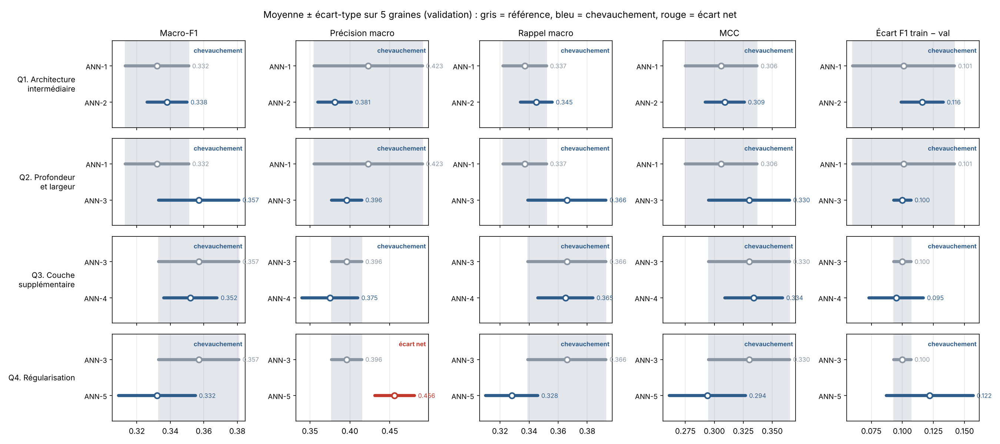


### 1.1 Interprétation de l'expérience A : comparaison des architectures

Le jeu de données étant fortement déséquilibré, l'analyse s'appuie principalement sur le Macro-F1, complété par la précision macro, le rappel macro et le MCC.

**Lecture générale.** Au vu du déséquilibre des classe, l'accuracy ne permet pas de départager les modèles, ce qui confirme le choix du Macro-F1 comme critère principal.

**1. Une architecture intermédiaire améliore-t-elle les performances ? (ANN-1 → ANN-2)**
Passer d'une couche de 32 neurones à deux couches ne modifie presque pas les performances : le Macro-F1 passe de 0,332 ± 0,019 à 0,338 ± 0,012, le rappel macro de 0,337 à 0,345 et le MCC de 0,306 à 0,309. Ces gains restent inférieurs aux écarts-types. La précision macro baisse (0,423 → 0,381), mais la forte variabilité d'ANN-1 (± 0,068) rend cette baisse fragile. L'écart de F1 entre entraînement et validation augmente légèrement (0,101 → 0,116), sans dépasser la variabilité entre graines. L'architecture intermédiaire n'apporte donc pas d'amélioration nette ; elle converge en revanche plus vite (meilleure epoch : 39 contre 80).

**2. La profondeur et la largeur améliorent-elles les performances ? (ANN-1 → ANN-3)**

L'ANN-3 obtient le meilleur Macro-F1 moyen, 0,357 ± 0,024, contre 0,332 ± 0,019 pour l'ANN-1. Le rappel macro progresse (0,337 → 0,366) ainsi que le MCC (0,306 → 0,330), tandis que la précision macro baisse légèrement  : le réseau reconnaît un peu mieux les différentes classes, au prix de quelques fausses alertes supplémentaires. Avec la stabilité entre l'ecart de l'entrainement et de validation , nous pouvons-en plus des dire- deduire donc que l'augmentation de la capacité améliore la qualité moyenne de classification.

**3. Une couche cachée supplémentaire apporte-t-elle une valeur ajoutée ? (ANN-3 → ANN-4, et ANN-1 → ANN-4)**
Nos indicateurs de réferences varient tres peu : Macro-F1 de 0,352 ± 0,016 contre 0,357 ± 0,024, rappel macro équivalent (0,365 contre 0,366), MCC à peine supérieur (0,334 contre 0,330). La profondeur supplémentaire n'a pas de valeur ajoutée sur notre modele

**4. Quel est l'effet de la régularisation ? (ANN-3 → ANN-5)**
L'ANN-5 reprend l'architecture de l'ANN-3 en ajoutant la Batch Normalization et un Dropout de 0,2 . Elle obtient la précision macro la plus élevée (0,456 contre 0,396), mais le rappel macro le plus faible (0,328 contre 0,366), et son Macro-F1 recule (0,332 contre 0,357), tout comme son MCC (0,294 contre 0,330). Le modèle devient plus « prudent » : il annonce moins souvent les classes minoritaires, mais à plus juste titre quand il le fait. 

**Synthèse.** La profondeur et la largeur apportent au mieux un gain modeste, qui plafonne dès l'ANN-3 ; la régularisation testée dans l'ANN-5 n'améliore pas les résultats. L'ANN-3 offre le meilleur compromis entre performance (Macro-F1 le plus élevé) et complexité. Toutefois, les écarts entre architectures restent du même ordre que la variabilité due à l'initialisation, et tous les modèles plafonnent à un Macro-F1 d'environ 0,35 : la limite principale ne semble pas venir de l'architecture, mais de la difficulté à reconnaître les classes minoritaires et spectralement proches.


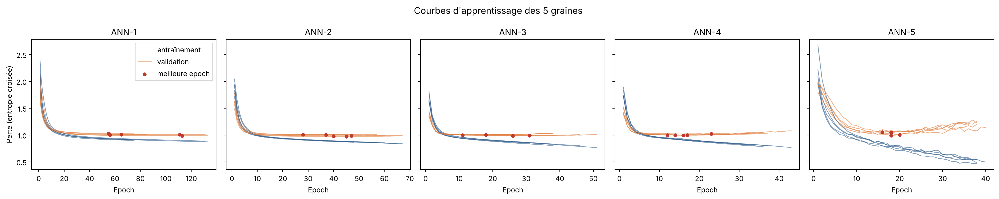

In [6]:
#  8. Graphique 1 : courbes d'apprentissage des 5 graines
# Chaque trait = un entraînement complet (pas de moyenne : les durées diffèrent à cause de
# l'arrêt anticipé). 

fig, axes = plt.subplots(1, len(ARCHITECTURES), figsize=(20, 4), sharey=True)
for ax, nom in zip(axes, ARCHITECTURES):
    for graine in GRAINES:
        h = historiques[(nom, graine)]
        epochs = np.arange(1, len(h["loss"]) + 1)
        premiere = graine == GRAINES[0]          # pour n'afficher la légende qu'une fois
        ax.plot(epochs, h["loss"], color="#2e5c8b", lw=1, alpha=0.6,
                label="entraînement" if premiere else None)
        ax.plot(epochs, h["val_loss"], color="#e07b39", lw=1, alpha=0.6,
                label="validation" if premiere else None)
        meilleure = int(np.argmin(h["val_loss"]))
        ax.scatter(meilleure + 1, h["val_loss"][meilleure], color="#c0392b", s=18, zorder=3,
                   label="meilleure epoch" if premiere else None)
    ax.set_title(nom)
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("Perte (entropie croisée)")
axes[0].legend()
fig.suptitle("Courbes d'apprentissage des 5 graines ", fontsize=13)
plt.tight_layout()
plt.show()



#### 1.2 interpretation

Chaque panneau présente, pour une architecture, l'évolution de la perte (entropie croisée) sur l'entraînement  et sur la validation pour les cinq graines.

**Comportement par architecture**
- **ANN-1** : les deux pertes diminuent rapidement puis se stabilisent ; la perte de validation reste stable autour de 1,0 sans remonter, et l'écart avec l'entraînement reste faible. Le modèle apprend lentement car ses meilleures epochs sont les plus tardives (entre 55 et 113 selon la graine).

- **ANN-2** : même profil, avec une convergence plus rapide (meilleures epochs entre 28 et 47). La perte d'entraînement continue de baisser alors que celle de validation reste stable : l'écart commence à se dessiner.
- **ANN-3** : la convergence est encore plus rapide, mais la meilleure epoch varie fortement selon la graine (entre 11 et 34 environ), ce qui montre que l'initialisation influence le moment optimal d'arrêt. En fin d'entraînement, la perte de validation remonte légèrement pendant que celle d'entraînement continue de baisser : un début de surapprentissage apparaît.
- **ANN-4** : les meilleures epochs sont précoces (entre 12 et 23) et la perte de validation remonte ensuite plus nettement (jusqu'à environ 1,07), tandis que la perte d'entraînement descend vers 0,77 : le surapprentissage commence plus tôt.
- **ANN-5** : c'est le cas le plus marqué. La perte d'entraînement chute jusqu'à environ 0,45, alors que la perte de validation remonte à partir d'une vingtaine d'epochs, les courbes sont aussi plus irrégulières. La Batch Normalization accélère l'apprentissage, mais le modèle surapprend rapidement, et le Dropout de 0,2 ne suffit pas à l'empêcher.

**synthese**

1. **Plus le réseau est profond, plus il apprend vite et plus le surapprentissage apparaît tôt.** 
2. **La graine influence l'epoch optimale.** Pour une même architecture, la meilleure epoch varie selon l'initialisation (de 11 à 34 pour l'ANN-3).
3. **La graine influence aussi la durée de l'apprentissage.** Avec certaines graines, la perte de validation continue de s'améliorer légèrement et le modèle poursuit son apprentissage ; avec d'autres, l'arrêt anticipé intervient plus tôt.


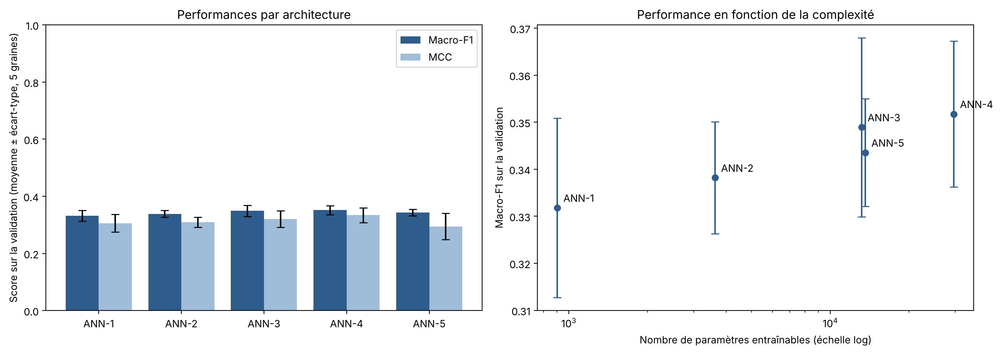

In [7]:
# 9. Graphique 2 : comparaison des performances et lien avec la complexité
# Macro-F1 (critère principal) et MCC (score global robuste au déséquilibre).
#le kappa est contesté pour l'évaluation des cartes (Foody, 2020)

moy = resultats.groupby("modele").agg(f1=("val_f1_macro", "mean"), f1_sd=("val_f1_macro", "std"),
                                      mcc=("val_mcc", "mean"), mcc_sd=("val_mcc", "std"),
                                      parametres=("parametres", "first")).loc[list(ARCHITECTURES)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(moy))
axes[0].bar(x - 0.2, moy["f1"], 0.4, yerr=moy["f1_sd"], capsize=4, label="Macro-F1", color="#2e5c8b")
axes[0].bar(x + 0.2, moy["mcc"], 0.4, yerr=moy["mcc_sd"], capsize=4, label="MCC", color="#9fbcd9")
axes[0].set_xticks(x, moy.index)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Score sur la validation (moyenne ± écart-type, 5 graines)")
axes[0].set_title("Performances par architecture")
axes[0].legend(loc="upper right")

axes[1].errorbar(moy["parametres"], moy["f1"], yerr=moy["f1_sd"], fmt="o", capsize=4, color="#2e5c8b")
for nom, ligne in moy.iterrows():
    axes[1].annotate(nom, (ligne["parametres"], ligne["f1"]), xytext=(6, 6), textcoords="offset points")
axes[1].set_xscale("log")
axes[1].set_xlabel("Nombre de paramètres entraînables (échelle log)")
axes[1].set_ylabel("Macro-F1 sur la validation")
axes[1].set_title("Performance en fonction de la complexité")
plt.tight_layout()
plt.show()

#### 1.3 Performance en fonction de la complexité
Le Macro-F1 tend à augmenter avec la complexité entre l'ANN-1 et l'ANN-3, puis plafonne : l'ANN-4, avec plus du double de paramètres, n'apporte pas de gain (0,352). Les barres d'erreur se chevauchent pour toutes les architectures. L'ANN-5 a presque le même nombre de paramètres que l'ANN-3; sa baisse de Macro-F1 (0,332) n'est donc pas liée à la complexité, mais à la régularisation ajoutée, avec laquelle le modèle surapprend plus vite.

#### 1.4 Performances par architecture
Le Macro-F1 et le MCC évoluent dans le même sens : l'ANN-3 et l'ANN-4 obtiennent les valeurs les plus élevées, l'ANN-5 les plus faibles. Les écarts entre architectures restent du même ordre que les écarts-types. Les scores restent modestes (Macro-F1 inférieur à 0,36 pour toutes les architectures) : l'architecture n'est pas le principal facteur limitant.

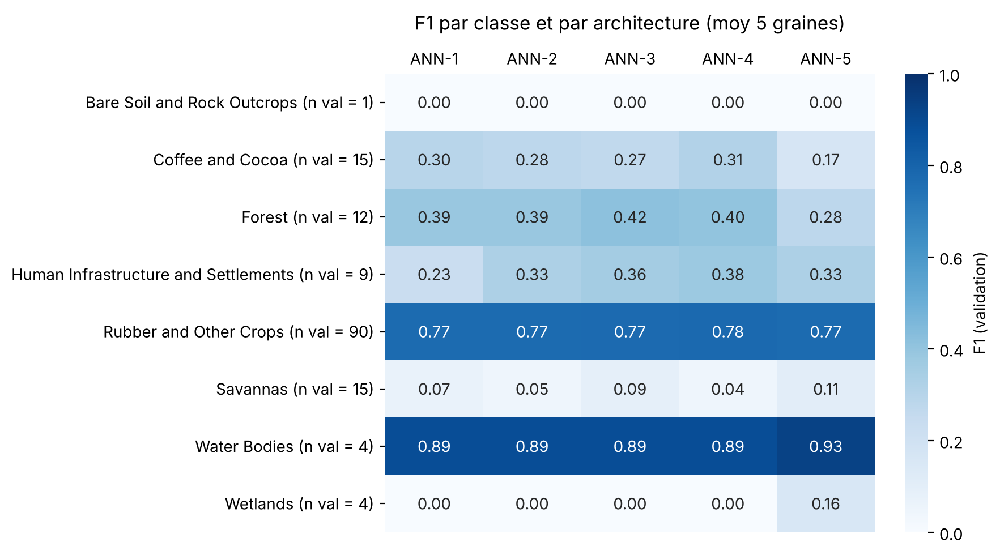

In [8]:
# F1 par classe (validation, moyenne des 5 graines)
# Permet de voir si la profondeur aide surtout les classes minoritaires ou les classes proches.

f1_classes = pd.DataFrame({nom: np.mean([f1_par_classe[(nom, g)] for g in GRAINES], axis=0)
                           for nom in ARCHITECTURES}, index=NOMS_CLASSES)
effectifs_val = pd.Series(y_val).value_counts().reindex(range(N_CLASSES), fill_value=0).to_numpy()
f1_classes.index = [f"{c} (n val = {n})" for c, n in zip(NOMS_CLASSES, effectifs_val)]

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(f1_classes, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "F1 (validation)"})
ax.xaxis.tick_top()                     # noms des architectures au-dessus du graphique
ax.tick_params(axis="x", length=0)
ax.set_title("F1 par classe et par architecture (moy 5 graines)", pad=28)
plt.tight_layout()
plt.show()
# certaines classes n'ont que 1 à 4 observations en validation
# leur F1 est très instable.


Les classes Bare Soil and Rock Outcrops et Wetlands ne sont reconnues par aucune architecture : leur F1 reste nul quelle que soit la complexité du réseau, à l’exception d’un 0,08 pour Wetlands avec l’ANN-5. Deux raisons l’expliquent. D’abord, elles disposent de très peu d’observations : 5 en entraînement et 1 en validation pour Bare Soil, 19 et 4 pour Wetlands. Le réseau a trop peu d’exemples pour les apprendre, et un seul point mal classé en validation suffit à annuler le F1. Ensuite, l’analyse exploratoire a montré que leurs signatures se confondent avec celles d’autres classes : Bare Soil est spectralement proche du bâti, et Wetlands, qui mélange eau, sol saturé et végétation, est la classe la plus dispersée.

Savannas est aussi presque jamais reconnue (F1 de 0,04 à 0,11), bien qu’elle compte 102 observations. Ici, l’effectif n’est donc pas en cause : sur le plan factoriel de l’ACP, la savane s’étale sur tout le nuage, comme Rubber, sans zone propre. Le réseau la confond avec la classe majoritaire.

Pour Forest et Coffee and Cocoa, le F1 varie peu de l’ANN-1 à l’ANN-4 (environ 0,40 et 0,30), puis recule avec l’ANN-5 (0,25 et 0,19), le modèle régularisé qui surapprend le plus. Ces deux classes occupent la même zone du plan factoriel (même vigueur végétale, même humidité) et ont des signatures très proches, ce qui limite leur séparation.

Deux classes sortent du lot, avec des F1 élevés et stables quelle que soit l’architecture : Water Bodies (0,89 à 0,91) et Rubber and Other Crops (0,77 à 0,78). Water Bodies a la signature spectrale la plus isolée  et elle est fortement regroupée autour du lac. Son F1 repose toutefois sur 4 observations de validation. 

La seule classe qui profite réellement de l’augmentation de la complexité est Human Infrastructure, dont le F1 passe de 0,23 (ANN-1) à 0,40 (ANN-3)

#### 1.5 Architecture retenue 

 À l'issue de l'expérience A, c'est ANN-3 est le plus petit modèle qui atteint le plateau de performance :
- L'ANN-1 est une référence trop simple, moins performante.
- L'ANN-2 converge plus vite mais son architecture intermédiaire n'apporte pas d'amélioration nette.
- l'ANN-4, avec plus du double de paramètres, n'apporte pas de gain. 
- L'ANN-5 surapprend rapidement.

### 2. EXPÉRIENCE B : comparaison des Optimiseurs
#### Objectif :  comparer cinq optimiseurs pour entraîner le même réseau, et voir lequel donne le modèle qui généralise le mieux. 

#### Principe directeur : une seule architecture, la même fonction de perte, les mêmes partitions et le même budget maximal d’époques. La même pour les cinq optimiseurs.
#### Les critères de comparaison seront : 
   - la performance sur l’ensemble de validation ; 
   - le nombre d’époques nécessaires à la convergence ; 
   - la stabilité des courbes de perte ; 
   - le temps d’entraînement ; 
   - l’écart entre les performances d’entraînement et de validation. 


#### 2.1 Paramètres de l'expérience B

In [9]:

# On réutilise ce qui a été défini pour l'expérience A : X_train, X_val, y_train, y_val, ARCHITECTURES,
# construire_modele, calculer_metriques, GRAINES, EPOCHS_MAX, PATIENCE, TAILLE_LOT.

ARCHI_B = "ANN-3"                                 # architecture retenue 


print(f"Architecture : {ARCHI_B} {ARCHITECTURES[ARCHI_B]}")
print(f"Train : {len(y_train)} | Validation : {len(y_val)} | Graines : {GRAINES}")
print(f"Budget : {EPOCHS_MAX} epochs max, patience {PATIENCE}, lots de {TAILLE_LOT}")

Architecture : ANN-3 [128, 64, 32]
Train : 700 | Validation : 150 | Graines : [0, 1, 2, 3, 4]
Budget : 200 epochs max, patience 20, lots de 32


In [10]:
# B.1 Fonctions de l'expérience B

def creer_optimiseur(nom, params):
    """Crée un nouvel optimiseur Keras. Les paramètres non précisés gardent leur valeur par défaut."""
    if nom in ("SGD", "SGD + Momentum"):
        return keras.optimizers.SGD(learning_rate=params["lr"], momentum=params.get("momentum", 0.0))
    if nom == "Adam":
        return keras.optimizers.Adam(learning_rate=params["lr"])          # beta_1, beta_2, epsilon par défaut
    if nom == "RMSprop":
        return keras.optimizers.RMSprop(learning_rate=params["lr"])       # rho, epsilon par défaut
    if nom == "AdamW":
        return keras.optimizers.AdamW(learning_rate=params["lr"], weight_decay=params["weight_decay"])
    raise ValueError(f"Optimiseur inconnu : {nom}")


def etiquette(params):
    """Nom lisible d'une configuration, par exemple 'lr=0.001, wd=0.004'."""
    noms = {"lr": "lr", "momentum": "momentum", "weight_decay": "wd"}
    return ", ".join(f"{noms[k]}={v:g}" for k, v in params.items())


def instabilite(pertes_val):
    """Mesure des oscillations de la perte de validation.
    On retire la tendance (mediane mobile sur 5 epochs) et on garde l'écart moyen à cette tendance :
    plus la valeur est grande, plus la courbe oscille."""
    p = pd.Series(pertes_val).dropna()
    tendance = p.rolling(5, center=True, min_periods=1).median()
    return float((p - tendance).abs().mean())


def entrainer_config(optimiseur, params, graine):
    """Entraîne l'ANN-3 avec un optimiseur et une graine, et renvoie les indicateurs."""
    keras.utils.set_random_seed(graine)        # même graine -> mêmes poids de départ pour tous les optimiseurs
    modele = construire_modele(ARCHI_B, ARCHITECTURES[ARCHI_B])     # même construction que dans l'expérience A
    modele.compile(optimizer=creer_optimiseur(optimiseur, params),  # seul l'optimiseur change
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])

    temps_epochs = []                                  # temps écoulé a la fin de chaque epoque
    rappels = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                             restore_best_weights=True),
               keras.callbacks.TerminateOnNaN(),      # arrête l'entraînement si y'a divergence 
               keras.callbacks.LambdaCallback(        # chronomètre : note le temps à la fin de chaque epoch
                   on_epoch_end=lambda epoch, logs: temps_epochs.append(time.perf_counter() - debut))]
    debut = time.perf_counter()
    hist = modele.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=EPOCHS_MAX, batch_size=TAILLE_LOT, callbacks=rappels, verbose=0)
    duree = time.perf_counter() - debut

    pertes_val = np.array(hist.history["val_loss"], dtype=float)
    diverge = bool(np.isnan(pertes_val).any() or np.isnan(hist.history["loss"]).any())
    pred_train = modele.predict(X_train, verbose=0).argmax(axis=1)
    pred_val = modele.predict(X_val, verbose=0).argmax(axis=1)
    m_train = calculer_metriques(y_train, pred_train)
    m_val = calculer_metriques(y_val, pred_val)

    ligne = {
        "optimiseur": optimiseur, "config": etiquette(params), "graine": graine, **params,
        "epochs_effectuees": len(pertes_val),
        # Convergence : epoch où la perte de validation est minimale 
        "meilleure_epoch": int(np.nanargmin(pertes_val)) + 1 if not np.isnan(pertes_val).all() else np.nan,
        "temps_s": duree,
        "perte_val": float(np.nanmin(pertes_val)) if not np.isnan(pertes_val).all() else np.nan,
        "instabilite_val": instabilite(pertes_val),
        "diverge": diverge,
        **{f"val_{k}": v for k, v in m_val.items()},
        "train_f1_macro": m_train["f1_macro"],
        "ecart_f1_train_val": m_train["f1_macro"] - m_val["f1_macro"],   # généralisation, plus il est faible plus le modele generalise bien
    }
    f1_classes = f1_score(y_val, pred_val, average=None, labels=range(N_CLASSES), zero_division=0)
    historique = dict(hist.history)
    historique["temps_cumule"] = temps_epochs          # ajouté aux courbes pour le graphique en fonction du temps
    return ligne, historique, f1_classes


# Stockage de tous les entraînements
reglage = []            # une ligne par (optimiseur, configuration, graine)
historiques_B = {}      # courbes d'apprentissage
f1_par_classe_B = {}    # F1 de chaque classe sur la validation
CONFIGS = {}            # (optimiseur, configuration) -> paramètres


def lancer(optimiseur, params):
    """Entraîne une configuration avec les 5 graines (sauf si elle a déjà été entraînée)."""
    config = etiquette(params)
    if (optimiseur, config) in CONFIGS:
        return
    CONFIGS[(optimiseur, config)] = params
    for graine in GRAINES:
        ligne, histo, f1c = entrainer_config(optimiseur, params, graine)
        reglage.append(ligne)
        historiques_B[(optimiseur, config, graine)] = histo
        f1_par_classe_B[(optimiseur, config, graine)] = f1c
        print(f"{optimiseur:15s} | {config:22s} | graine {graine} | {ligne['epochs_effectuees']:3d} epochs | "
              f"Macro-F1 val = {ligne['val_f1_macro']:.3f} | {ligne['temps_s']:.1f} s"
              + (" | DIVERGENCE" if ligne["diverge"] else ""))


def meilleure_config(optimiseur):
    """Configuration de meilleur Macro-F1 moyen (5 graines) sur la validation."""
    d = pd.DataFrame(reglage)
    return d[d["optimiseur"] == optimiseur].groupby("config")["val_f1_macro"].mean().idxmax()

#####  2.2 Réglage du taux d'apprentissage (SGD, Adam, RMSprop, AdamW)

Chaque optimiseur a son propre bon taux d’apprentissage. Le comparer avec un seul taux commun serait donc injuste.                Ici nous testons 3 taux d’apprentissage pour chacun des quatre optimiseurs SGD, Adam, RMSprop et AdamW, chacun avec les 5 graines et on retient les meilleurs. puis nous passons au choix du second parametre (AdamW et SGD + Momentum)

In [11]:
#l’effet du taux d’apprentissage dépend de son ordre de grandeur plutôt que de sa valeur exacte 

WD_DEFAUT = 0.004                                     
GRILLES_LR = {
    "SGD":     [0.001, 0.01, 0.1],                    
    "Adam":    [0.0001, 0.001, 0.01],                 
    "RMSprop": [0.0001, 0.001, 0.01],                
    "AdamW":   [0.0001, 0.001, 0.01],                 
}

for optimiseur, valeurs in GRILLES_LR.items():
    for lr in valeurs:
        params = {"lr": lr, "weight_decay": WD_DEFAUT} if optimiseur == "AdamW" else {"lr": lr}
        lancer(optimiseur, params)

SGD             | lr=0.001               | graine 0 | 200 epochs | Macro-F1 val = 0.224 | 35.9 s
SGD             | lr=0.001               | graine 1 | 200 epochs | Macro-F1 val = 0.232 | 37.8 s
SGD             | lr=0.001               | graine 2 | 200 epochs | Macro-F1 val = 0.207 | 36.7 s
SGD             | lr=0.001               | graine 3 | 200 epochs | Macro-F1 val = 0.262 | 42.6 s
SGD             | lr=0.001               | graine 4 | 200 epochs | Macro-F1 val = 0.249 | 66.7 s
SGD             | lr=0.01                | graine 0 | 198 epochs | Macro-F1 val = 0.421 | 64.5 s
SGD             | lr=0.01                | graine 1 | 192 epochs | Macro-F1 val = 0.346 | 57.8 s
SGD             | lr=0.01                | graine 2 | 190 epochs | Macro-F1 val = 0.332 | 60.7 s
SGD             | lr=0.01                | graine 3 | 176 epochs | Macro-F1 val = 0.425 | 55.0 s
SGD             | lr=0.01                | graine 4 | 196 epochs | Macro-F1 val = 0.357 | 53.8 s
SGD             | lr=0.1      

In [12]:
# Réglage du second paramètre : momentum (SGD + Momentum) et weight_decay (AdamW)

# SGD + Momentum : on part du taux d'apprentissage retenu pour SGD, seul le momentum change
lr_sgd = CONFIGS[("SGD", meilleure_config("SGD"))]["lr"]
print(f"Taux retenu pour SGD : {lr_sgd:g}")
for mu in [0.5, 0.9, 0.99]:
    lancer("SGD + Momentum", {"lr": lr_sgd, "momentum": mu})

# AdamW : on part du taux d'apprentissage retenu, seul le weight_decay change
lr_adamw = CONFIGS[("AdamW", meilleure_config("AdamW"))]["lr"]
print(f"Taux retenu pour AdamW : {lr_adamw:g}")
for wd in [0.0004, 0.004, 0.04]:
    lancer("AdamW", {"lr": lr_adamw, "weight_decay": wd})    # la valeur par défaut déjà entraînée est sautée

reglage_df = pd.DataFrame(reglage)

Taux retenu pour SGD : 0.01
SGD + Momentum  | lr=0.01, momentum=0.5  | graine 0 |  98 epochs | Macro-F1 val = 0.346 | 13.0 s
SGD + Momentum  | lr=0.01, momentum=0.5  | graine 1 | 111 epochs | Macro-F1 val = 0.374 | 14.1 s
SGD + Momentum  | lr=0.01, momentum=0.5  | graine 2 | 107 epochs | Macro-F1 val = 0.329 | 13.8 s
SGD + Momentum  | lr=0.01, momentum=0.5  | graine 3 |  94 epochs | Macro-F1 val = 0.425 | 11.2 s
SGD + Momentum  | lr=0.01, momentum=0.5  | graine 4 | 120 epochs | Macro-F1 val = 0.332 | 14.0 s
SGD + Momentum  | lr=0.01, momentum=0.9  | graine 0 |  47 epochs | Macro-F1 val = 0.338 | 6.1 s
SGD + Momentum  | lr=0.01, momentum=0.9  | graine 1 |  38 epochs | Macro-F1 val = 0.367 | 5.0 s
SGD + Momentum  | lr=0.01, momentum=0.9  | graine 2 |  36 epochs | Macro-F1 val = 0.369 | 6.0 s
SGD + Momentum  | lr=0.01, momentum=0.9  | graine 3 |  47 epochs | Macro-F1 val = 0.362 | 6.2 s
SGD + Momentum  | lr=0.01, momentum=0.9  | graine 4 |  29 epochs | Macro-F1 val = 0.334 | 4.3 s
SGD + M

In [13]:
# Tableau du réglage : moyenne ± écart-type sur les 5 graines, pour chaque configuration testée

OPTIMISEURS = ["SGD", "SGD + Momentum", "Adam", "RMSprop", "AdamW"]
RETENUES = {opt: meilleure_config(opt) for opt in OPTIMISEURS}      # configuration retenue par optimiseur

tab_reglage = (reglage_df.groupby(["optimiseur", "config"], sort=False)
               .agg(f1_moy=("val_f1_macro", "mean"), f1_sd=("val_f1_macro", "std"),
                    meilleure_epoch=("meilleure_epoch", "mean"), divergences=("diverge", "sum"))
               .reset_index())
tab_reglage["Macro-F1 val"] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(tab_reglage["f1_moy"], tab_reglage["f1_sd"])]
tab_reglage["retenue"] = [("oui" if RETENUES[o] == c else "") for o, c in zip(tab_reglage["optimiseur"], tab_reglage["config"])]
tab_reglage = tab_reglage[["optimiseur", "config", "Macro-F1 val", "meilleure_epoch", "divergences", "retenue"]]

#### 2.3 Macro-F1 selon la valeur du paramètre réglé (moyenne ± écart-type, 5 graines)

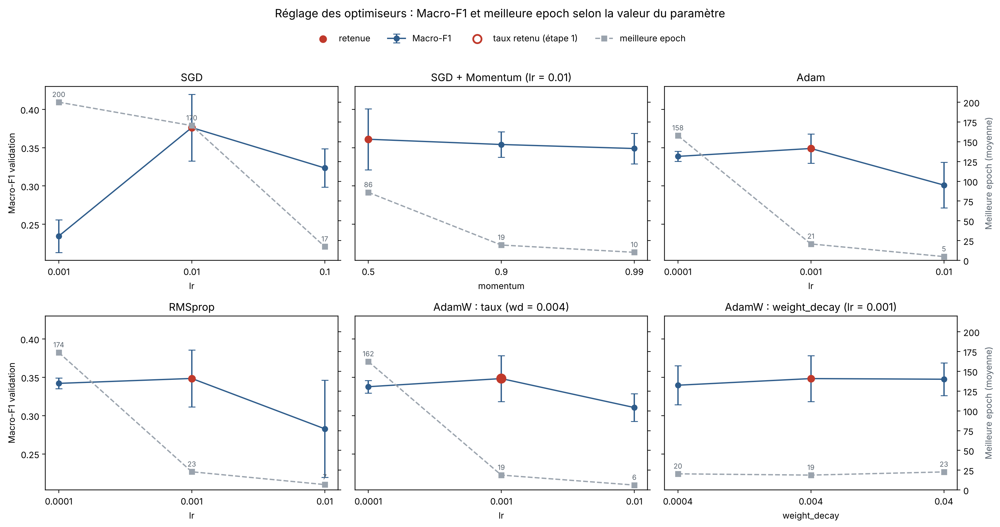

In [14]:
 
# Le point rouge indique la configuration retenue.

def tracer_reglage(ax, optimiseur, parametre, filtre=None, titre=None):
    d = reglage_df[reglage_df["optimiseur"] == optimiseur]
    if filtre is not None:
        d = d[filtre(d)]
    g = d.groupby(parametre).agg(f1=("val_f1_macro", "mean"), f1_sd=("val_f1_macro", "std"),
                                 ep=("meilleure_epoch", "mean")).sort_index()
    x = np.arange(len(g))                                   # positions régulières, valeurs en étiquettes

    # Axe de gauche : Macro-F1 moyen ± écart-type
    ax.errorbar(x, g["f1"], yerr=g["f1_sd"], fmt="o-", capsize=4, color="#2e5c8b", label="Macro-F1")
    if RETENUES[optimiseur] in d["config"].values:          # la configuration retenue est-elle dans ce panneau ?
        i = list(g.index).index(CONFIGS[(optimiseur, RETENUES[optimiseur])][parametre])
        ax.scatter(i, g["f1"].iloc[i], color="#c0392b", s=60, zorder=3, label="retenue")

    # Axe de droite : meilleure epoch moyenne (convergence)
    ax2 = ax.twinx()
    ax2.plot(x, g["ep"], "s--", color="#9aa3ad", label="meilleure epoch")
    for xi, e in zip(x, g["ep"]):
        ax2.annotate(f"{e:.0f}", (xi, e), xytext=(0, 6), textcoords="offset points",
                     ha="center", fontsize=8, color="#55606b")
    ax2.set_ylim(0, EPOCHS_MAX + 20)                         # même échelle pour tous les panneaux

    ax.set_xticks(x, [f"{v:g}" for v in g.index])
    ax.set_xlabel(parametre)
    ax.set_title(titre or optimiseur)
    return g, ax2

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), sharey=True)
_, ax2_sgd = tracer_reglage(axes[0, 0], "SGD", "lr")
_, ax2_mom = tracer_reglage(axes[0, 1], "SGD + Momentum", "momentum", titre=f"SGD + Momentum (lr = {lr_sgd:g})")
_, ax2_adam = tracer_reglage(axes[0, 2], "Adam", "lr")
_, ax2_rms = tracer_reglage(axes[1, 0], "RMSprop", "lr")
g_aw, ax2_aw = tracer_reglage(axes[1, 1], "AdamW", "lr", filtre=lambda d: d["weight_decay"] == WD_DEFAUT,
                              titre=f"AdamW : taux (wd = {WD_DEFAUT:g})")
_, ax2_wd = tracer_reglage(axes[1, 2], "AdamW", "weight_decay", filtre=lambda d: d["lr"] == lr_adamw,
                           titre=f"AdamW : weight_decay (lr = {lr_adamw:g})")

# AdamW : cercle rouge sur le taux retenu à l'étape 1 (avant le réglage du weight_decay)
i = list(g_aw.index).index(lr_adamw)
axes[1, 1].scatter(i, g_aw["f1"].iloc[i], s=90, facecolors="none", edgecolors="#c0392b", linewidths=2,
                   zorder=4, label="taux retenu (étape 1)")

for ax in axes[:, 0]:
    ax.set_ylabel("Macro-F1 validation")
for ax2 in [ax2_sgd, ax2_mom, ax2_rms, ax2_aw]:
    ax2.tick_params(labelright=False)                        # graduations de droite seulement sur la dernière colonne
for ax2 in [ax2_adam, ax2_wd]:
    ax2.set_ylabel("Meilleure epoch (moyenne)", color="#55606b")

# Légende commune placée sous le titre 
h1, l1 = axes[0, 0].get_legend_handles_labels()              # Macro-F1, retenue
h2, l2 = axes[1, 1].get_legend_handles_labels()              # taux retenu (étape 1)
h3, l3 = ax2_sgd.get_legend_handles_labels()                 # meilleure epoch
poignees = dict(zip(l1 + l2 + l3, h1 + h2 + h3))             # dictionnaire : évite les doublons
fig.legend(poignees.values(), poignees.keys(), loc="upper center", ncol=4,
           bbox_to_anchor=(0.5, 0.945), frameon=False, fontsize=10)

fig.suptitle("Réglage des optimiseurs : Macro-F1 et meilleure epoch selon la valeur du paramètre", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.92])                       # laisse de la place en haut pour la légende
plt.show()

Le taux d’apprentissage est le paramètre qui influence le plus le Macro-F1, en particulier pour SGD (de 0,235 à 0,376). Pour Adam, RMSprop et AdamW, le taux de 0,01 donne les scores les plus faibles par contre le taux de 0.001 permet d'avoir un macro-F1 elévé. L’ajout du momentum à SGD n’améliore pas le Macro-F1 en validation mais permet d'accélèrer surtout la convergence (meilleure epoch de 173 sans momentum à 10 avec un momentum de 0,99). De même, le weight_decay d’AdamW fait peu varier le Macro-F1 (de 0,340 à 0,347).

#### 2.4 Comparaison des optimiseurs retenus


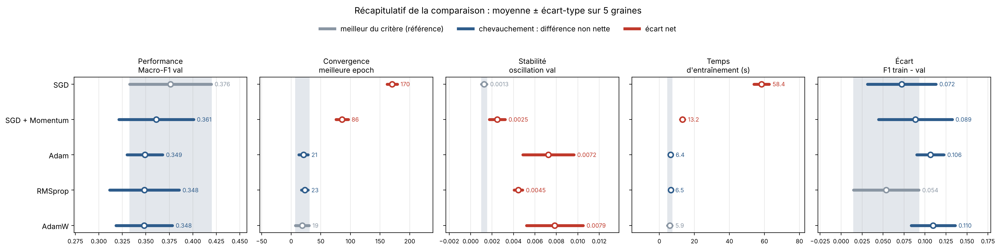

In [15]:
# Tableau récapitulatif des optimiseurs retenus (validation, moyenne ± écart-type sur 5 graines)


garder = [(o, RETENUES[o]) for o in OPTIMISEURS]
resultats_B = reglage_df[[(o, c) in garder for o, c in zip(reglage_df["optimiseur"], reglage_df["config"])]].copy()

colonnes_B = ["val_f1_macro", "val_mcc", "val_accuracy", "val_precision_macro", "val_recall_macro",
              "val_f1_pondere", "ecart_f1_train_val", "meilleure_epoch", "epochs_effectuees",
              "instabilite_val", "temps_s"]
recap_B = resultats_B.groupby("optimiseur")[colonnes_B].agg(["mean", "std"]).loc[OPTIMISEURS]

tableau_B = pd.DataFrame(index=recap_B.index)
tableau_B["Configuration"] = [RETENUES[o] for o in OPTIMISEURS]
for c in colonnes_B:
    dec = 0 if c in ("meilleure_epoch", "epochs_effectuees") else (1 if c == "temps_s" else 3)
    tableau_B[c] = [f"{m:.{dec}f} ± {s:.{dec}f}" for m, s in zip(recap_B[(c, "mean")], recap_B[(c, "std")])]


criteres_chev = [  # (colonne, titre, format, sens : True = plus grand est meilleur)
    ("val_f1_macro", "Performance\nMacro-F1 val", ".3f", True),
    ("meilleure_epoch", "Convergence\nmeilleure epoch", ".0f", False),
    ("instabilite_val", "Stabilité\noscillation val", ".4f", False),
    ("temps_s", "Temps\nd'entraînement (s)", ".1f", False),
    ("ecart_f1_train_val", "Écart\nF1 train - val", ".3f", False),
]
stats_chev = resultats_B.groupby("optimiseur")[[c for c, _, _, _ in criteres_chev]].agg(["mean", "std"]).loc[OPTIMISEURS]

fig, axes = plt.subplots(1, len(criteres_chev), figsize=(19, 4.8), sharey=True)
y = np.arange(len(OPTIMISEURS))[::-1]                        # premier optimiseur en haut
for ax, (col, titre, fmt, plus_grand_meilleur) in zip(axes, criteres_chev):
    m, s = stats_chev[(col, "mean")], stats_chev[(col, "std")]
    meilleur = m.idxmax() if plus_grand_meilleur else m.idxmin()
    bas_ref, haut_ref = m[meilleur] - s[meilleur], m[meilleur] + s[meilleur]
    ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")             # bande de référence
    for yi, opt in zip(y, OPTIMISEURS):
        bas, haut = m[opt] - s[opt], m[opt] + s[opt]
        if opt == meilleur:
            c = "#8a96a3"
        else:
            chevauche = bas <= haut_ref and haut >= bas_ref
            c = "#2e5c8b" if chevauche else "#c0392b"
        ax.plot([bas, haut], [yi, yi], color=c, lw=4, solid_capstyle="round")
        ax.plot(m[opt], yi, "o", color="white", mec=c, mew=2, ms=7)
        ax.text(haut, yi, f"  {m[opt]:{fmt}}", va="center", fontsize=8, color=c)
    ax.set_title(titre, fontsize=10)
    ax.margins(x=0.35)                                         # place pour les valeurs à droite
    ax.grid(axis="x", alpha=0.3)
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_yticks(y, OPTIMISEURS)

legende = [Line2D([0], [0], color="#8a96a3", lw=4, label="meilleur du critère (référence)"),
           Line2D([0], [0], color="#2e5c8b", lw=4, label="chevauchement : différence non nette"),
           Line2D([0], [0], color="#c0392b", lw=4, label="écart net")]
fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.93), frameon=False, fontsize=10)
fig.suptitle("Récapitulatif de la comparaison : moyenne ± écart-type sur 5 graines", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.show()



Au regard des critères de comparaison, aucun optimiseur n’arrive en tête sur tous les critères, compte tenu du sens de lecture de chacun (plus haut est meilleur pour le Macro-F1, plus bas est meilleur pour les autres).

Résumé par optimiseur

SGD : il a le meilleur Macro-F1 moyen (0,376), mais avec l’écart-type le plus grand (± 0,043), et tous les autres optimiseurs le chevauchent. En revanche, il converge nettement le plus lentement (meilleure epoch 173, proche du budget de 200) et c’est le plus long à entraîner (73 s). Son écart entraînement / validation (0,073) chevauche celui du meilleur.

SGD + Momentum : son Macro-F1 (0,361) chevauche celui de SGD. Le momentum divise par deux la convergence (86 epochs) et le temps (39,9 s) par rapport à SGD, mais il reste nettement plus lent que les optimiseurs adaptatifs. Ses courbes sont un peu moins stables que SGD, mais nettement plus que les optimiseurs adaptatifs. Son écart entraînement / validation (0,090) chevauche celui du meilleur.

Adam : son Macro-F1 (0,357) chevauche celui des autres. Il converge le plus vite (21 epochs), et son temps (20,3 s) chevauche celui de RMSprop. Ses courbes sont nettement les moins stables (0,0072). Son écart entraînement / validation (0,100) est le seul « écart net » face à RMSprop, mais il est très régulier d’une graine à l’autre (± 0,007).

RMSprop : il a le Macro-F1 moyen le plus bas (0,346), sans écart net avec les autres. Il converge aussi vite qu’Adam (21 epochs) et c’est le plus rapide en temps (15,4 s). Sa stabilité est intermédiaire (0,0046), nettement moins bonne que celle de SGD. Il a le plus petit écart entraînement / validation (0,046), mais avec un écart-type presque aussi grand que la valeur (± 0,044) : ce résultat est donc peu fiable.

AdamW : il se comporte presque comme Adam. Son Macro-F1 (0,347), sa convergence (23 epochs) et son temps (22,4 s) chevauchent tous la référence. Ses courbes sont aussi instables que celles d’Adam (0,0071). Son écart entraînement / validation (0,101) est presque identique à celui d’Adam : le weight_decay retenu n’a pas réduit cet écart.

En résumé : sur le critère principal, le Macro-F1 en validation, aucun optimiseur ne se distingue nettement. Les écarts nets portent sur la vitesse de convergence, le temps d’entraînement et la stabilité des courbes, qui ne doivent servir qu’à départager. analysons les courbes d'apprentissage

 #### 2.5 courbes d'apprentissage des 5 graines pour chaque optimiseur retenu

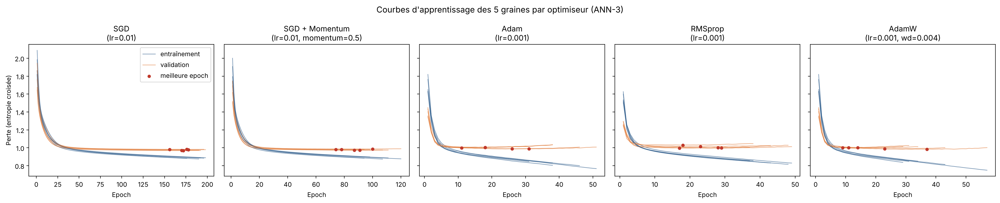

In [16]:


fig, axes = plt.subplots(1, len(OPTIMISEURS), figsize=(22, 4.5), sharey=True)
for ax, opt in zip(axes, OPTIMISEURS):
    for graine in GRAINES:
        h = historiques_B[(opt, RETENUES[opt], graine)]
        epochs = np.arange(1, len(h["loss"]) + 1)
        premiere = graine == GRAINES[0]                 # légende affichée une seule fois
        ax.plot(epochs, h["loss"], color="#2e5c8b", lw=1, alpha=0.6,
                label="entraînement" if premiere else None)
        ax.plot(epochs, h["val_loss"], color="#e07b39", lw=1, alpha=0.6,
                label="validation" if premiere else None)
        meilleure = int(np.nanargmin(h["val_loss"]))
        ax.scatter(meilleure + 1, h["val_loss"][meilleure], color="#c0392b", s=18, zorder=3,
                   label="meilleure epoch" if premiere else None)
    ax.set_title(f"{opt}\n({RETENUES[opt]})")
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("Perte (entropie croisée)")
axes[0].legend()
fig.suptitle("Courbes d'apprentissage des 5 graines par optimiseur (ANN-3)", fontsize=13)
plt.tight_layout()
plt.show()

Avec SGD et SGD + Momentum, les courbes sont les plus régulières : les pertes d’entraînement et de validation diminuent ensemble et restent proches, et la perte de validation ne remonte pas. SGD + Momentum converge environ deux fois plus vite que SGD (meilleure epoch d’environ 86 contre 173). Avec Adam, RMSprop et AdamW, la convergence est beaucoup plus rapide (une vingtaine d’epochs), mais la perte d’entraînement continue de baisser alors que la perte de validation se stabilise puis remonte légèrement : un début de surapprentissage apparaît, interrompu par l’arrêt anticipé. Comme dans l’expérience A, l’initialisation influence le moment optimal d’arrêt, surtout pour les optimiseurs adaptatifs (meilleure epoch d’environ 11 à 34 selon la graine pour Adam), alors qu’elle varie peu pour SGD.


#### 2.6 F1 par classe et par optimiseur (validation, moyenne des 5 graines)

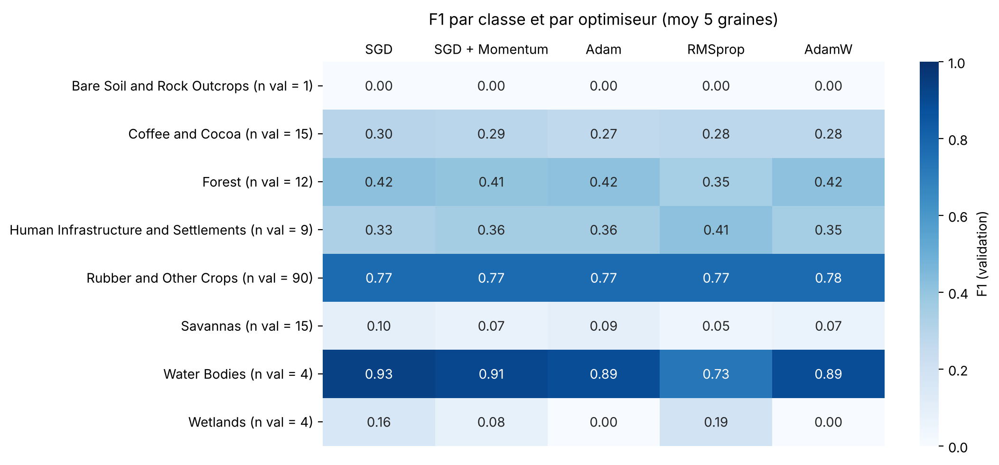

In [17]:
 


f1_classes_B = pd.DataFrame({opt: np.mean([f1_par_classe_B[(opt, RETENUES[opt], g)] for g in GRAINES], axis=0)
                             for opt in OPTIMISEURS}, index=NOMS_CLASSES)
effectifs_val_B = pd.Series(y_val).value_counts().reindex(range(N_CLASSES), fill_value=0).to_numpy()
f1_classes_B.index = [f"{c} (n val = {n})" for c, n in zip(NOMS_CLASSES, effectifs_val_B)]

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(f1_classes_B, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "F1 (validation)"})
ax.xaxis.tick_top()                     # noms des optimiseurs au-dessus du graphique
ax.tick_params(axis="x", length=0)
ax.set_title("F1 par classe et par optimiseur (moy 5 graines)", pad=28)
plt.tight_layout()
plt.show()
# certaines classes n'ont que 1 à 4 observations en validation : leur F1 est très instable.

Comme dans l’expérience A, Bare Soil and Rock Outcrops n’est reconnue par aucun optimiseur (F1 nul), et Savannas presque jamais (F1 de 0,05 à 0,09). Water Bodies et Rubber and Other Crops restent les classes les mieux reconnues, et Forest et Coffee and Cocoa gardent des F1 modestes et proches d’un optimiseur à l’autre. Le changement d’optimiseur ne modifie donc pas le profil des classes : les difficultés viennent des données (classes peu représentées ou spectralement confondues, mises en évidence par l’analyse exploratoire), pas de l’algorithme d’optimisation. 

Les seules différences visibles concernent des classes à très faible effectif en validation : Wetlands (de 0 avec Adam et AdamW à 0,19 avec RMSprop) et Water Bodies (0,73 avec RMSprop), qui ne comptent que 4 observations chacune. Une seule observation bien ou mal classée suffit à créer ces écarts, qui ne peuvent donc pas être attribués à l’optimiseur.

#### 2.7 synthese de l’expérience B

 Avec la même architecture (ANN-3), la même fonction de perte, les mêmes partitions et le même budget d’epochs, le choix de l’optimiseur ne modifie pas nettement la qualité de la généralisation : les Macro-F1 en validation vont de 0,346 à 0,376 et leurs intervalles (moyenne ± écart-type) se chevauchent tous. Les différences nettes portent sur les critères secondaires. 
 
 SGD a les courbes les plus stables, mais converge le plus lentement (environ 173 epochs, près du budget) et prend le plus de temps ; le momentum divise ces deux valeurs par deux. 
 
 Les optimiseurs adaptatifs (Adam, RMSprop, AdamW) convergent en une vingtaine d’epochs, avec un début de surapprentissage interrompu par l’arrêt anticipé. 
 
 Le profil des classes reste le même quel que soit l’optimiseur : les difficultés viennent des données, pas de l’algorithme d’optimisation.

 L’optimiseur SGD + Momentum (taux de 0,01, momentum de 0,5) est retenu pour la suite : à performance équivalente en validation, il présente des courbes d’apprentissage régulières, sans remontée de la perte de validation, et converge dans le budget d’epochs fixé.

### 3. EXPÉRIENCE C : comparaison des fonctions d'activation
#### Objectif : mesurer l'effet de la fonction d'activation des couches cachées sur la classification de l'occupation du sol.

#### Principe directeur : une seule composante change, l'activation des couches cachées. La softmax est conservée en sortie.



#### 3.1 Paramètres de l'expérience C



In [18]:
  
# On réutilise ce qui a été défini pour l'expérience A : X_train, X_val, y_train, y_val, ARCHITECTURES,
# calculer_metriques, GRAINES, EPOCHS_MAX, PATIENCE, TAILLE_LOT, NOMS_CLASSES, N_CLASSES.


ARCHI_C = "ANN-3"          # architecture retenue à l'issue de l'expérience A
LR_C = 0.01                # optimiseur retenu à l'issue de l'expérience B : SGD + Momentum
MOMENTUM_C = 0.5
PENTE_LEAKY = 0.01         # petite pente de Leaky ReLU pour les entrées négatives (Maas et al., 2013)

ACTIVATIONS = ["ReLU", "Leaky ReLU", "Tanh", "GELU"]   # ReLU = référence principale


print(f"Architecture : {ARCHI_C} {ARCHITECTURES[ARCHI_C]} | SGD + Momentum (lr = {LR_C}, momentum = {MOMENTUM_C})")
print(f"Activations comparées : {ACTIVATIONS} | Graines : {GRAINES}")

Architecture : ANN-3 [128, 64, 32] | SGD + Momentum (lr = 0.01, momentum = 0.5)
Activations comparées : ['ReLU', 'Leaky ReLU', 'Tanh', 'GELU'] | Graines : [0, 1, 2, 3, 4]


In [19]:
# C.1 Fonctions de l'expérience C

def couche_activation(nom):
    """Renvoie la couche d'activation correspondant au nom."""
    if nom == "ReLU":
        return layers.Activation("relu")
    if nom == "Leaky ReLU":
        return layers.LeakyReLU(negative_slope=PENTE_LEAKY)
    if nom == "Tanh":
        return layers.Activation("tanh")
    if nom == "GELU":
        return layers.Activation("gelu")
    raise ValueError(f"Activation inconnue : {nom}")


def construire_ann3(activation):
    """ANN-3 (19 -> 128 -> 64 -> 32 -> 8) avec l'activation choisie dans les couches cachées.
    Chaque couche cachée = Dense (sans activation) puis la couche d'activation """
    modele = keras.Sequential(name=f"ANN_3_{activation.replace(' ', '_')}")
    modele.add(keras.Input(shape=(len(VARIABLES),)))
    for n in ARCHITECTURES[ARCHI_C]:
        modele.add(layers.Dense(n))
        modele.add(couche_activation(activation))
    modele.add(layers.Dense(N_CLASSES, activation="softmax"))          # softmax conservée en sortie
    modele.compile(optimizer=keras.optimizers.SGD(learning_rate=LR_C, momentum=MOMENTUM_C),
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
    return modele


def etat_neurones(modele):
    """Deux indicateurs calculés sur l'entraînement, pour les neurones des couches cachées :
    - neurones_inactifs : part des neurones dont la valeur avant activation est négative pour TOUTES
      les observations. 
    - saturation : part des sorties de Tanh proches de -1 ou 1 ."""
    denses = [c for c in modele.layers if isinstance(c, layers.Dense)][:-1]   # couches cachées (sans la sortie)
    lecteur = keras.Model(modele.inputs, [c.output for c in denses])          # renvoie les valeurs avant activation
    avant_activation = lecteur.predict(X_train, verbose=0)
    z = np.concatenate(avant_activation, axis=1)                               # observations x neurones cachés
    inactifs = float(np.mean((z <= 0).all(axis=0)))
    saturation = float(np.mean(np.abs(np.tanh(z)) > 0.99)) if modele.name.endswith("Tanh") else np.nan
    return inactifs, saturation


def instabilite(pertes_val):
    """Oscillations de la perte de validation : écart moyen à la tendance (médiane mobile sur 5 epochs)."""
    p = pd.Series(pertes_val).dropna()
    tendance = p.rolling(5, center=True, min_periods=1).median()
    return float((p - tendance).abs().mean())


def entrainer_activation(activation, graine):
    """Entraîne l'ANN-3 avec une activation et une graine, et renvoie les indicateurs."""
    keras.utils.set_random_seed(graine)        # même graine -> mêmes poids de départ pour toutes les activations
    modele = construire_ann3(activation)
    rappels = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
               keras.callbacks.TerminateOnNaN()]      # arrête l'entraînement si la perte devient nan
    debut = time.perf_counter()
    hist = modele.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=EPOCHS_MAX, batch_size=TAILLE_LOT, callbacks=rappels, verbose=0)
    duree = time.perf_counter() - debut

    pertes_val = np.array(hist.history["val_loss"], dtype=float)
    pred_train = modele.predict(X_train, verbose=0).argmax(axis=1)
    pred_val = modele.predict(X_val, verbose=0).argmax(axis=1)
    m_train = calculer_metriques(y_train, pred_train)
    m_val = calculer_metriques(y_val, pred_val)
    inactifs, saturation = etat_neurones(modele)     # mesurés avec les meilleurs poids (restaurés)

    ligne = {
        "activation": activation, "graine": graine,
        "parametres": int(sum(np.prod(w.shape) for w in modele.trainable_weights)),
        "epochs_effectuees": len(pertes_val),
        "meilleure_epoch": int(np.nanargmin(pertes_val)) + 1,
        "temps_s": duree,
        "perte_val": float(np.nanmin(pertes_val)),
        "instabilite_val": instabilite(pertes_val),
        "neurones_inactifs": inactifs,
        "saturation": saturation,
        **{f"val_{k}": v for k, v in m_val.items()},
        "train_f1_macro": m_train["f1_macro"],
        "ecart_f1_train_val": m_train["f1_macro"] - m_val["f1_macro"],
    }
    f1_classes = f1_score(y_val, pred_val, average=None, labels=range(N_CLASSES), zero_division=0)
    return ligne, hist.history, f1_classes


# Vérification : même nombre de paramètres que l'ANN-3 de l'expérience A (13 160)
for act in ACTIVATIONS:
    m = construire_ann3(act)
    print(f"{act:11s} : {int(sum(np.prod(w.shape) for w in m.trainable_weights)):,} paramètres".replace(",", " "))

ReLU        : 13 160 paramètres
Leaky ReLU  : 13 160 paramètres
Tanh        : 13 160 paramètres
GELU        : 13 160 paramètres


Les quatre modèles ont exactement le même nombre de paramètres (13 160), comme l’ANN-3 de l’expérience A. Changer la fonction d’activation n’ajoute ni ne retire aucun poids : elle modifie seulement la façon dont chaque neurone transforme sa valeur de sortie.

#### 3.2 Entraînement : 4 activations x 5 graines


In [20]:


resultats_C = []        # une ligne par (activation, graine)
historiques_C = {}      # courbes d'apprentissage
f1_par_classe_C = {}    # F1 de chaque classe sur la validation

for activation in ACTIVATIONS:
    for graine in GRAINES:
        ligne, histo, f1c = entrainer_activation(activation, graine)
        resultats_C.append(ligne)
        historiques_C[(activation, graine)] = histo
        f1_par_classe_C[(activation, graine)] = f1c
        print(f"{activation:11s} | graine {graine} | {ligne['epochs_effectuees']:3d} epochs | "
              f"Macro-F1 val = {ligne['val_f1_macro']:.3f} | inactifs = {ligne['neurones_inactifs']:.1%} | "
              f"{ligne['temps_s']:.1f} s")

resultats_C = pd.DataFrame(resultats_C)

ReLU        | graine 0 |  98 epochs | Macro-F1 val = 0.346 | inactifs = 1.3% | 14.9 s
ReLU        | graine 1 | 111 epochs | Macro-F1 val = 0.374 | inactifs = 0.4% | 14.2 s
ReLU        | graine 2 | 107 epochs | Macro-F1 val = 0.329 | inactifs = 1.8% | 15.1 s
ReLU        | graine 3 |  94 epochs | Macro-F1 val = 0.425 | inactifs = 1.8% | 13.0 s
ReLU        | graine 4 | 120 epochs | Macro-F1 val = 0.332 | inactifs = 1.3% | 16.2 s
Leaky ReLU  | graine 0 | 121 epochs | Macro-F1 val = 0.395 | inactifs = 1.3% | 15.4 s
Leaky ReLU  | graine 1 | 110 epochs | Macro-F1 val = 0.369 | inactifs = 0.4% | 13.6 s
Leaky ReLU  | graine 2 | 120 epochs | Macro-F1 val = 0.329 | inactifs = 0.9% | 14.5 s
Leaky ReLU  | graine 3 | 109 epochs | Macro-F1 val = 0.423 | inactifs = 1.8% | 15.2 s
Leaky ReLU  | graine 4 | 126 epochs | Macro-F1 val = 0.344 | inactifs = 0.9% | 16.0 s
Tanh        | graine 0 |  99 epochs | Macro-F1 val = 0.363 | inactifs = 0.0% | 13.7 s
Tanh        | graine 1 | 108 epochs | Macro-F1 val = 0


on remarque aussi qu' avec la fonction d'activation Relu, la valeur du F1-macro est exactement la meme que celle de l'experience B avec l'optimiseurs SGD + Momentum graine par graine. Cela souligne que l'experience est reproductible car par defaut Relu etait la fonction d'activation au niveau des couches cachées avec cet optimiseurs.  Toutefois le temps d'entrainement subit une variation, chose typique a la charge ou capacité de chaque machine.

Pour une même activation, le Macro-F1 varie beaucoup d’une graine à l’autre, de 0,329 à 0,425 pour ReLU par exemple. Entre les activations, les moyennes ne vont que de 0,359 à 0,389. La graine 3 donne d’ailleurs le meilleur score pour presque toutes les activations, et la graine 2 l’un des plus faibles.

Leaky ReLU donne presque les mêmes scores que ReLU, graine par graine. GELU fait aussi bien ou mieux que ReLU sur 4 graines sur 5.

#### 3.3 Comparaison des activations

In [21]:
# Tableau récapitulatif des activations (validation, moyenne ± écart-type sur 5 graines)

colonnes_C = ["val_f1_macro", "val_mcc", "val_accuracy", "val_precision_macro", "val_recall_macro",
              "val_f1_pondere", "ecart_f1_train_val", "meilleure_epoch", "epochs_effectuees",
              "instabilite_val", "temps_s", "neurones_inactifs", "saturation"]
recap_C = resultats_C.groupby("activation")[colonnes_C].agg(["mean", "std"]).loc[ACTIVATIONS]

tableau_C = pd.DataFrame(index=recap_C.index)
for c in colonnes_C:
    dec = 0 if c in ("meilleure_epoch", "epochs_effectuees") else (1 if c == "temps_s" else 3)
    tableau_C[c] = [("—" if np.isnan(m) else f"{m:.{dec}f} ± {s:.{dec}f}")      # « — » : sans objet
                    for m, s in zip(recap_C[(c, "mean")], recap_C[(c, "std")])]
display(tableau_C)

,val_f1_macro,val_mcc,val_accuracy,val_precision_macro,val_recall_macro,val_f1_pondere,ecart_f1_train_val,meilleure_epoch,epochs_effectuees,instabilite_val,temps_s,neurones_inactifs,saturation
activation,,,,,,,,,,,,,
ReLU,0.361 ± 0.040,0.326 ± 0.036,0.644 ± 0.014,0.444 ± 0.104,0.361 ± 0.030,0.580 ± 0.021,0.089 ± 0.044,86 ± 10,106 ± 10,0.002 ± 0.001,14.7 ± 1.2,0.013 ± 0.005,—
Leaky ReLU,0.372 ± 0.038,0.325 ± 0.026,0.644 ± 0.010,0.468 ± 0.135,0.365 ± 0.023,0.582 ± 0.016,0.085 ± 0.049,97 ± 7,117 ± 7,0.002 ± 0.001,15.0 ± 0.9,0.011 ± 0.005,—
Tanh,0.359 ± 0.023,0.338 ± 0.037,0.651 ± 0.014,0.445 ± 0.061,0.364 ± 0.020,0.586 ± 0.021,0.073 ± 0.017,85 ± 17,105 ± 17,0.003 ± 0.001,13.8 ± 1.6,0.000 ± 0.000,0.004 ± 0.001
GELU,0.389 ± 0.041,0.330 ± 0.025,0.645 ± 0.011,0.469 ± 0.097,0.377 ± 0.023,0.586 ± 0.016,0.054 ± 0.034,93 ± 16,113 ± 16,0.003 ± 0.001,14.8 ± 1.7,0.005 ± 0.006,—


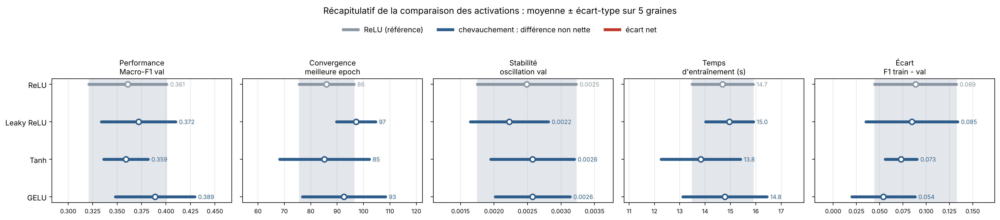

In [22]:
# C.4 Graphique 1 : bandes de chevauchement pour chaque critère, avec ReLU comme référence

from matplotlib.lines import Line2D

criteres_C = [  # (colonne, titre, format)
    ("val_f1_macro", "Performance\nMacro-F1 val", ".3f"),
    ("meilleure_epoch", "Convergence\nmeilleure epoch", ".0f"),
    ("instabilite_val", "Stabilité\noscillation val", ".4f"),
    ("temps_s", "Temps\nd'entraînement (s)", ".1f"),
    ("ecart_f1_train_val", "Écart\nF1 train - val", ".3f"),
]
REFERENCE_C = "ReLU"
stats_C = resultats_C.groupby("activation")[[c for c, _, _ in criteres_C]].agg(["mean", "std"]).loc[ACTIVATIONS]

fig, axes = plt.subplots(1, len(criteres_C), figsize=(19, 4.2), sharey=True)
y = np.arange(len(ACTIVATIONS))[::-1]                         # première activation en haut
for ax, (col, titre, fmt) in zip(axes, criteres_C):
    m, s = stats_C[(col, "mean")], stats_C[(col, "std")]
    bas_ref, haut_ref = m[REFERENCE_C] - s[REFERENCE_C], m[REFERENCE_C] + s[REFERENCE_C]
    ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")              # bande de la référence
    for yi, act in zip(y, ACTIVATIONS):
        bas, haut = m[act] - s[act], m[act] + s[act]
        if act == REFERENCE_C:
            c = "#8a96a3"
        else:
            chevauche = bas <= haut_ref and haut >= bas_ref
            c = "#2e5c8b" if chevauche else "#c0392b"
        ax.plot([bas, haut], [yi, yi], color=c, lw=4, solid_capstyle="round")
        ax.plot(m[act], yi, "o", color="white", mec=c, mew=2, ms=7)
        ax.text(haut, yi, f"  {m[act]:{fmt}}", va="center", fontsize=8, color=c)
    ax.set_title(titre, fontsize=10)
    ax.margins(x=0.35)                                          # place pour les valeurs à droite
    ax.grid(axis="x", alpha=0.3)
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_yticks(y, ACTIVATIONS)

legende = [Line2D([0], [0], color="#8a96a3", lw=4, label="ReLU (référence)"),
           Line2D([0], [0], color="#2e5c8b", lw=4, label="chevauchement : différence non nette"),
           Line2D([0], [0], color="#c0392b", lw=4, label="écart net")]
fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.92), frameon=False, fontsize=10)
fig.suptitle("Récapitulatif de la comparaison des activations : moyenne ± écart-type sur 5 graines", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.86])
plt.show()

Sur les cinq critères, toutes les barres sont bleues : aucune activation ne se distingue nettement de ReLU.

- Performance : GELU est devant en moyenne (0,389), mais sa barre chevauche largement celle de ReLU.
- Convergence : toutes trouvent leur meilleure epoch entre 85 et 96 en moyenne. Leaky ReLU est un peu plus tardive (96), sans écart net.
- Stabilité : les courbes oscillent très peu pour toutes les activations (entre 0,002 et 0,003).
- Temps : ReLU est la plus rapide (71,8 s), mais les autres restent proches.
- Écart entraînement / validation : GELU a le plus petit (0,054) et Leaky ReLU le plus grand (0,098), sans écart net là non plus.

En résumé, Le changement de fonction d’activation n’améliore pas nettement la qualité de la classification.

#### 3.4 courbes d'apprentissage des 5 graines pour chaque activation

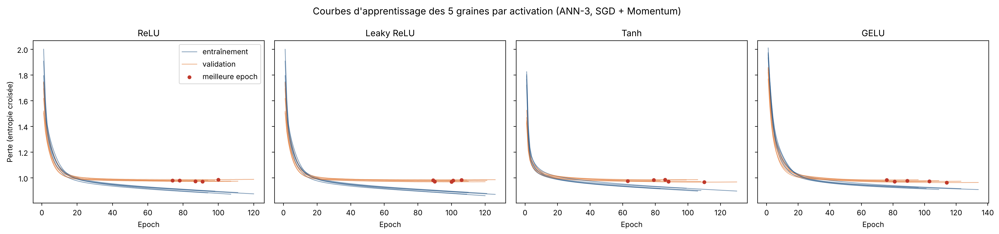

In [23]:


fig, axes = plt.subplots(1, len(ACTIVATIONS), figsize=(19, 4.5), sharey=True)
for ax, act in zip(axes, ACTIVATIONS):
    for graine in GRAINES:
        h = historiques_C[(act, graine)]
        epochs = np.arange(1, len(h["loss"]) + 1)
        premiere = graine == GRAINES[0]                 # légende affichée une seule fois
        ax.plot(epochs, h["loss"], color="#2e5c8b", lw=1, alpha=0.6,
                label="entraînement" if premiere else None)
        ax.plot(epochs, h["val_loss"], color="#e07b39", lw=1, alpha=0.6,
                label="validation" if premiere else None)
        meilleure = int(np.nanargmin(h["val_loss"]))
        ax.scatter(meilleure + 1, h["val_loss"][meilleure], color="#c0392b", s=18, zorder=3,
                   label="meilleure epoch" if premiere else None)
    ax.set_title(act)
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("Perte (entropie croisée)")
axes[0].legend()
fig.suptitle("Courbes d'apprentissage des 5 graines par activation (ANN-3, SGD + Momentum)", fontsize=13)
plt.tight_layout()
plt.show()

Les courbes des quatre activations se ressemblent beaucoup. Pendant les vingt premières epochs environ, les pertes d’entraînement et de validation baissent rapidement et ensemble. Ensuite, la perte de validation se stabilise autour de 0,97 et ne remonte pas, tandis que la perte d’entraînement continue de baisser doucement. Le modèle commence donc à mieux connaître les données d’entraînement que les nouvelles données, mais sans vrai surapprentissage. Tanh fait baisser la perte un peu plus vite au tout début, puis rejoint les autres.

Comme la perte de validation forme un plateau très plat, le moment exact où elle est la plus basse varie selon la graine (de 63 à 110 epochs pour Tanh). Cela explique les écarts-types assez grands sur la convergence.

####  3.5 neurones inactifs et saturation 



- neurones_inactifs : part des neurones dont la valeur avant activation est négative pour TOUTES
      les observations. Avec ReLU, un tel neurone sort toujours 0 et ne reçoit plus de gradient : il est « mort ».
      Avec Leaky ReLU, il continue d'apprendre grâce à la petite pente.
- saturation : part des sorties de Tanh proches de -1 ou 1 (|tanh| > 0,99), où le gradient est presque nul.
      Calculée seulement pour Tanh."""

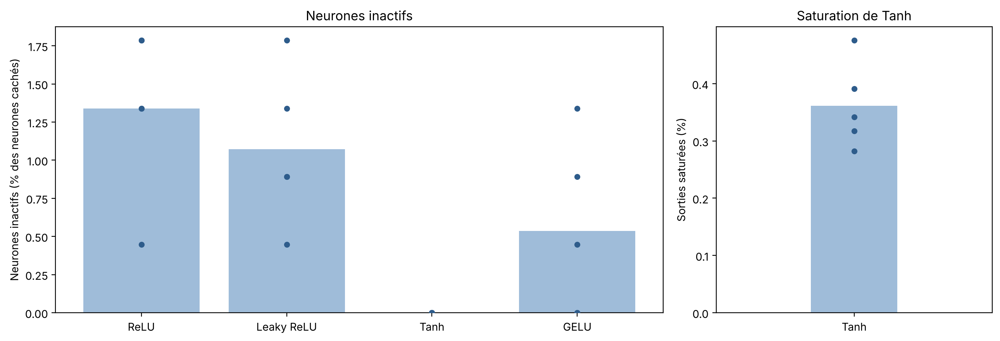

In [24]:


# À droite : part des sorties de Tanh saturées (|tanh| > 0,99), où le gradient est presque nul.
# Chaque point = une graine ; la barre = la moyenne.

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw=dict(width_ratios=[2.2, 1]))
x = np.arange(len(ACTIVATIONS))
moy = resultats_C.groupby("activation")["neurones_inactifs"].mean().loc[ACTIVATIONS]
axes[0].bar(x, moy * 100, color="#9fbcd9")
for i, act in enumerate(ACTIVATIONS):
    v = resultats_C.loc[resultats_C["activation"] == act, "neurones_inactifs"] * 100
    axes[0].scatter(np.full(len(v), i), v, color="#2e5c8b", s=20, zorder=3)
axes[0].set_xticks(x, ACTIVATIONS)
axes[0].set_ylabel("Neurones inactifs (% des neurones cachés)")
axes[0].set_title("Neurones inactifs")

v = resultats_C.loc[resultats_C["activation"] == "Tanh", "saturation"] * 100
axes[1].bar([0], [v.mean()], color="#9fbcd9", width=0.5)
axes[1].scatter(np.zeros(len(v)), v, color="#2e5c8b", s=20, zorder=3)
axes[1].set_xticks([0], ["Tanh"])
axes[1].set_xlim(-0.8, 0.8)
axes[1].set_ylabel("Sorties saturées (%)")
axes[1].set_title("Saturation de Tanh")
plt.tight_layout()
plt.show()

Ce graphique vérifie si les deux défauts connus des activations apparaissent dans notre réseau.

Neurones « morts » (ReLU). Les couches cachées comptent 224 neurones (128 + 64 + 32). Avec ReLU, 1,3 % de neurones inactifs en moyenne représentent environ 3 neurones, et 4 au maximum. Le problème est donc presque absent. C’est pour cela que Leaky ReLU, conçue justement pour l’éviter, n’apporte rien ici : elle n’a presque rien à corriger. Avec Leaky ReLU et GELU, un neurone « inactif » n’est d’ailleurs pas vraiment mort, car il continue de recevoir un peu de gradient.

Saturation (Tanh). Seulement 0,36 % des sorties de Tanh sont collées à −1 ou 1. Tanh ne sature donc presque jamais. C’est grâce à la standardisation des variables d’entrée, qui garde les valeurs dans une plage raisonnable.

Le réseau est peu profond et les données sont standardisées : les problèmes que ces activations cherchent à corriger ne se posent pas ici, ce qui explique que leurs résultats soient si proches.

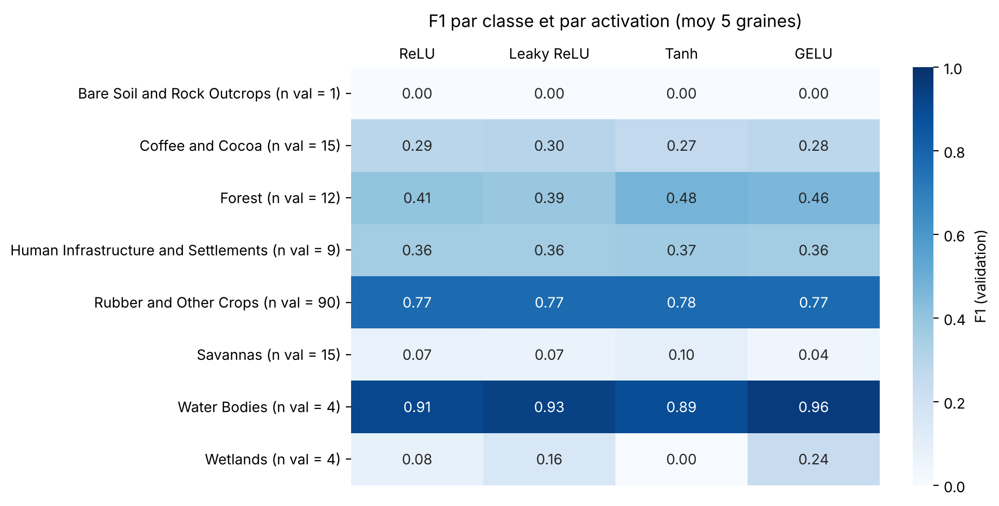

In [25]:
# C.7 Graphique 4 : F1 par classe et par activation (validation, moyenne des 5 graines)

f1_classes_C = pd.DataFrame({act: np.mean([f1_par_classe_C[(act, g)] for g in GRAINES], axis=0)
                             for act in ACTIVATIONS}, index=NOMS_CLASSES)
effectifs_val_C = pd.Series(y_val).value_counts().reindex(range(N_CLASSES), fill_value=0).to_numpy()
f1_classes_C.index = [f"{c} (n val = {n})" for c, n in zip(NOMS_CLASSES, effectifs_val_C)]

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(f1_classes_C, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "F1 (validation)"})
ax.xaxis.tick_top()                     # noms des activations au-dessus du graphique
ax.tick_params(axis="x", length=0)
ax.set_title("F1 par classe et par activation (moy 5 graines)", pad=28)
plt.tight_layout()
plt.show()
# certaines classes n'ont que 1 à 4 observations en validation : leur F1 est très instable.

Comme dans les expériences A et B, le profil des classes ne change pas avec l’activation. Bare Soil and Rock Outcrops n’est jamais reconnue et Savannas presque jamais (F1 de 0,04 à 0,10). Water Bodies et Rubber and Other Crops restent les mieux reconnues. Tanh et GELU reconnaissent un peu mieux Forest (0,48 et 0,46 contre 0,41 pour ReLU).

La seule vraie différence concerne Wetlands, reconnue bien mieux avec GELU (0,24 contre 0,08 pour ReLU). Mais cette classe ne compte que 4 observations en validation : une seule observation bien classée suffit à faire bouger son F1. Comme le Macro-F1 est la moyenne des 8 classes, cette classe explique à elle seule environ 0,02 point de l’avance de GELU, soit les deux tiers de son écart avec ReLU (0,028). L’avantage de GELU repose donc surtout sur quelques observations, et non sur une meilleure reconnaissance générale.

Les difficultés viennent toujours des données (classes rares ou qui se ressemblent spectralement), pas de la fonction d’activation.

Synthèse de l’expérience C

Avec la même architecture (ANN-3), le même optimiseur (SGD + Momentum), les mêmes partitions et le même budget d’epochs, la fonction d’activation des couches cachées ne modifie pas nettement la qualité de la classification. Les Macro-F1 en validation vont de 0,359 à 0,389, et tous les intervalles se chevauchent. Les écarts dus à la graine sont même plus grands que ceux dus à l’activation.

Leaky ReLU ne fait pas mieux que ReLU, car le problème des neurones inactifs est presque absent (au plus 4 neurones sur 224).
Tanh, l’activation saturante, ne sature presque pas grâce à la standardisation. C’est la plus régulière d’une graine à l’autre, sans être plus performante.
GELU a le meilleur Macro-F1 moyen et le plus petit écart entre entraînement et validation. Mais son avantage vient surtout d’une classe de 4 observations et ne se retrouve ni sur le MCC ni sur l’accuracy.

pour la suite nous utiliserons l’activation GELU  car sans écart net avec ReLU, elle obtient le Macro-F1 moyen le plus élevé, fait mieux que ReLU pour 4 graines sur 5 et présente le plus faible écart entre entraînement et validation, pour une stabilité et un coût comparables.

### 4. EXPÉRIENCE D : régularisation et prévention du surapprentissage
#### Objectif : vérifier si les techniques de régularisation réduisent l'écart entre les performances d'entraînement et de validation, tout en préservant le Macro-F1 en validation.

#### Principe directeur : 
on part de la configuration retenue (ANN-3, SGD + Momentum, GeLU) et on etudie une seule technique à la fois.

In [26]:
# D.1 Fonctions de l'expérience D

def calculer_metriques(y_vrai, y_pred):
    return {
        "accuracy": accuracy_score(y_vrai, y_pred),
        "precision_macro": precision_score(y_vrai, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_pondere": f1_score(y_vrai, y_pred, average="weighted", zero_division=0),
        "mcc": matthews_corrcoef(y_vrai, y_pred),
    }

def instabilite(pertes_val):
    """Oscillations de la perte de validation : écart moyen à la tendance (médiane mobile sur 5 epochs)."""
    p = pd.Series(pertes_val).dropna()
    tendance = p.rolling(5, center=True, min_periods=1).median()
    return float((p - tendance).abs().mean())


def construire_ann3_D(dropout=0.0, l2=0.0, batchnorm=False):
    """ANN-3 (19 -> 128 -> 64 -> 32 -> 8), ReLU, avec la régularisation demandée.
    Ordre dans chaque couche cachée : Dense -> (BatchNorm) -> ReLU -> (Dropout)."""
    reg = keras.regularizers.L2(l2) if l2 > 0 else None
    modele = keras.Sequential(name="ANN_3_D")
    modele.add(keras.Input(shape=(len(VARIABLES),)))
    for n in ARCHITECTURES[ARCHI_D]:
        modele.add(layers.Dense(n, kernel_regularizer=reg))
        if batchnorm:
            modele.add(layers.BatchNormalization())
        modele.add(layers.Activation(ACTIVATION_D))
        if dropout > 0:
            modele.add(layers.Dropout(dropout))           # actif seulement pendant l'entraînement
    modele.add(layers.Dense(N_CLASSES, activation="softmax", kernel_regularizer=reg))
    modele.compile(optimizer=keras.optimizers.SGD(learning_rate=LR_D, momentum=MOMENTUM_D),
                   loss="sparse_categorical_crossentropy",
                   # « ce » = entropie croisée SANS la pénalité L2 : même mesure pour toutes les configurations
                   metrics=["accuracy", keras.metrics.SparseCategoricalCrossentropy(name="ce")])
    return modele


def norme_poids(modele):
    """Taille globale des poids (norme L2 de toutes les matrices de poids). La L2 doit la faire baisser."""
    noyaux = [c.kernel.numpy() for c in modele.layers if isinstance(c, layers.Dense)]
    return float(np.sqrt(sum(np.sum(w ** 2) for w in noyaux)))


def entrainer_D(nom, graine):
    """Entraîne une configuration de l'expérience D avec une graine et renvoie les indicateurs."""
    p = {**PARAMS_DEFAUT, **CONFIGS_D[nom]}          # valeurs par défaut + ce qui change
    keras.utils.set_random_seed(graine)              # mêmes poids de départ pour toutes les configurations
    modele = construire_ann3_D(p["dropout"], p["l2"], p["batchnorm"])

    rappels = [keras.callbacks.TerminateOnNaN()]
    if p["early_stopping"]:
        rappels.append(keras.callbacks.EarlyStopping(monitor="val_ce", mode="min", patience=PATIENCE,
                                                     restore_best_weights=True))
    if p["reduce_lr"]:
        rappels.append(keras.callbacks.ReduceLROnPlateau(monitor="val_ce", mode="min",
                                                         factor=REDUCTION_FACTEUR,
                                                         patience=REDUCTION_PATIENCE, min_lr=LR_MIN))
    debut = time.perf_counter()
    hist = modele.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=EPOCHS_MAX, batch_size=TAILLE_LOT, callbacks=rappels, verbose=0)
    duree = time.perf_counter() - debut

    ce_val = np.array(hist.history["val_ce"], dtype=float)
    pred_train = modele.predict(X_train, verbose=0).argmax(axis=1)   # dropout désactivé à la prédiction
    pred_val = modele.predict(X_val, verbose=0).argmax(axis=1)
    m_train = calculer_metriques(y_train, pred_train)
    m_val = calculer_metriques(y_val, pred_val)

    ligne = {
        "config": nom, "graine": graine, **p,
        "parametres": int(sum(np.prod(w.shape) for w in modele.trainable_weights)),
        "epochs_effectuees": len(ce_val),
        "meilleure_epoch": int(np.nanargmin(ce_val)) + 1,
        "temps_s": duree,
        # perte des poids réellement gardés : la meilleure (arrêt anticipé) ou la dernière (sans arrêt)
        "perte_val": float(np.nanmin(ce_val)) if p["early_stopping"] else float(ce_val[-1]),
        "instabilite_val": instabilite(ce_val),
        "norme_poids": norme_poids(modele),
        "lr_final": float(keras.ops.convert_to_numpy(modele.optimizer.learning_rate)),
        **{f"val_{k}": v for k, v in m_val.items()},
        "train_f1_macro": m_train["f1_macro"],
        "ecart_f1_train_val": m_train["f1_macro"] - m_val["f1_macro"],   # critère principal de D
    }
    f1_classes = f1_score(y_val, pred_val, average=None, labels=range(N_CLASSES), zero_division=0)
    return ligne, hist.history, f1_classes

#### 4.1 Paramètres de l'expérience D

In [27]:

# On réutilise : X_train, X_val, y_train, y_val, ARCHITECTURES, VARIABLES, N_CLASSES, NOMS_CLASSES,
# calculer_metriques, instabilite, GRAINES, EPOCHS_MAX, PATIENCE, TAILLE_LOT.


ARCHI_D = "ANN-3"                 # retenue à l'issue de l'expérience A
LR_D, MOMENTUM_D = 0.01, 0.5      # SGD + Momentum, retenu à l'issue de l'expérience B
ACTIVATION_D = "gelu"             # retenue à l'issue de l'expérience C


# Valeurs de la référence : aucune régularisation ajoutée, arrêt anticipé actif (comme dans A, B et C)
PARAMS_DEFAUT = {"dropout": 0.0, "l2": 0.0, "batchnorm": False,
                 "early_stopping": True, "reduce_lr": False}

# Chaque configuration ne change qu'UNE chose par rapport à la référence
CONFIGS_D = {
    "Référence":           {},
    "Sans Early Stopping": {"early_stopping": False},
    "Dropout 0,1":         {"dropout": 0.1},
    "Dropout 0,2":         {"dropout": 0.2},
    "Dropout 0,4":         {"dropout": 0.4},
    "L2 1e-4":             {"l2": 1e-4},
    "L2 1e-3":             {"l2": 1e-3},
    "L2 1e-2":             {"l2": 1e-2},
    "Batch Normalization": {"batchnorm": True},
    "Réduction du taux":   {"reduce_lr": True},
}

# Réduction du taux : divisé par 2 si la perte de validation ne baisse plus pendant 8 epochs
# (patience plus courte que celle de l'arrêt anticipé, sinon l'entraînement s'arrêterait avant)
REDUCTION_FACTEUR, REDUCTION_PATIENCE, LR_MIN = 0.5, 8, 1e-4

print(f"{ARCHI_D} {ARCHITECTURES[ARCHI_D]} | SGD + Momentum (lr = {LR_D}, momentum = {MOMENTUM_D}) | {ACTIVATION_D}")
print(f"{len(CONFIGS_D)} configurations x {len(GRAINES)} graines = {len(CONFIGS_D) * len(GRAINES)} entraînements")

ANN-3 [128, 64, 32] | SGD + Momentum (lr = 0.01, momentum = 0.5) | gelu
10 configurations x 5 graines = 50 entraînements


In [28]:
# Entraînement : 10 configurations x 5 graines

resultats_D, historiques_D, f1_par_classe_D = [], {}, {}

for nom in CONFIGS_D:
    for graine in GRAINES:
        ligne, histo, f1c = entrainer_D(nom, graine)
        resultats_D.append(ligne)
        historiques_D[(nom, graine)] = histo
        f1_par_classe_D[(nom, graine)] = f1c
        print(f"{nom:20s} | graine {graine} | {ligne['epochs_effectuees']:3d} epochs | "
              f"Macro-F1 val = {ligne['val_f1_macro']:.3f} | écart train-val = {ligne['ecart_f1_train_val']:.3f} | "
              f"{ligne['temps_s']:.1f} s")

resultats_D = pd.DataFrame(resultats_D)


Référence            | graine 0 | 123 epochs | Macro-F1 val = 0.408 | écart train-val = 0.026 | 16.7 s
Référence            | graine 1 | 134 epochs | Macro-F1 val = 0.420 | écart train-val = 0.034 | 18.8 s
Référence            | graine 2 | 109 epochs | Macro-F1 val = 0.332 | écart train-val = 0.106 | 16.4 s
Référence            | graine 3 | 101 epochs | Macro-F1 val = 0.423 | écart train-val = 0.032 | 16.7 s
Référence            | graine 4 |  96 epochs | Macro-F1 val = 0.361 | écart train-val = 0.072 | 13.9 s
Sans Early Stopping  | graine 0 | 200 epochs | Macro-F1 val = 0.442 | écart train-val = 0.051 | 28.2 s
Sans Early Stopping  | graine 1 | 200 epochs | Macro-F1 val = 0.429 | écart train-val = 0.101 | 25.2 s
Sans Early Stopping  | graine 2 | 200 epochs | Macro-F1 val = 0.332 | écart train-val = 0.166 | 26.4 s
Sans Early Stopping  | graine 3 | 200 epochs | Macro-F1 val = 0.443 | écart train-val = 0.013 | 28.7 s
Sans Early Stopping  | graine 4 | 200 epochs | Macro-F1 val = 0.355 | éca

#### 4.2 Tableau récapitulatif des configurations (validation, moyenne ± écart-type sur 5 graines)

In [29]:


CONFIGS_ORDRE = list(CONFIGS_D)                       # même ordre que dans CONFIGS_D
if "config" not in resultats_D.columns:               # nom de la configuration, dans l'ordre de la boucle d'entraînement
    resultats_D["config"] = np.repeat(CONFIGS_ORDRE, len(GRAINES))
colonnes_D = ["val_f1_macro", "val_mcc", "val_accuracy", "val_precision_macro", "val_recall_macro",
              "train_f1_macro", "ecart_f1_train_val", "meilleure_epoch", "epochs_effectuees",
              "instabilite_val", "temps_s"]
colonnes_D = [c for c in colonnes_D if c in resultats_D.columns]   # seulement les colonnes enregistrées

recap_D = resultats_D.groupby("config")[colonnes_D].agg(["mean", "std"]).loc[CONFIGS_ORDRE]
tableau_D = pd.DataFrame(index=recap_D.index)
for c in colonnes_D:
    dec = 0 if c in ("meilleure_epoch", "epochs_effectuees") else (1 if c == "temps_s" else 3)
    tableau_D[c] = [f"{m:.{dec}f} ± {s:.{dec}f}" for m, s in zip(recap_D[(c, "mean")], recap_D[(c, "std")])]

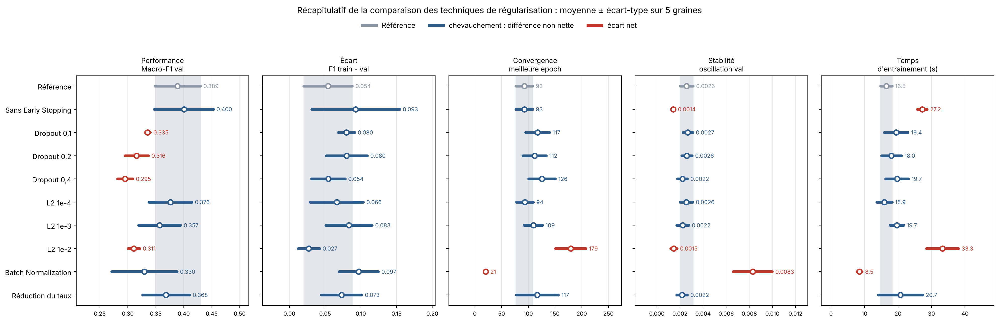

In [30]:

# Chaque trait = [moyenne - écart-type ; moyenne + écart-type] sur 5 graines.
# Gris = Référence ; bleu = chevauchement (différence non nette) ; rouge = écart net.
# Règle de lecture visuelle, pas un test statistique.

criteres_D = [  # (colonne, titre, format)
    ("val_f1_macro", "Performance\nMacro-F1 val", ".3f"),
    ("ecart_f1_train_val", "Écart\nF1 train - val", ".3f"),
    ("meilleure_epoch", "Convergence\nmeilleure epoch", ".0f"),
    ("instabilite_val", "Stabilité\noscillation val", ".4f"),
    ("temps_s", "Temps\nd'entraînement (s)", ".1f"),
]
criteres_D = [c for c in criteres_D if c[0] in resultats_D.columns]
REFERENCE_D = "Référence"
stats_D = resultats_D.groupby("config")[[c for c, _, _ in criteres_D]].agg(["mean", "std"]).loc[CONFIGS_ORDRE]

fig, axes = plt.subplots(1, len(criteres_D), figsize=(20, 6.5), sharey=True)
y = np.arange(len(CONFIGS_ORDRE))[::-1]                       # première configuration en haut
for ax, (col, titre, fmt) in zip(axes, criteres_D):
    m, s = stats_D[(col, "mean")], stats_D[(col, "std")]
    bas_ref, haut_ref = m[REFERENCE_D] - s[REFERENCE_D], m[REFERENCE_D] + s[REFERENCE_D]
    ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")              # bande de la référence
    for yi, nom in zip(y, CONFIGS_ORDRE):
        bas, haut = m[nom] - s[nom], m[nom] + s[nom]
        if nom == REFERENCE_D:
            c = "#8a96a3"
        else:
            chevauche = bas <= haut_ref and haut >= bas_ref
            c = "#2e5c8b" if chevauche else "#c0392b"
        ax.plot([bas, haut], [yi, yi], color=c, lw=4, solid_capstyle="round")
        ax.plot(m[nom], yi, "o", color="white", mec=c, mew=2, ms=7)
        ax.text(haut, yi, f"  {m[nom]:{fmt}}", va="center", fontsize=8, color=c)
    ax.set_title(titre, fontsize=10)
    ax.margins(x=0.35)                                          # place pour les valeurs à droite
    ax.grid(axis="x", alpha=0.3)
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_yticks(y, CONFIGS_ORDRE)

legende = [Line2D([0], [0], color="#8a96a3", lw=4, label="Référence"),
           Line2D([0], [0], color="#2e5c8b", lw=4, label="chevauchement : différence non nette"),
           Line2D([0], [0], color="#c0392b", lw=4, label="écart net")]
fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.95), frameon=False, fontsize=10)
fig.suptitle("Récapitulatif de la comparaison des techniques de régularisation : moyenne ± écart-type sur 5 graines", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()

Par rapport à la Référence, aucune technique n’améliore le Macro-F1 en validation et aucune ne réduit nettement l’écart entre entraînement et validation : l’objectif n’est donc atteint par aucune d’entre elles.

Le Dropout fait nettement baisser le Macro-F1, d’autant plus que le taux de neurone desactivés augmente (0,335, 0,316 puis 0,295), sans réduire l’écart. Avec un taux de 0,1, il rend toutefois les résultats très réguliers d’une graine à l’autre (écart-type de 0,005 sur le Macro-F1).

Parmi les pénalisations L2, les valeurs de 1e-4 et 1e-3 chevauchent la Référence sur tous les critères. Seule la plus forte (1e-2) se distingue : elle obtient le plus faible écart (0,027, sans écart net), mais au prix d’un Macro-F1 nettement plus bas (0,311), d’une convergence plus lente (meilleure epoch 179) et d’un entraînement plus long (56,6 s).

Sans arrêt anticipé, le Macro-F1 reste comparable (0,400), mais l’écart augmente (0,093, sans écart net) et l’entraînement est nettement plus long (61,5 s contre 42,8 s). Ses courbes paraissent plus stables, mais cela tient en partie aux nombreuses epochs passées sur un plateau, qui font baisser l’oscillation moyenne ; c’est aussi le cas de L2 1e-2.

La Batch Normalization converge nettement plus vite (meilleure epoch 21, 17,8 s), mais ses courbes sont nettement plus instables (0,0078), son écart est le plus grand (0,097) et son Macro-F1 le plus variable d’une graine à l’autre (± 0,058). La réduction du taux d’apprentissage n’a pas d’effet visible : elle chevauche la Référence sur tous les critères.

La Référence, avec l’arrêt anticipé seul, reste donc le meilleur compromis entre performance, écart entraînement / validation et coût d’entraînement.

####  4.3 l'écart entraînement / validation 

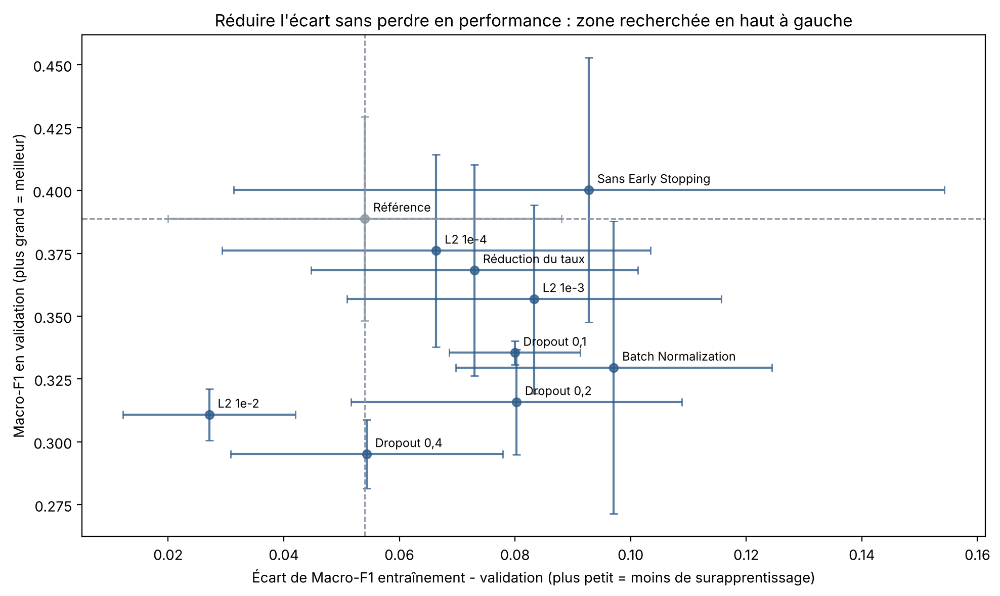

In [31]:

# tout en préservant la performance en validation (axe vertical, vers le haut).
# Lignes pointillées = valeurs de la Référence ; barres = écart-type sur 5 graines.

g = resultats_D.groupby("config").agg(ecart=("ecart_f1_train_val", "mean"), ecart_sd=("ecart_f1_train_val", "std"),
                                      f1=("val_f1_macro", "mean"), f1_sd=("val_f1_macro", "std")).loc[CONFIGS_ORDRE]
fig, ax = plt.subplots(figsize=(10, 6))
for nom, ligne in g.iterrows():
    c = "#8a96a3" if nom == REFERENCE_D else "#2e5c8b"
    ax.errorbar(ligne["ecart"], ligne["f1"], xerr=ligne["ecart_sd"], yerr=ligne["f1_sd"],
                fmt="o", capsize=3, color=c, alpha=0.8)
    ax.annotate(nom, (ligne["ecart"], ligne["f1"]), xytext=(6, 5), textcoords="offset points", fontsize=8.5)
ax.axvline(g.loc[REFERENCE_D, "ecart"], color="#8a96a3", ls="--", lw=1)
ax.axhline(g.loc[REFERENCE_D, "f1"], color="#8a96a3", ls="--", lw=1)
ax.set_xlabel("Écart de Macro-F1 entraînement - validation (plus petit = moins de surapprentissage)")
ax.set_ylabel("Macro-F1 en validation (plus grand = meilleur)")
ax.set_title("Réduire l'écart sans perdre en performance : zone recherchée en haut à gauche")
plt.tight_layout()
plt.show()

Aucune configuration ne se place dans la zone recherchée, en haut à gauche de la Référence : aucune ne réduit l’écart entre entraînement et validation sans perdre en Macro-F1. Seul L2 1e-2 réduit l’écart (0,027), mais au prix d’un Macro-F1 nettement plus bas (0,311). Les autres techniques restent proches de la Référence ou perdent en performance, comme le Dropout ( du a la taille du reseau ici  qui n'est pas volumineuse) et la Batch Normalization. La Référence reste donc le meilleur compromis.

#### 4.4 courbes d'apprentissage des 5 graines pour chaque configuration

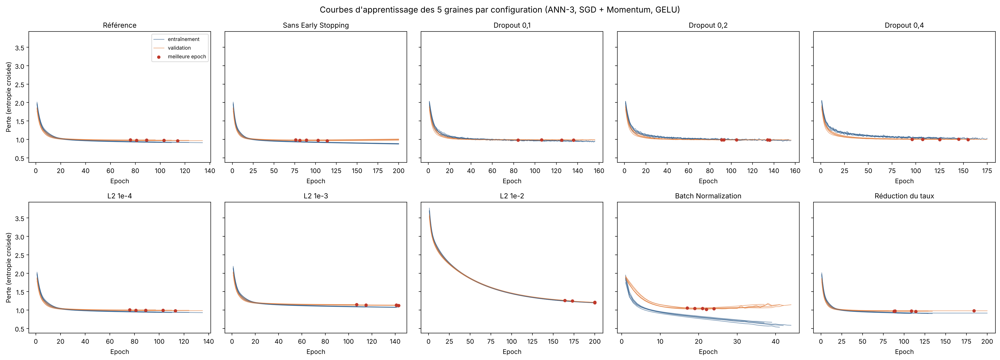

In [32]:

# Chaque trait = un entraînement complet ; le point rouge = meilleure epoch (minimum de la perte de validation).

fig, axes = plt.subplots(2, 5, figsize=(22, 8), sharey=True)
for ax, nom in zip(axes.ravel(), CONFIGS_ORDRE):
    for graine in GRAINES:
        h = historiques_D[(nom, graine)]
        epochs = np.arange(1, len(h["loss"]) + 1)
        premiere = graine == GRAINES[0]                 # légende affichée une seule fois
        ax.plot(epochs, h["loss"], color="#2e5c8b", lw=1, alpha=0.6,
                label="entraînement" if premiere else None)
        ax.plot(epochs, h["val_loss"], color="#e07b39", lw=1, alpha=0.6,
                label="validation" if premiere else None)
        meilleure = int(np.nanargmin(h["val_loss"]))
        ax.scatter(meilleure + 1, h["val_loss"][meilleure], color="#c0392b", s=18, zorder=3,
                   label="meilleure epoch" if premiere else None)
    ax.set_title(nom, fontsize=11)
    ax.set_xlabel("Epoch")
for ax in axes[:, 0]:
    ax.set_ylabel("Perte (entropie croisée)")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Courbes d'apprentissage des 5 graines par configuration (ANN-3, SGD + Momentum, GELU)", fontsize=13)
plt.tight_layout()
plt.show()


Les courbes de perte confirment les observations précédentes. Avec L2 1e-4 (pénalisation très faible des poids) et avec la réduction du taux, elles restent très proches de la Référence : ces techniques ne modifient presque pas l’apprentissage, et la réduction du taux ne fait pas baisser davantage la perte. Sans arrêt anticipé, la perte de validation reste stable jusqu’à 200 epochs, avec une légère remontée en fin d’entraînement. Trois configurations se distinguent. Avec L2 1e-2, l’apprentissage est très lent : la perte, qui inclut ici la pénalité, baisse encore à 200 epochs et la meilleure epoch atteint la limite du budget. Les courbes d’entraînement et de validation restent confondues, ce qui explique le faible écart, mais le modèle n’a pas fini d’apprendre : c’est un sous-apprentissage. Avec la Batch Normalization, la perte d’entraînement chute rapidement (jusqu’à environ 0,55) tandis que celle de validation baisse pendant une vingtaine d’epochs puis remonte : le modèle apprend vite mais surapprend tôt, comme l’ANN-5 de l’expérience A. Avec le Dropout, la perte d’entraînement est plus irrégulière et reste au-dessus de celle de validation, car les neurones ne sont éteints que pendant l’entraînement ; le Dropout freine l’apprentissage de ce petit réseau, alors qu’il est surtout efficace sur de grands réseaux qui surapprennent fortement

####  4.5 F1 par classe et par configuration (validation, moyenne des 5 graines)

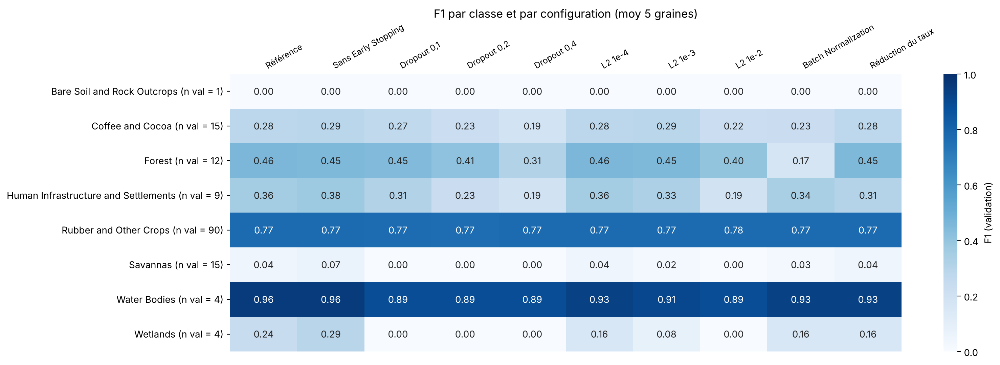

In [33]:


f1_classes_D = pd.DataFrame({nom: np.mean([f1_par_classe_D[(nom, g)] for g in GRAINES], axis=0)
                             for nom in CONFIGS_ORDRE}, index=NOMS_CLASSES)
effectifs_val_D = pd.Series(y_val).value_counts().reindex(range(N_CLASSES), fill_value=0).to_numpy()
f1_classes_D.index = [f"{c} (n val = {n})" for c, n in zip(NOMS_CLASSES, effectifs_val_D)]

fig, ax = plt.subplots(figsize=(16, 5.5))
sns.heatmap(f1_classes_D, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "F1 (validation)"})
ax.xaxis.tick_top()                     # noms des configurations au-dessus du graphique
ax.tick_params(axis="x", length=0, labelsize=9)
plt.setp(ax.get_xticklabels(), rotation=30, ha="left")
ax.set_title("F1 par classe et par configuration (moy 5 graines)", pad=60)
plt.tight_layout()
plt.show()
# certaines classes n'ont que 1 à 4 observations en validation : leur F1 est très instable.

Comme dans les expériences précédentes, le profil des classes reste le même quelle que soit la régularisation : Rubber and Other Crops (environ 0,77) et Water Bodies (0,89 à 0,96) sont les mieux reconnues, Bare Soil and Rock Outcrops et Savannas restent presque jamais identifiées. Aucune régularisation n’améliore la reconnaissance d’une classe par rapport à la Référence. Les plus fortes (Dropout 0,4, L2 1e-2, Batch Normalization) la dégradent même.Toutefois la carte ne montre que des moyennes, et plusieurs classes ne comptent que 1 à 4 observations en validation. Le graphique suivant ajoute la variabilité entre graines pour vérifier quels écarts sont nets.

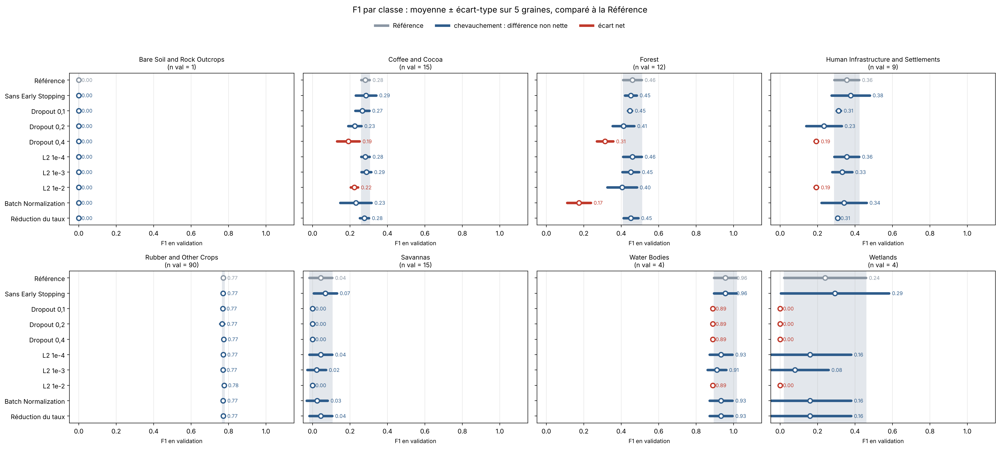

In [34]:
# F1 par classe : moyenne ± écart-type sur les 5 graines, pour chaque configuration

f1_graines = {nom: np.array([f1_par_classe_D[(nom, g)] for g in GRAINES]) for nom in CONFIGS_ORDRE}  # graines x classes
moy = {nom: v.mean(axis=0) for nom, v in f1_graines.items()}
et = {nom: v.std(axis=0, ddof=1) for nom, v in f1_graines.items()}           # écart-type entre graines
effectifs_val = pd.Series(y_val).value_counts().reindex(range(N_CLASSES), fill_value=0).to_numpy()

fig, axes = plt.subplots(2, 4, figsize=(22, 10), sharey=True)
y = np.arange(len(CONFIGS_ORDRE))[::-1]                       # première configuration en haut
for k, ax in enumerate(axes.ravel()):
    bas_ref, haut_ref = moy[REFERENCE_D][k] - et[REFERENCE_D][k], moy[REFERENCE_D][k] + et[REFERENCE_D][k]
    ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")              # bande de la Référence
    for yi, nom in zip(y, CONFIGS_ORDRE):
        m, s = moy[nom][k], et[nom][k]
        if nom == REFERENCE_D:
            c = "#8a96a3"
        else:
            c = "#2e5c8b" if (m - s) <= haut_ref and (m + s) >= bas_ref else "#c0392b"
        ax.plot([m - s, m + s], [yi, yi], color=c, lw=4, solid_capstyle="round")
        ax.plot(m, yi, "o", color="white", mec=c, mew=2, ms=7)
        ax.text(min(m + s, 1.0), yi, f"  {m:.2f}", va="center", fontsize=8, color=c)
    ax.set_title(f"{NOMS_CLASSES[k]}\n(n val = {effectifs_val[k]})", fontsize=10)
    ax.set_xlim(-0.05, 1.15)
    ax.grid(axis="x", alpha=0.3)
    ax.set_xlabel("F1 en validation", fontsize=9)
axes[0, 0].set_yticks(y, CONFIGS_ORDRE)

legende = [Line2D([0], [0], color="#8a96a3", lw=4, label="Référence"),
           Line2D([0], [0], color="#2e5c8b", lw=4, label="chevauchement : différence non nette"),
           Line2D([0], [0], color="#c0392b", lw=4, label="écart net")]
fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.955), frameon=False, fontsize=10)
fig.suptitle("F1 par classe : moyenne ± écart-type sur 5 graines, comparé à la Référence", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()


Le graphique confirme qu’aucune régularisation n’améliore nettement la reconnaissance d’une classe : tous les écarts nets (en rouge) sont des baisses par rapport à la Référence. Le retrait de l’arrêt anticipé chevauche la Référence pour toutes les classes ; ses légers gains apparents sur la carte de chaleur ne sont donc pas nets.

#### 4.6 Synthèse de l’expérience D

 L’objectif était de vérifier si les techniques de régularisation réduisent l’écart entre les performances d’entraînement et de validation, tout en préservant de bonnes performances sur des données inédites. La réponse est non : aucune des techniques testées n’atteint cet objectif.

La Référence surapprend déjà peu (écart de 0,054), grâce à l’arrêt anticipé. Les autres techniques n’ont donc presque rien à corriger. Leur effet se limite à deux cas. Les plus faibles (L2 1e-4 et 1e-3, réduction du taux) ne changent rien de net. Les plus fortes (Dropout, L2 1e-2, Batch Normalization) réduisent la capacité d’apprentissage de ce petit réseau ou le font surapprendre plus vite : le Macro-F1 baisse, en particulier pour les classes de taille moyenne (Coffee and Cocoa, Forest, Human Infrastructure). Le seul écart réduit, celui de L2 1e-2 (0,027), s’accompagne d’un sous-apprentissage. Le retrait de l’arrêt anticipé confirme son utilité : à performance comparable, l’écart augmente (0,093) et l’entraînement dure plus longtemps.

La Référence est donc conservée pour la suite : ANN-3, SGD + Momentum (taux de 0,01, momentum de 0,5), activation GELU et arrêt anticipé seul.

 Les limites qui demeurent, notamment les classes rares jamais reconnues, ne relèvent pas du surapprentissage mais du déséquilibre des classes et du chevauchement spectral, traités dans les expériences suivantes.

 ### 5. Expérience E :gestion du déséquilibre des classes

 #### Objectif 

 vérifier si une méthode de rééquilibrage aide le modèle à mieux reconnaître les classes rares, en jugeant surtout sur le Macro-F1, le rappel par classe et la matrice de confusion, l’accuracy n’étant qu’un complément.


 ### principe directeur :
 une seule chose change, la façon de traiter le déséquilibre. On compare l’apprentissage sans correction (la référence), les poids de classe, le suréchantillonnage et SMOTE. 

# 5.1 Paramètres de l'expérience E 

In [35]:

# On réutilise : X_train, X_val, y_train, y_val, partitions, ARCHITECTURES, VARIABLES, N_CLASSES, NOMS_CLASSES,
# calculer_metriques, instabilite, GRAINES, EPOCHS_MAX, PATIENCE, TAILLE_LOT.



# Modèle retenu à l'issue des expériences A à D (la Référence de l'expérience D)
ARCHI_E = "ANN-3"
LR_E, MOMENTUM_E = 0.01, 0.5      # SGD + Momentum
ACTIVATION_E = "gelu"             # en minuscules pour Keras


# Les 4 méthodes de l'énoncé ; seule la façon de traiter le déséquilibre change
METHODES_E = ["Sans correction", "Poids de classe", "Suréchantillonnage", "SMOTE"]
REFERENCE_E = "Sans correction"
print(f"{ARCHI_E} {ARCHITECTURES[ARCHI_E]} | SGD + Momentum (lr = {LR_E}, momentum = {MOMENTUM_E}) | {ACTIVATION_E}")
print(f"{len(METHODES_E)} méthodes x {len(GRAINES)} graines = {len(METHODES_E) * len(GRAINES)} entraînements")

ANN-3 [128, 64, 32] | SGD + Momentum (lr = 0.01, momentum = 0.5) | gelu
4 méthodes x 5 graines = 20 entraînements


#### 5.2 Rapport classe la plus fréquente / la plus rare (entraînement)

ensemble,train,validation,test,total,part (%)
class_name,,,,,
Rubber and Other Crops,421,90,90,601,60.1
Savannas,71,15,16,102,10.2
Coffee and Cocoa,71,15,15,101,10.1
Forest,55,12,11,78,7.8
Human Infrastructure and Settlements,41,9,9,59,5.9
Wetlands,19,4,4,27,2.7
Water Bodies,17,4,3,24,2.4
Bare Soil and Rock Outcrops,5,1,2,8,0.8


Rapport classe la plus fréquente / la plus rare (entraînement) : 421 / 5 = 84


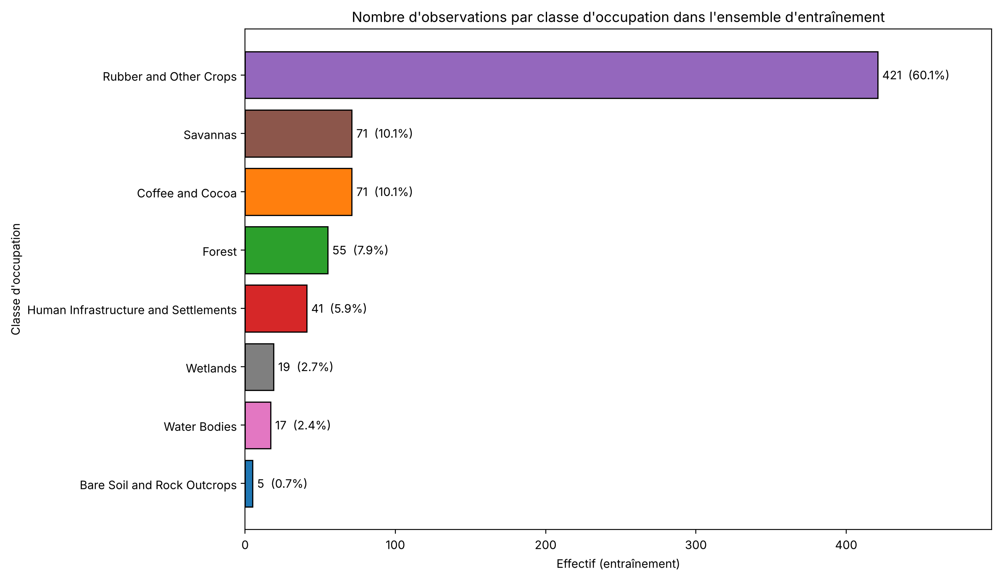

In [36]:

effectifs = pd.crosstab(data["class_name"], partitions["ensemble"])[["train", "validation", "test"]]
effectifs["total"] = effectifs.sum(axis=1)
effectifs["part (%)"] = (100 * effectifs["total"] / effectifs["total"].sum()).round(1)
effectifs = effectifs.sort_values("total", ascending=False)
display(effectifs)
print(f"Rapport classe la plus fréquente / la plus rare (entraînement) : "
      f"{effectifs['train'].max()} / {effectifs['train'].min()} = {effectifs['train'].max() / effectifs['train'].min():.0f}")

# Mêmes couleurs que dans l'analyse exploratoire 
COULEURS_CLASSES = {nom: plt.get_cmap("tab10")(i) for i, nom in enumerate(sorted(effectifs.index))}

ordre = effectifs.index[::-1]                       # la classe la plus fréquente en haut
train = effectifs.loc[ordre, "train"]
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(ordre, train, color=[COULEURS_CLASSES[c] for c in ordre], edgecolor="black")
for i, v in enumerate(train):
    ax.text(v + 3, i, f"{v}  ({100 * v / train.sum():.1f}%)", va="center", fontsize=10)
ax.set_xlim(0, train.max() * 1.18)                  # place pour les étiquettes
ax.set_xlabel("Effectif (entraînement)")
ax.set_ylabel("Classe d'occupation")
ax.set_title("Nombre d'observations par classe d'occupation dans l'ensemble d'entraînement")
plt.tight_layout()
plt.show()

Dans l’ensemble d’entraînement,La classe Rubber and Other Crops domine largement avec 421 observations (60,1 %), suivie de Savannas et Coffee and Cocoa, qui comptent chacune 71 observations (10,1 %). Les autres classes sont moins représentées, notamment Wetlands (2,7 %), Water Bodies (2,4 %) et Bare Soil and Rock Outcrops (0,7 %).
la classe la plus fréquente (Rubber and Other Crops, 421 observations) est 84 fois plus représentée que la plus rare (Bare Soil and Rock Outcrops, 5 observations).

#### 5.3 Fonctions de l'expérience E


In [37]:

def construire_modele_E():
    """ANN-3 avec GELU, entropie croisée et SGD + Momentum : le modèle de Référence de l'expérience D."""
    modele = keras.Sequential(name="ANN_3_E")
    modele.add(keras.Input(shape=(len(VARIABLES),)))
    for n in ARCHITECTURES[ARCHI_E]:
        modele.add(layers.Dense(n))
        modele.add(layers.Activation(ACTIVATION_E))
    modele.add(layers.Dense(N_CLASSES, activation="softmax"))
    modele.compile(optimizer=keras.optimizers.SGD(learning_rate=LR_E, momentum=MOMENTUM_E),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modele


# Poids de classe « balanced » calculés sur l'ENTRAÎNEMENT seulement
POIDS_CLASSE = dict(enumerate(compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_train)))

# SMOTE : il faut au moins k + 1 observations dans chaque classe. 
# (Bare Soil, 5 observations) n'a que 4 voisins : on prend donc k = min(5, effectif minimal - 1).
K_SMOTE = int(min(5, np.bincount(y_train).min() - 1))


def donnees_entrainement(methode, graine):
    """Renvoie (X, y, poids de classe) pour l'entraînement."""
    if methode == "Sans correction":
        return X_train, y_train, None
    if methode == "Poids de classe":
        return X_train, y_train, POIDS_CLASSE
    if methode == "Suréchantillonnage":       # copies aléatoires des classes minoritaires jusqu'à l'effectif de Rubber
        X_r, y_r = RandomOverSampler(random_state=graine).fit_resample(X_train, y_train)
        return X_r, y_r, None
    if methode == "SMOTE":                    # points synthétiques entre voisins de la même classe
        X_r, y_r = SMOTE(k_neighbors=K_SMOTE, random_state=graine).fit_resample(X_train, y_train)
        return X_r, y_r, None
    raise ValueError(methode)


def entrainer_E(methode, graine):
    """Entraîne le modèle avec une méthode et une graine ; évalue sur la validation d'origine (non rééquilibrée)."""
    X_fit, y_fit, poids = donnees_entrainement(methode, graine)
    keras.utils.set_random_seed(graine)               # mêmes poids de départ pour toutes les méthodes
    modele = construire_modele_E()
    arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    debut = time.perf_counter()
    hist = modele.fit(X_fit, y_fit, validation_data=(X_val, y_val), epochs=EPOCHS_MAX, batch_size=TAILLE_LOT,
                      class_weight=poids, callbacks=[arret, keras.callbacks.TerminateOnNaN()], verbose=0)
    duree = time.perf_counter() - debut

    pred_train = modele.predict(X_train, verbose=0).argmax(axis=1)    # entraînement d'ORIGINE, sans copies
    pred_val = modele.predict(X_val, verbose=0).argmax(axis=1)
    m_train, m_val = calculer_metriques(y_train, pred_train), calculer_metriques(y_val, pred_val)
    pertes_val = np.array(hist.history["val_loss"], dtype=float)
    ligne = {
        "methode": methode, "graine": graine,
        "n_entrainement": len(y_fit),                      # taille de l'entraînement après rééquilibrage
        "epochs_effectuees": len(pertes_val),
        "meilleure_epoch": int(np.nanargmin(pertes_val)) + 1,
        "temps_s": duree,
        "instabilite_val": instabilite(pertes_val),
        **{f"val_{k}": v for k, v in m_val.items()},
        "train_f1_macro": m_train["f1_macro"],
        "ecart_f1_train_val": m_train["f1_macro"] - m_val["f1_macro"],
    }
    par_classe = {"rappel": recall_score(y_val, pred_val, average=None, labels=range(N_CLASSES), zero_division=0),
                  "f1": f1_score(y_val, pred_val, average=None, labels=range(N_CLASSES), zero_division=0)}
    return ligne, hist.history, par_classe, pred_val




#### 5.4 ce que change chaque méthode de rééquilibrage

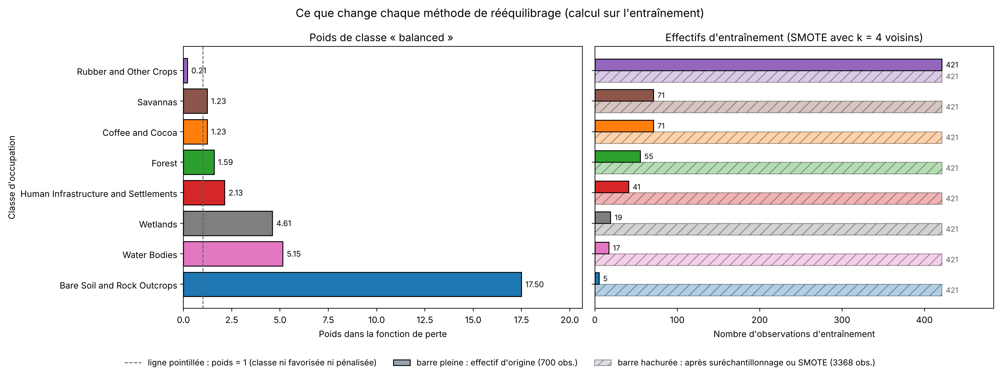

In [38]:
# À gauche : poids de classe  ; à droite : effectifs d'entraînement avant / après rééquilibrage.
from matplotlib.patches import Patch                                          # modifié : pour une légende neutre

COULEURS_CLASSES = {nom: plt.get_cmap("tab10")(i) for i, nom in enumerate(sorted(NOMS_CLASSES))}   # mêmes couleurs que l'analyse exploratoire
ordre = [NOMS_CLASSES[k] for k in np.argsort(np.bincount(y_train))]          # de la plus rare à la plus fréquente
poids = pd.Series({NOMS_CLASSES[k]: v for k, v in POIDS_CLASSE.items()}).loc[ordre]
avant = pd.Series(np.bincount(y_train, minlength=N_CLASSES), index=NOMS_CLASSES).loc[ordre]
apres = pd.Series(np.bincount(donnees_entrainement("Suréchantillonnage", 0)[1], minlength=N_CLASSES),
                  index=NOMS_CLASSES).loc[ordre]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
couleurs = [COULEURS_CLASSES[c] for c in ordre]

# Panneau 1 : poids de classe
axes[0].barh(ordre, poids, color=couleurs, edgecolor="black")
axes[0].axvline(1, color="#55606b", ls="--", lw=1)
for i, v in enumerate(poids):
    axes[0].text(v + 0.2, i, f"{v:.2f}", va="center", fontsize=9)
axes[0].set_xlim(0, poids.max() * 1.18)
axes[0].set_xlabel("Poids dans la fonction de perte")
axes[0].set_title("Poids de classe « balanced » ")
axes[0].set_ylabel("Classe d'occupation")

# Panneau 2 : effectifs d'entraînement avant et après rééquilibrage
h = 0.38
pos = np.arange(len(ordre))
axes[1].barh(pos + h / 2, avant, h, color=couleurs, edgecolor="black")
axes[1].barh(pos - h / 2, apres, h, color=couleurs, edgecolor="black", alpha=0.35, hatch="//")
for i, (a, b) in enumerate(zip(avant, apres)):
    axes[1].text(a + 5, i + h / 2, str(a), va="center", fontsize=8.5)
    axes[1].text(b + 5, i - h / 2, str(b), va="center", fontsize=8.5, color="#55606b")
axes[1].set_xlim(0, apres.max() * 1.15)
axes[1].set_xlabel("Nombre d'observations d'entraînement")
axes[1].set_title(f"Effectifs d'entraînement (SMOTE avec k = {K_SMOTE} voisins)")

# modifié : légende commune, en gris, placée sous les deux panneaux (hors des graphiques)
legende = [Patch(facecolor="#9aa3ad", edgecolor="black", label="ligne pointillée à gauche : poids = 1"),
           Patch(facecolor="#9aa3ad", edgecolor="black", label=f"barre pleine : effectif d'origine ({avant.sum()} obs.)"),
           Patch(facecolor="#9aa3ad", edgecolor="black", alpha=0.35, hatch="//",
                 label=f"barre hachurée : après suréchantillonnage ou SMOTE ({apres.sum()} obs.)")]
legende[0] = Line2D([0], [0], color="#55606b", ls="--", lw=1, label="ligne pointillée : poids = 1 (classe ni favorisée ni pénalisée)")
fig.legend(handles=legende, loc="lower center", ncol=3, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, 0.0))

fig.suptitle("Ce que change chaque méthode de rééquilibrage (calcul sur l'entraînement)", fontsize=13)
plt.tight_layout(rect=[0, 0.07, 1, 1])                                        # modifié : place en bas pour la légende
plt.show()

 Poids de classe : Comme attendu, cette stratégie donne plus de poids aux classes les moins représentées : toutes les classes minoritaires ont un poids supérieur à 1, tandis que Rubber and Other Crops, majoritaire, descend à 0,21. Le poids le plus élevé revient à Bare Soil and Rock Outcrops (17,50), soit environ 84 fois celui de Rubber : se tromper sur l’une de ces 5 observations coûte autant que se tromper sur 84 observations de Rubber. Avec si peu de points portant un poids aussi fort, l’apprentissage peut devenir instable.

Suréchantillonnage et SMOTE : Ces deux stratégies ramènent toutes les classes à l’effectif de la classe majoritaire (421 observations chacune), et l’entraînement passe de 700 à 3 368 observations. Pour Bare Soil, on passe de 5 à 421 observations : 416 sont créées à partir de seulement 5 points réels. Les deux méthodes diffèrent par la façon de créer ces observations.  

In [39]:
# Entraînement : 4 méthodes x 5 graines
# Attention : avec le suréchantillonnage et SMOTE, l'entraînement passe de 700 à 3 368 observations :
# chaque epoch contient environ 5 fois plus de mises à jour (106 lots au lieu de 22). Nous allons  comparer plutôt le temps.

resultats_E, historiques_E, par_classe_E, predictions_E = [], {}, {}, {}

for methode in METHODES_E:
    for graine in GRAINES:
        ligne, histo, pc, pred = entrainer_E(methode, graine)
        resultats_E.append(ligne)
        historiques_E[(methode, graine)] = histo
        par_classe_E[(methode, graine)] = pc
        predictions_E[(methode, graine)] = pred
        print(f"{methode:18s} | graine {graine} | {ligne['epochs_effectuees']:3d} epochs | "
              f"Macro-F1 val = {ligne['val_f1_macro']:.3f} | rappel macro = {ligne['val_recall_macro']:.3f} | "
              f"{ligne['temps_s']:.1f} s")

resultats_E = pd.DataFrame(resultats_E)

Sans correction    | graine 0 | 123 epochs | Macro-F1 val = 0.408 | rappel macro = 0.385 | 18.5 s
Sans correction    | graine 1 | 134 epochs | Macro-F1 val = 0.420 | rappel macro = 0.398 | 21.1 s
Sans correction    | graine 2 | 109 epochs | Macro-F1 val = 0.332 | rappel macro = 0.341 | 17.8 s
Sans correction    | graine 3 | 101 epochs | Macro-F1 val = 0.423 | rappel macro = 0.394 | 17.0 s
Sans correction    | graine 4 |  96 epochs | Macro-F1 val = 0.361 | rappel macro = 0.368 | 15.1 s
Poids de classe    | graine 0 | 127 epochs | Macro-F1 val = 0.396 | rappel macro = 0.494 | 17.9 s
Poids de classe    | graine 1 |  86 epochs | Macro-F1 val = 0.376 | rappel macro = 0.501 | 12.4 s
Poids de classe    | graine 2 | 150 epochs | Macro-F1 val = 0.359 | rappel macro = 0.462 | 20.7 s
Poids de classe    | graine 3 |  94 epochs | Macro-F1 val = 0.379 | rappel macro = 0.523 | 12.9 s
Poids de classe    | graine 4 | 200 epochs | Macro-F1 val = 0.372 | rappel macro = 0.477 | 32.6 s
Suréchantillonnage |

In [40]:
# Tableau récapitulatif (validation, moyenne ± écart-type sur 5 graines)

colonnes_E = ["val_f1_macro", "val_recall_macro", "val_precision_macro", "val_mcc", "val_accuracy",
              "ecart_f1_train_val", "meilleure_epoch", "temps_s"]
recap_E = resultats_E.groupby("methode")[colonnes_E].agg(["mean", "std"]).loc[METHODES_E]
tableau_E = pd.DataFrame(index=recap_E.index)
tableau_E["n entraînement"] = resultats_E.groupby("methode")["n_entrainement"].first().loc[METHODES_E]
for c in colonnes_E:
    dec = 0 if c == "meilleure_epoch" else (1 if c == "temps_s" else 3)
    tableau_E[c] = [f"{m:.{dec}f} ± {s:.{dec}f}" for m, s in zip(recap_E[(c, "mean")], recap_E[(c, "std")])]
display(tableau_E)

,n entraînement,val_f1_macro,val_recall_macro,val_precision_macro,val_mcc,val_accuracy,ecart_f1_train_val,meilleure_epoch,temps_s
methode,,,,,,,,,
Sans correction,700,0.389 ± 0.041,0.377 ± 0.023,0.469 ± 0.097,0.330 ± 0.025,0.645 ± 0.011,0.054 ± 0.034,93 ± 16,33.6 ± 4.7
Poids de classe,700,0.376 ± 0.013,0.492 ± 0.023,0.384 ± 0.023,0.284 ± 0.025,0.347 ± 0.053,0.033 ± 0.041,115 ± 54,53.2 ± 32.0
Suréchantillonnage,3368,0.368 ± 0.030,0.482 ± 0.021,0.377 ± 0.035,0.281 ± 0.014,0.348 ± 0.025,0.051 ± 0.036,22 ± 3,28.1 ± 3.3
SMOTE,3368,0.373 ± 0.030,0.473 ± 0.028,0.374 ± 0.037,0.287 ± 0.015,0.379 ± 0.017,0.046 ± 0.049,23 ± 7,29.7 ± 7.2


#### 5.5 bandes de chevauchement avec la Référence 

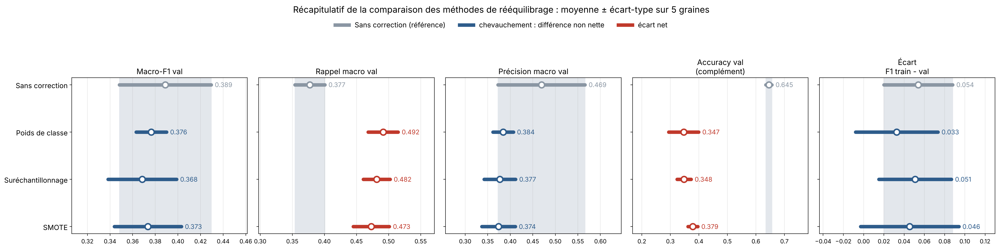

In [41]:
# Gris = Référence ; bleu = chevauchement (différence non nette) ; rouge = écart net.

criteres_E = [("val_f1_macro", "Macro-F1 val", ".3f"),
              ("val_recall_macro", "Rappel macro val", ".3f"),
              ("val_precision_macro", "Précision macro val", ".3f"),
              ("val_accuracy", "Accuracy val\n(complément)", ".3f"),
              ("ecart_f1_train_val", "Écart\nF1 train - val", ".3f")]
stats_E = resultats_E.groupby("methode")[[c for c, _, _ in criteres_E]].agg(["mean", "std"]).loc[METHODES_E]

fig, axes = plt.subplots(1, len(criteres_E), figsize=(24, 6), sharey=True)        # figure plus grande (avant : 20 x 3.8)
y = np.arange(len(METHODES_E))[::-1]
for ax, (col, titre, fmt) in zip(axes, criteres_E):
    m, s = stats_E[(col, "mean")], stats_E[(col, "std")]
    bas_ref, haut_ref = m[REFERENCE_E] - s[REFERENCE_E], m[REFERENCE_E] + s[REFERENCE_E]
    ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")
    for yi, met in zip(y, METHODES_E):
        bas, haut = m[met] - s[met], m[met] + s[met]
        c = "#8a96a3" if met == REFERENCE_E else ("#2e5c8b" if bas <= haut_ref and haut >= bas_ref else "#c0392b")
        ax.plot([bas, haut], [yi, yi], color=c, lw=6, solid_capstyle="round")      # traits plus épais
        ax.plot(m[met], yi, "o", color="white", mec=c, mew=2.5, ms=10)               # points plus gros
        ax.text(haut, yi, f"  {m[met]:{fmt}}", va="center", fontsize=11, color=c)   # valeurs plus lisibles
    ax.set_title(titre, fontsize=13)
    ax.margins(x=0.35)
    ax.grid(axis="x", alpha=0.3)
    ax.tick_params(axis="x", labelsize=10)
axes[0].set_yticks(y, METHODES_E)
axes[0].tick_params(axis="y", labelsize=12)
legende = [Line2D([0], [0], color="#8a96a3", lw=6, label="Sans correction (référence)"),
           Line2D([0], [0], color="#2e5c8b", lw=6, label="chevauchement : différence non nette"),
           Line2D([0], [0], color="#c0392b", lw=6, label="écart net")]
fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.94), frameon=False, fontsize=12)
fig.suptitle("Récapitulatif de la comparaison des méthodes de rééquilibrage : moyenne ± écart-type sur 5 graines", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.86])
plt.show()

Les trois méthodes de rééquilibrage produisent le même effet. Le rappel macro progresse nettement (de 0,377 à 0,47–0,49), ce qui montre que le modèle retrouve mieux les classes rares. En contrepartie, il prédit plus souvent ces classes à tort : la précision macro baisse (de 0,469 à 0,37–0,38), mais cette baisse reste dans la zone de chevauchement, car la référence varie beaucoup d’une graine à l’autre. L’accuracy chute nettement (de 0,645 à 0,35–0,38) : Rubber représente 60 % de la validation, et le modèle le prédit désormais moins souvent. Aucune méthode ne modifie nettement le léger surapprentissage.

#### 5.6 matrices de confusion (validation, 5 graines cumulées)

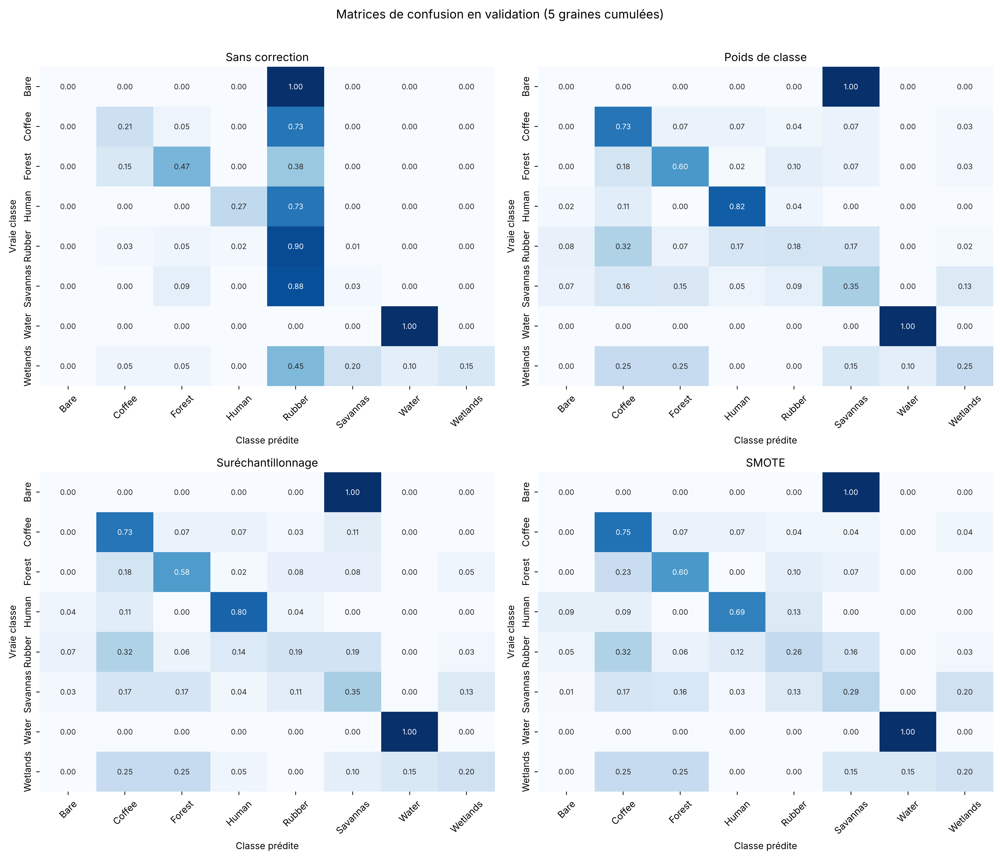

In [42]:

# Chaque ligne = une vraie classe ; la diagonale = le rappel de la classe ; hors diagonale = les confusions.

noms_courts = [n.split(" ")[0] for n in NOMS_CLASSES]          # noms abrégés pour la lisibilité
fig, axes = plt.subplots(2, 2, figsize=(15, 13))
for ax, met in zip(axes.ravel(), METHODES_E):
    cm = sum(confusion_matrix(y_val, predictions_E[(met, g)], labels=range(N_CLASSES)) for g in GRAINES)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=noms_courts, yticklabels=noms_courts, annot_kws={"fontsize": 8})
    ax.set_title(met, fontsize=12)
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Vraie classe")
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Matrices de confusion en validation (5 graines cumulées)", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Les matrices de confusion confirment la lecture précédente. Sans correction, le modèle classe presque tout en Rubber : 88 % des Savannas et 73 % des Coffee et des Human. Le rééquilibrage corrige ce biais. Le rappel progresse nettement pour Coffee (0,21 → 0,73–0,75), Human (0,27 → 0,69–0,82) et Forest (0,47 → 0,58–0,60), et Water reste parfaitement reconnue. En contrepartie, Rubber chute à 0,18–0,26, surtout au profit de Coffee (0,32). Comme Rubber représente 60 % de la validation, c’est ce qui fait baisser l’accuracy et la précision.

 Savannas (0,29–0,35) et Wetlands (0,20–0,25) restent dispersées entre Coffee, Forest et Savannas, ce qui rejoint l’analyse exploratoire : leurs signatures spectrales sont très proches, alors que celle de Water est distincte.  C’est pourquoi le Macro-F1 ne progresse pas nettement.

#### 5.7 courbes d'apprentissage des 5 graines pour chaque méthode

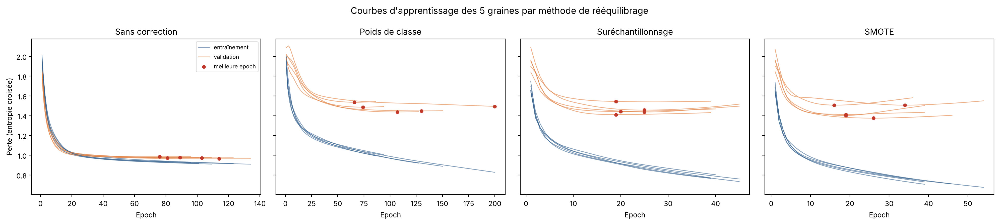

In [43]:

# Avec les poids de classe, la perte d'entraînement est pondérée : elle n'est pas directement comparable aux autres.

fig, axes = plt.subplots(1, len(METHODES_E), figsize=(20, 4.5), sharey=True)
for ax, met in zip(axes, METHODES_E):
    for graine in GRAINES:
        h = historiques_E[(met, graine)]
        epochs = np.arange(1, len(h["loss"]) + 1)
        premiere = graine == GRAINES[0]
        ax.plot(epochs, h["loss"], color="#2e5c8b", lw=1, alpha=0.6, label="entraînement" if premiere else None)
        ax.plot(epochs, h["val_loss"], color="#e07b39", lw=1, alpha=0.6, label="validation" if premiere else None)
        b = int(np.nanargmin(h["val_loss"]))
        ax.scatter(b + 1, h["val_loss"][b], color="#c0392b", s=18, zorder=3, label="meilleure epoch" if premiere else None)
    ax.set_title(met)
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("Perte (entropie croisée)")
axes[0].legend(fontsize=8)
fig.suptitle("Courbes d'apprentissage des 5 graines par méthode de rééquilibrage", fontsize=13)
plt.tight_layout()
plt.show()

Avec les trois méthodes, la perte d’entraînement descend plus bas que celle de la référence (environ 0,7–0,9 contre 0,9), tandis que la perte de validation plafonne vers 1,4–1,5, contre environ 0,97. Cet écart ne traduit pas un surapprentissage net : l’écart F1 entraînement − validation chevauche celui de la référence. Il vient surtout du fait que le modèle apprend sur des données rééquilibrées mais est évalué sur des données déséquilibrées. En validation, il se trompe souvent sur Rubber, la classe majoritaire, ce qui augmente la perte. Le suréchantillonnage et SMOTE s’arrêtent plus tôt (meilleure epoch vers 16–34, contre 76–114) car chaque epoch contient environ cinq fois plus de mises à jour. 

Synthèse de l’expérience E

L’objectif était de vérifier si une méthode de rééquilibrage aide le modèle à mieux reconnaître les classes rares. La réponse est en partie : les trois méthodes améliorent nettement le rappel macro (de 0,377 à 0,47–0,49), mais aucune n’améliore nettement le Macro-F1, critère principal (0,368–0,376 contre 0,389, chevauchement).

Le rééquilibrage change le poids accordé aux classes, mais pas l’information contenue dans les variables. Les trois méthodes se chevauchent entre elles sur tous les critères, et aucune ne modifie nettement le léger surapprentissage. SMOTE n’apporte rien de plus que le simple suréchantillonnage. 

Faute d’amélioration nette du Macro-F1, la référence sans correction est conservée pour la suite : ANN-3, SGD + Momentum (taux de 0,01, momentum de 0,5), GELU et arrêt anticipé seul.

***6. EXPERIENCE F***

In [44]:
# On réutilise : data, idx_train, idx_val, y_train, y_val, partitions, ARCHITECTURES, BANDES, INDICES, N_CLASSES,
# NOMS_CLASSES, calculer_metriques, instabilite, GRAINES, EPOCHS_MAX, PATIENCE, TAILLE_LOT.
from sklearn.metrics import confusion_matrix


# Modèle retenu à l'issue des expériences A à E (Référence, sans correction du déséquilibre)
ARCHI_F = "ANN-3"
LR_F, MOMENTUM_F = 0.01, 0.5      # SGD + Momentum
ACTIVATION_F = "gelu"


# Les configurations de l'énoncé ; seule la liste des variables d'entrée change
CONFIGS_F = {
    "F1 Bandes": BANDES,
    "F2 Indices": INDICES,
    "F3 Bandes + indices": BANDES + INDICES,
}
REFERENCE_F = "F3 Bandes + indices"     # les 19 variables utilisées depuis l'expérience A
CONFIGS_NOMS = list(CONFIGS_F)

for nom, cols in CONFIGS_F.items():
    print(f"{nom:22s} : {len(cols):2d} variables")
print(f"{len(CONFIGS_F)} configurations x {len(GRAINES)} graines = {len(CONFIGS_F) * len(GRAINES)} entraînements")

F1 Bandes              : 10 variables
F2 Indices             :  9 variables
F3 Bandes + indices    : 19 variables
3 configurations x 5 graines = 15 entraînements


#### 6.1 Relations mathematique entre les indices

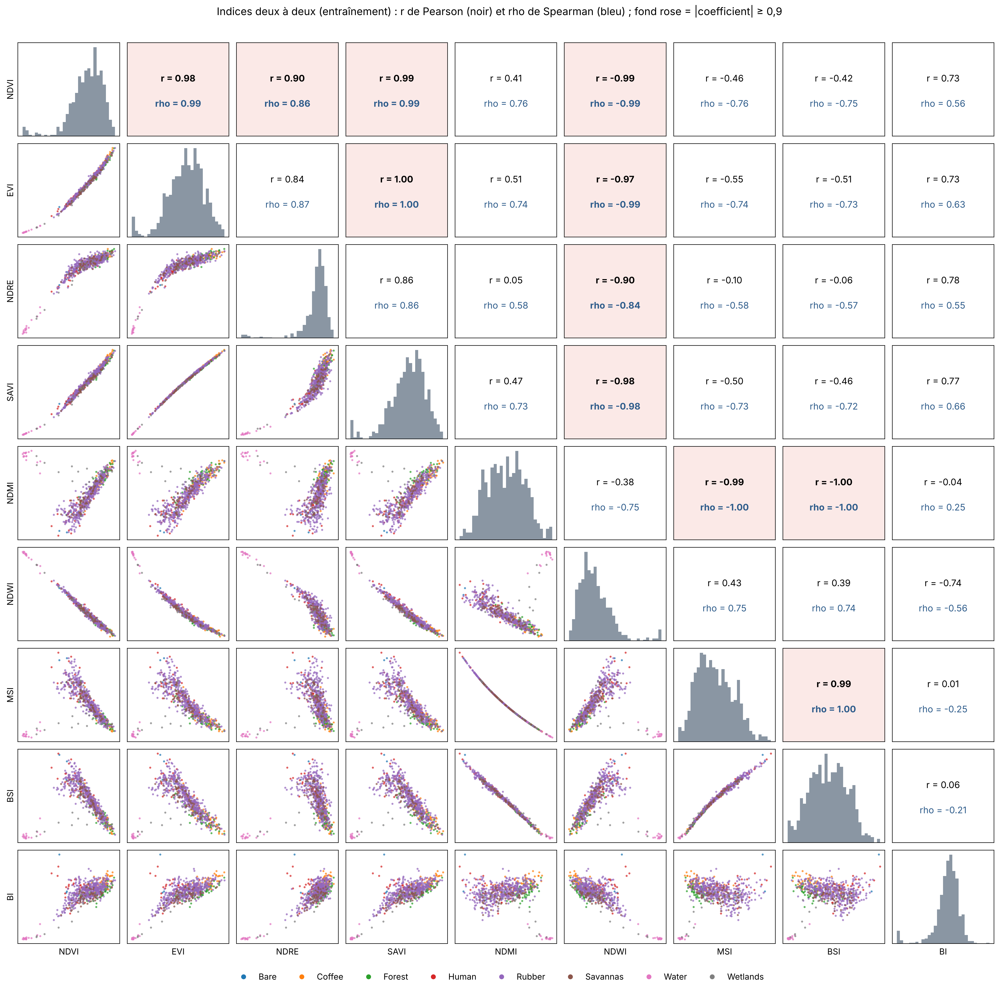

In [45]:
# Indices deux à deux (entraînement) : nuages de points en bas, r de Pearson et rho de Spearman en haut
indices_train = data.loc[idx_train, INDICES]
classes_train = data.loc[idx_train, "class_name"]
n = len(INDICES)

fig, axes = plt.subplots(n, n, figsize=(20, 20))
for i, a in enumerate(INDICES):          # a = ligne (axe vertical)
    for j, b in enumerate(INDICES):      # b = colonne (axe horizontal)
        ax = axes[i, j]
        if i > j:                        # triangle bas : nuage de points coloré par classe
            for nom in NOMS_CLASSES:
                sel = classes_train == nom
                ax.scatter(indices_train.loc[sel, b], indices_train.loc[sel, a], s=4, alpha=0.6,
                           color=COULEURS_CLASSES[nom])
        elif i == j:                     # diagonale : distribution de l'indice
            ax.hist(indices_train[a], bins=30, color="#8a96a3")
        else:                            # triangle haut : les deux coefficients
            r = indices_train[a].corr(indices_train[b], method="pearson")
            rho = indices_train[a].corr(indices_train[b], method="spearman")
            fort = max(abs(r), abs(rho)) >= 0.9
            ax.text(0.5, 0.62, f"r = {r:.2f}", ha="center", va="center", fontsize=13,
                    fontweight="bold" if fort else "normal", transform=ax.transAxes)
            ax.text(0.5, 0.35, f"rho = {rho:.2f}", ha="center", va="center", fontsize=13,
                    fontweight="bold" if fort else "normal", color="#2e5c8b", transform=ax.transAxes)
            ax.set_facecolor("#fbe9e7" if fort else "white")
        ax.set_xticks([]); ax.set_yticks([])
        if i == n - 1: ax.set_xlabel(b, fontsize=12)
        if j == 0: ax.set_ylabel(a, fontsize=12)

poignees = [Line2D([0], [0], marker="o", ls="", color=COULEURS_CLASSES[c], label=c.split(" ")[0]) for c in NOMS_CLASSES]
fig.legend(handles=poignees, loc="lower center", ncol=8, frameon=False, fontsize=12, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("Indices deux à deux (entraînement) : r de Pearson (noir) et rho de Spearman (bleu) ; fond rose = |coefficient| ≥ 0,9",
             fontsize=15)
plt.tight_layout(rect=[0, 0.025, 1, 0.97])
plt.show()


Croiser deux indices de familles différentes fait apparaître un début de séparation :

BI avec un indice de végétation ou d’humidité : Coffee se place nettement en haut des nuages, au-dessus de Forest.
NDMI, MSI ou BSI avec un indice de végétation : Forest et Coffee se regroupent vers l’extrémité humide et végétale, tandis que quelques points de Human se détachent vers l’extrémité sèche.
Water reste isolée dans toutes les paires, et quelques points de Wetlands s’en rapprochent.

Le nuage EVI–SAVI montre que toutes les classes se superposent le long d’une même ligne presque droite, y compris Bare Soil et Human Infrastructure, qui ne sont pas végétales. Seule l’eau s’en distingue nettement. Deux indices de la même famille ne séparent donc pas les classes.

Cette séparation reste partielle : Rubber et Savannas restent mélangées dans toutes les paires, ce qui rejoint leurs signatures spectrales proches vues dans l’analyse exploratoire. Les indices apportent donc une information complémentaire quand ils viennent de familles différentes, mais pas assez pour séparer toutes les classes végétales.

Côté coefficients, r et rho sont presque égaux pour les relations linéaires (EVI–SAVI : 1,00). 
Rho mesure mieux les relations courbes (NDMI–MSI : r = −0,99, rho = −1,00) et résiste aux valeurs extrêmes (NDMI–NDVI : r = 0,41, rho = 0,76, à cause des points isolés de Water).



#### 6.2 Matrice de correlation ( avec Spearman)

,indice 1,indice 2,rho
42,NDMI,MSI,-1.000
12,EVI,SAVI,0.999
43,NDMI,BSI,-0.997
61,MSI,BSI,0.997
1,NDVI,EVI,0.994
3,NDVI,SAVI,0.989
5,NDVI,NDWI,-0.987
14,EVI,NDWI,-0.986
32,SAVI,NDWI,-0.980


Écart maximal entre NDMI et (1 - MSI) / (1 + MSI) : 1.3e-05


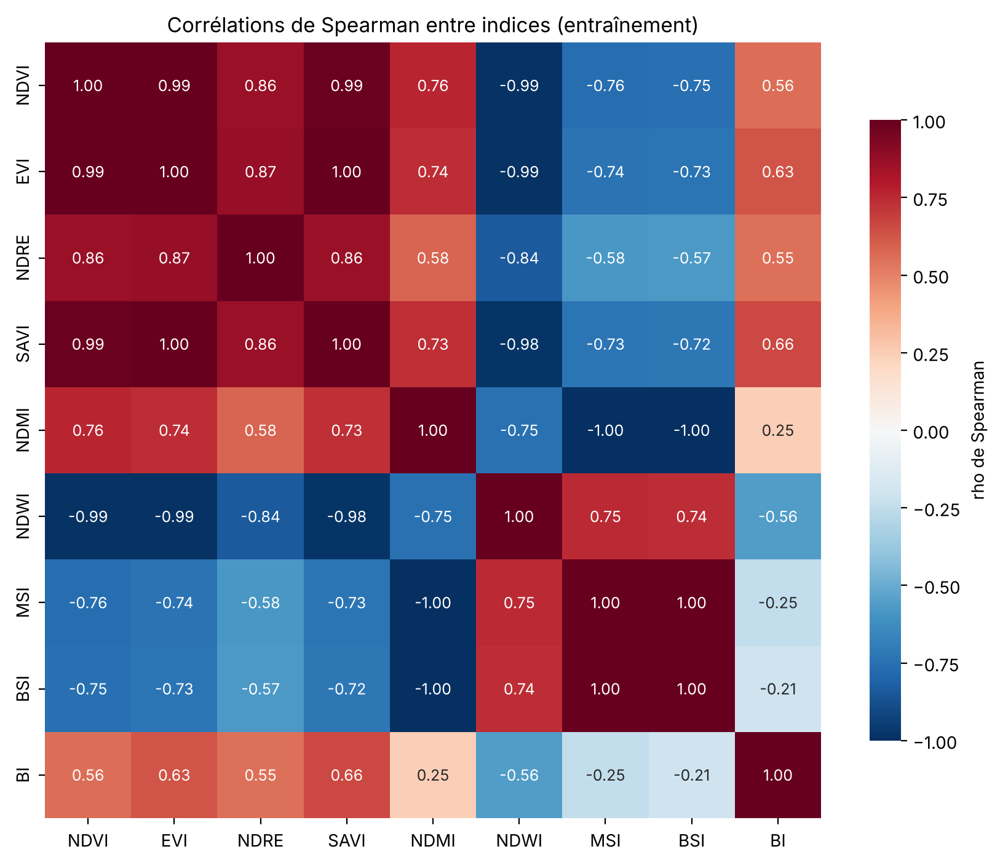

In [46]:
# Corrélation de Spearman : mesure si deux indices varient dans le même sens, même si la relation n'est pas linéaire.
indices_train = data.loc[idx_train, INDICES]
corr_ind = indices_train.corr(method="spearman")

# Paires d'indices très corrélées (|rho| >= 0,9)
masque = np.triu(np.ones(corr_ind.shape, dtype=bool), k=1)
paires = corr_ind.where(masque).stack().rename("rho").reset_index()
paires.columns = ["indice 1", "indice 2", "rho"]
paires = paires.loc[paires["rho"].abs() >= 0.9].sort_values("rho", key=np.abs, ascending=False)
display(paires.round(3))

# Relation exacte : NDMI = (PIR - SWIR) / (PIR + SWIR) et MSI = SWIR / PIR, donc NDMI = (1 - MSI) / (1 + MSI)
ecart_max = np.abs(indices_train["NDMI"] - (1 - indices_train["MSI"]) / (1 + indices_train["MSI"])).max()
print(f"Écart maximal entre NDMI et (1 - MSI) / (1 + MSI) : {ecart_max:.1e}")

# Matrice de corrélation
plt.figure(figsize=(8.5, 7))
sns.heatmap(corr_ind, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.8, "label": "rho de Spearman"}, annot_kws={"fontsize": 9})
plt.title("Corrélations de Spearman entre indices (entraînement)")
plt.tight_layout()
plt.show()

La matrice confirme deux familles d’indices fortement redondants. Dans la famille végétation, NDVI, EVI, SAVI et NDWI  sont liés par |ρ| de 0,98 à 0,99, et NDRE un peu moins (0,84 à 0,87). Dans la famille humidité / infrarouge moyen, NDMI, MSI et BSI sont liés par |ρ| = 1,00 
Les deux familles restent liées sans être confondues (|ρ| ≈ 0,72–0,76), et BI reste à part (|ρ| ≤ 0,66). L’information des 9 indices se résume donc à quelques signaux distincts, ce qui limite a priori le gain attendu de leur fusion avec les bandes.

#### 6.3 Fonctions de l'expérience F

Chaque configuration a sa propre standardisation, apprise sur l'entraînement. Le contrôle final vérifie que F3 redonne exactement les données utilisées depuis l'expérience A.

In [47]:
def matrices_config(config):
    """Sélectionne les variables d'une configuration et les standardise (paramètres appris sur l'entraînement)."""
    cols = CONFIGS_F[config]
    brut = data[cols].to_numpy(dtype="float32")
    norm = StandardScaler().fit(brut[idx_train])
    return norm.transform(brut[idx_train]), norm.transform(brut[idx_val])


def construire_modele_F(n_entrees):
    """ANN-3 avec GELU et SGD + Momentum ; seule la taille de l'entrée change selon la configuration."""
    modele = keras.Sequential(name="ANN_3_F")
    modele.add(keras.Input(shape=(n_entrees,)))
    for n in ARCHITECTURES[ARCHI_F]:
        modele.add(layers.Dense(n))
        modele.add(layers.Activation(ACTIVATION_F))
    modele.add(layers.Dense(N_CLASSES, activation="softmax"))
    modele.compile(optimizer=keras.optimizers.SGD(learning_rate=LR_F, momentum=MOMENTUM_F),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modele


def entrainer_F(config, graine):
    """Entraîne le modèle sur une configuration de variables avec une graine ; évalue sur la validation."""
    X_tr, X_va = matrices_config(config)
    keras.utils.set_random_seed(graine)
    modele = construire_modele_F(X_tr.shape[1])
    arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    debut = time.perf_counter()
    hist = modele.fit(X_tr, y_train, validation_data=(X_va, y_val), epochs=EPOCHS_MAX, batch_size=TAILLE_LOT,
                      callbacks=[arret, keras.callbacks.TerminateOnNaN()], verbose=0)
    duree = time.perf_counter() - debut

    pred_train = modele.predict(X_tr, verbose=0).argmax(axis=1)
    pred_val = modele.predict(X_va, verbose=0).argmax(axis=1)
    m_train, m_val = calculer_metriques(y_train, pred_train), calculer_metriques(y_val, pred_val)
    pertes_val = np.array(hist.history["val_loss"], dtype=float)
    ligne = {
        "config": config, "graine": graine,
        "n_variables": X_tr.shape[1],
        "parametres": modele.count_params(),
        "epochs_effectuees": len(pertes_val),
        "meilleure_epoch": int(np.nanargmin(pertes_val)) + 1,
        "temps_s": duree,
        "instabilite_val": instabilite(pertes_val),
        **{f"val_{k}": v for k, v in m_val.items()},
        "train_f1_macro": m_train["f1_macro"],
        "ecart_f1_train_val": m_train["f1_macro"] - m_val["f1_macro"],
    }
    f1_classes = f1_score(y_val, pred_val, average=None, labels=range(N_CLASSES), zero_division=0)
    return ligne, hist.history, f1_classes, pred_val


# Contrôle : F3 doit redonner exactement les données des expériences précédentes
assert np.allclose(matrices_config(REFERENCE_F)[0], X_train, atol=1e-5), "F3 ne correspond pas à X_train !"

#### 6.4 Entraînement : 3 configurations x 5 graines

In [48]:
resultats_F, historiques_F, f1_classes_F, predictions_F = [], {}, {}, {}

for config in CONFIGS_F:
    for graine in GRAINES:
        ligne, histo, f1c, pred = entrainer_F(config, graine)
        resultats_F.append(ligne)
        historiques_F[(config, graine)] = histo
        f1_classes_F[(config, graine)] = f1c
        predictions_F[(config, graine)] = pred
        print(f"{config:22s} | graine {graine} | {ligne['epochs_effectuees']:3d} epochs | "
              f"Macro-F1 val = {ligne['val_f1_macro']:.3f} | écart = {ligne['ecart_f1_train_val']:.3f} | "
              f"{ligne['temps_s']:.1f} s")

resultats_F = pd.DataFrame(resultats_F)

F1 Bandes              | graine 0 | 178 epochs | Macro-F1 val = 0.373 | écart = 0.074 | 22.3 s
F1 Bandes              | graine 1 | 170 epochs | Macro-F1 val = 0.356 | écart = 0.107 | 22.2 s
F1 Bandes              | graine 2 | 148 epochs | Macro-F1 val = 0.343 | écart = 0.095 | 19.7 s
F1 Bandes              | graine 3 | 117 epochs | Macro-F1 val = 0.421 | écart = -0.013 | 15.2 s
F1 Bandes              | graine 4 | 111 epochs | Macro-F1 val = 0.333 | écart = 0.053 | 14.2 s
F2 Indices             | graine 0 | 174 epochs | Macro-F1 val = 0.387 | écart = 0.044 | 22.5 s
F2 Indices             | graine 1 | 157 epochs | Macro-F1 val = 0.347 | écart = 0.085 | 21.3 s
F2 Indices             | graine 2 | 148 epochs | Macro-F1 val = 0.308 | écart = 0.112 | 20.1 s
F2 Indices             | graine 3 | 130 epochs | Macro-F1 val = 0.403 | écart = 0.034 | 16.1 s
F2 Indices             | graine 4 | 157 epochs | Macro-F1 val = 0.296 | écart = 0.131 | 21.1 s
F3 Bandes + indices    | graine 0 | 123 epochs | 

#### 6.5 Tableau récapitulatif

In [49]:
colonnes_F = ["val_f1_macro", "val_recall_macro", "val_precision_macro", "val_mcc", "val_accuracy",
              "ecart_f1_train_val", "meilleure_epoch", "temps_s"]
recap_F = resultats_F.groupby("config")[colonnes_F].agg(["mean", "std"]).loc[CONFIGS_NOMS]
tableau_F = pd.DataFrame(index=recap_F.index)
tableau_F["nbr_var"] = resultats_F.groupby("config")["n_variables"].first().loc[CONFIGS_NOMS]
tableau_F["paramètres"] = resultats_F.groupby("config")["parametres"].first().loc[CONFIGS_NOMS]
for c in colonnes_F:
    dec = 0 if c == "meilleure_epoch" else (1 if c == "temps_s" else 3)
    tableau_F[c] = [f"{m:.{dec}f} ± {s:.{dec}f}" for m, s in zip(recap_F[(c, "mean")], recap_F[(c, "std")])]
display(tableau_F)

,nbr_var,paramètres,val_f1_macro,val_recall_macro,val_precision_macro,val_mcc,val_accuracy,ecart_f1_train_val,meilleure_epoch,temps_s
config,,,,,,,,,,
F1 Bandes,10,12008,0.365 ± 0.035,0.362 ± 0.022,0.436 ± 0.084,0.329 ± 0.033,0.648 ± 0.012,0.063 ± 0.048,125 ± 30,18.7 ± 3.8
F2 Indices,9,11880,0.348 ± 0.047,0.348 ± 0.033,0.429 ± 0.107,0.312 ± 0.031,0.644 ± 0.008,0.081 ± 0.042,133 ± 16,20.2 ± 2.4
F3 Bandes + indices,19,13160,0.389 ± 0.041,0.377 ± 0.023,0.469 ± 0.097,0.330 ± 0.025,0.645 ± 0.011,0.054 ± 0.034,93 ± 16,15.0 ± 2.8


aucune famille de variables ne se distingue nettement de la référence F3. La fusion bandes + indices obtient le meilleur Macro-F1 (0,389), devant les bandes seules (0,365) et les indices seuls (0,348). Les seuls écarts nets concernent la convergence : F3 atteint sa meilleure epoch plus tôt que F2 (93 ± 16 contre 133 ± 16) et s’entraîne plus vite (35,2 ± 3,4 s contre 44,7 ± 3,9 s). Ce résultat s’explique par le fait que les indices sont calculés à partir des bandes et sont fortement redondants entre eux (relation exacte NDMI–MSI, 9 paires avec |ρ| ≥ 0,98) : ils n’apportent pas d’information nettement nouvelle par rapport aux bandes seules.

#### 6.6 Bandes de chevauchement avec la Référence (F3)

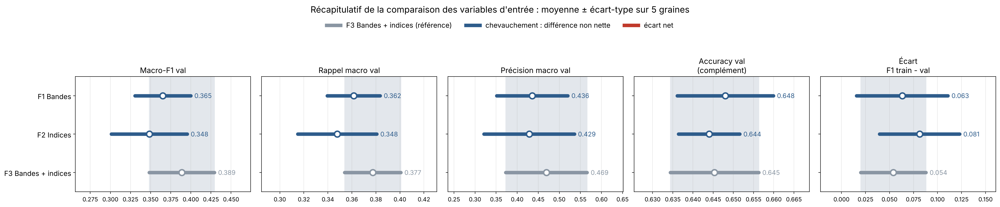

In [50]:
# Gris = Référence ; bleu = chevauchement (différence non nette) ; rouge = écart net.
criteres_F = [("val_f1_macro", "Macro-F1 val", ".3f"),
              ("val_recall_macro", "Rappel macro val", ".3f"),
              ("val_precision_macro", "Précision macro val", ".3f"),
              ("val_accuracy", "Accuracy val\n(complément)", ".3f"),
              ("ecart_f1_train_val", "Écart\nF1 train - val", ".3f")]
stats_F = resultats_F.groupby("config")[[c for c, _, _ in criteres_F]].agg(["mean", "std"]).loc[CONFIGS_NOMS]

fig, axes = plt.subplots(1, len(criteres_F), figsize=(24, 5), sharey=True)
y_pos = np.arange(len(CONFIGS_NOMS))[::-1]
for ax, (col, titre, fmt) in zip(axes, criteres_F):
    m, s = stats_F[(col, "mean")], stats_F[(col, "std")]
    bas_ref, haut_ref = m[REFERENCE_F] - s[REFERENCE_F], m[REFERENCE_F] + s[REFERENCE_F]
    ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")
    for yi, cfg in zip(y_pos, CONFIGS_NOMS):
        bas, haut = m[cfg] - s[cfg], m[cfg] + s[cfg]
        c = "#8a96a3" if cfg == REFERENCE_F else ("#2e5c8b" if bas <= haut_ref and haut >= bas_ref else "#c0392b")
        ax.plot([bas, haut], [yi, yi], color=c, lw=6, solid_capstyle="round")
        ax.plot(m[cfg], yi, "o", color="white", mec=c, mew=2.5, ms=10)
        ax.text(haut, yi, f"  {m[cfg]:{fmt}}", va="center", fontsize=11, color=c)
    ax.set_title(titre, fontsize=13)
    ax.margins(x=0.35, y=0.25)
    ax.grid(axis="x", alpha=0.3)
    ax.tick_params(axis="x", labelsize=10)
axes[0].set_yticks(y_pos, CONFIGS_NOMS)
axes[0].tick_params(axis="y", labelsize=12)
legende = [Line2D([0], [0], color="#8a96a3", lw=6, label="F3 Bandes + indices (référence)"),
           Line2D([0], [0], color="#2e5c8b", lw=6, label="chevauchement : différence non nette"),
           Line2D([0], [0], color="#c0392b", lw=6, label="écart net")]
fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.93), frameon=False, fontsize=12)
fig.suptitle("Récapitulatif de la comparaison des variables d'entrée : moyenne ± écart-type sur 5 graines", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.84])
plt.show()

Sur les cinq critères, toutes les barres sont bleues : ni les bandes seules (F1) ni les indices seuls (F2) ne s’écartent nettement de la référence F3. Une tendance cohérente apparaît néanmoins. F3 obtient les meilleures moyennes en Macro-F1 (0,389) et en rappel macro (0,377), ainsi que l’écart train − val le plus faible (0,054). F2 est systématiquement en dernière position, et son intervalle ne recouvre qu’en partie la zone de référence pour le Macro-F1 et le rappel macro. La précision macro, bien que plus élevée pour F3 (0,469), est trop dispersée pour départager les configurations, et l’accuracy est quasi identique pour les trois (≈ 0,645). La fusion des bandes et des indices n’apporte donc pas de gain net comme le montrait la forte redondance observée entre les indices et du fait qu'ils soient construire a partir des bandes.

#### 6.7 F1 par classe

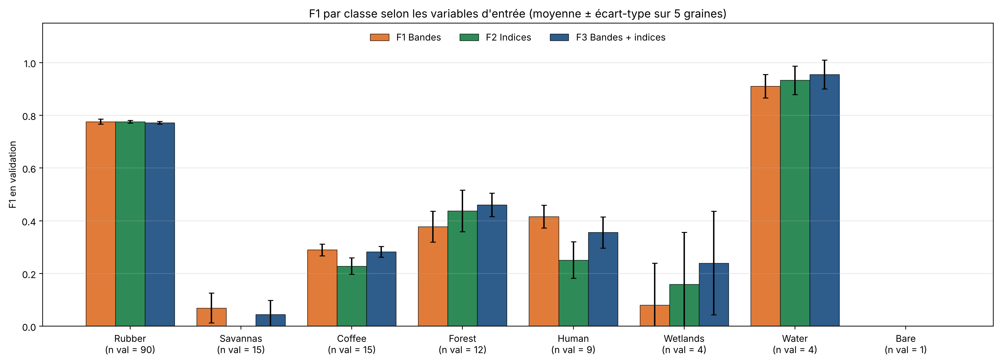

In [51]:
COULEURS_CONFIGS = {"F1 Bandes": "#e07b39", "F2 Indices": "#2e8b57", "F3 Bandes + indices": "#2e5c8b"}
ordre_classes = np.argsort(np.bincount(y_train))[::-1]           # de la plus fréquente à la plus rare
noms_courts = [n.split(" ")[0] for n in NOMS_CLASSES]

fig, ax = plt.subplots(figsize=(15, 5.5))
largeur = 0.8 / len(CONFIGS_NOMS)
for j, cfg in enumerate(CONFIGS_NOMS):
    f1s = np.array([f1_classes_F[(cfg, g)] for g in GRAINES])[:, ordre_classes]   # graines x classes
    pos = np.arange(len(ordre_classes)) + (j - (len(CONFIGS_NOMS) - 1) / 2) * largeur
    ax.bar(pos, f1s.mean(axis=0), largeur, yerr=f1s.std(axis=0), capsize=3,
           color=COULEURS_CONFIGS[cfg], edgecolor="black", lw=0.5, label=cfg)
ax.set_xticks(np.arange(len(ordre_classes)),
              [f"{noms_courts[k]}\n(n val = {np.sum(y_val == k)})" for k in ordre_classes])
ax.set_ylabel("F1 en validation")
ax.set_ylim(0, 1.15)
ax.grid(axis="y", alpha=0.3)
ax.legend(ncol=3, loc="upper center", frameon=False)
ax.set_title("F1 par classe selon les variables d'entrée (moyenne ± écart-type sur 5 graines)")
plt.tight_layout()
plt.show()

Le profil des classes est conservé : Rubber et Water sont bien reconnues dans les trois configurations, tandis que Bare Soil ne l’est jamais. Les deux familles de variables apparaissent toutefois complémentaires. Les bandes seules reconnaissent mieux les zones bâties (Human : environ 0,42 contre 0,25 avec les indices seuls, seul écart net entre F1 et F2), ainsi que Coffee et Savannas, cette dernière n’étant jamais reconnue avec les indices seuls. À l’inverse, les indices améliorent la reconnaissance de Forest (environ 0,44 contre 0,38). La fusion (F3) n’est presque jamais la configuration la moins bonne, ce qui suggère qu’elle combine les apports des deux familles ; ces gains se compensant d’une classe à l’autre, le Macro-F1 global ne se distingue pas nettement. Les résultats pour Wetlands et Water (4 cas en validation) et Bare Soil (1 cas) restent trop instables pour être interprétés.

#### 6.8 Matrices de confusion (validation, 5 graines cumulées)

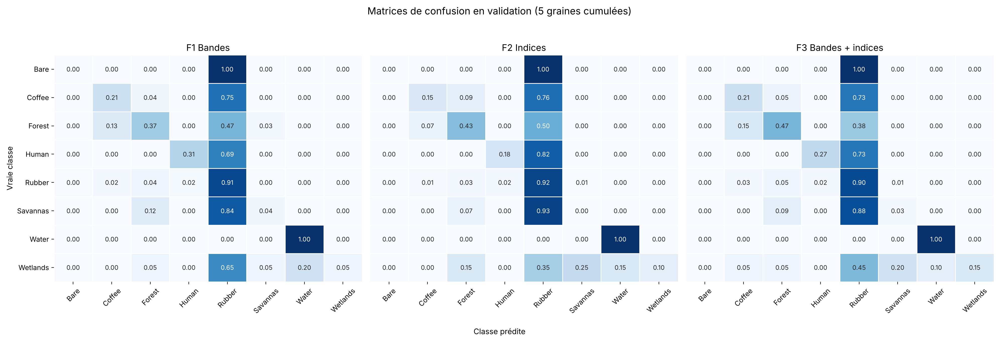

In [52]:
# Chaque ligne = une vraie classe ; la diagonale = le rappel de la classe ; hors diagonale = les confusions.
fig, axes = plt.subplots(1, len(CONFIGS_NOMS), figsize=(20, 6.8), sharey=True)
for k, (ax, cfg) in enumerate(zip(axes, CONFIGS_NOMS)):
    cm = sum(confusion_matrix(y_val, predictions_F[(cfg, g)], labels=range(N_CLASSES)) for g in GRAINES)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=noms_courts, yticklabels=noms_courts, annot_kws={"fontsize": 9},
                linewidths=0.5, linecolor="white")
    ax.set_title(cfg, fontsize=13)
    ax.set_xlabel("")
    ax.set_ylabel("Vraie classe" if k == 0 else "", fontsize=11)                            # un seul axe de lecture, à gauche
    ax.tick_params(axis="x", rotation=45, labelsize=10)
    ax.tick_params(axis="y", rotation=0, labelsize=10, left=(k == 0), labelleft=(k == 0))  # noms à l'horizontale
fig.supxlabel("Classe prédite", fontsize=11)                                               # un seul titre d'axe en bas
fig.suptitle("Matrices de confusion en validation (5 graines cumulées)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Les matrices de confusion montrent que, quelle que soit la configuration, les classes minoritaires sont mal reconnues, leurs observations sont le plus souvent classées à tort comme Rubber qui est la classe majoritaire : Bare Soil y est entièrement absorbée, ainsi que 84 à 93 % de Savannas, 69 à 82 % de Human et environ 75 % de Coffee. Le choix des variables modifie cependant certaines confusions. Avec les indices seuls, Human est davantage confondue avec Rubber (82 % contre 69 % avec les bandes), ce qui indique que les bandes conservent une information utile pour distinguer le bâti. À l’inverse, la fusion améliore la reconnaissance de Forest (rappel de 0,47 contre 0,37 et 0,43) en réduisant sa confusion avec Rubber (0,38 contre 0,47 et 0,50). Des confusions persistent entre classes végétales (Savannas et Coffee vers Forest), conformément au chevauchement spectral observé dans l’expérience E. Les répartitions de Wetlands (4 cas en validation) restent trop instables pour être interprétées, une case de 0,05 correspondant à une seule prédiction.

La classe Rubber and Other Crops regroupe l’hévéa et d’autres cultures non précisées. Cette nature composite peut expliquer à la fois sa bonne reconnaissance et les confusions avec les autres classes : couvrant des signatures spectrales variées, proches de celles des autres couverts végétaux, elle attire leurs observations, que le modèle, déjà orienté par sa forte majorité, classe alors plus facilement comme Rubber.

#### 6.9 Courbes d'apprentissage des 5 graines pour chaque configuration

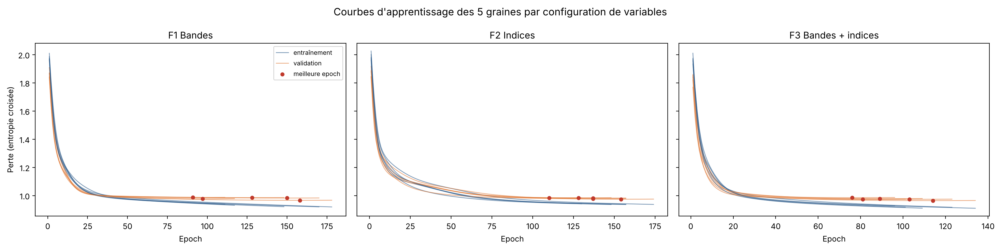

In [53]:
fig, axes = plt.subplots(1, len(CONFIGS_NOMS), figsize=(18, 4.5), sharey=True)
for ax, cfg in zip(axes, CONFIGS_NOMS):
    for graine in GRAINES:
        h = historiques_F[(cfg, graine)]
        epochs = np.arange(1, len(h["loss"]) + 1)
        premiere = graine == GRAINES[0]
        ax.plot(epochs, h["loss"], color="#2e5c8b", lw=1, alpha=0.6, label="entraînement" if premiere else None)
        ax.plot(epochs, h["val_loss"], color="#e07b39", lw=1, alpha=0.6, label="validation" if premiere else None)
        b = int(np.nanargmin(h["val_loss"]))
        ax.scatter(b + 1, h["val_loss"][b], color="#c0392b", s=18, zorder=3, label="meilleure epoch" if premiere else None)
    ax.set_title(cfg)
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("Perte (entropie croisée)")
axes[0].legend(fontsize=8)
fig.suptitle("Courbes d'apprentissage des 5 graines par configuration de variables", fontsize=13)
plt.tight_layout()
plt.show()

Les courbes d’apprentissage sont régulières dans les trois configurations, sans oscillation ni remontée de la perte de validation. Avec les bandes (F1) et la fusion (F3), la perte diminue rapidement et se stabilise vers l’epoch 20 à 25, tandis qu’avec les indices seuls (F2), la descente est plus lente et plus variable d’une graine à l’autre, ce qui explique une meilleure epoch plus tardive (133 ± 16 contre 93 ± 16 pour F3). Les trois configurations atteignent néanmoins une perte de validation finale très proche (environ 0,97 à 0,98), en accord avec le chevauchement observé sur le Macro-F1. L’écart entre les pertes d’entraînement et de validation reste faible, et l’arrêt anticipé intervient sur un plateau, sans surapprentissage marqué.

Synthèse de l’expérience F

L’objectif était de déterminer quelles familles de variables contribuent le plus à la classification, en comparant les bandes spectrales seules (F1), les indices seuls (F2) et leur fusion (F3, référence). Le modèle (ANN-3, SGD + Momentum, GELU), les partitions et les graines sont restés identiques ; seule la liste des variables d’entrée a changé.

Les bandes spectrales suffisent-elles ? Oui, en grande partie. Avec 10 variables, F1 obtient un Macro-F1 de 0,365 ± 0,035, qui chevauche celui de la référence (0,389 ± 0,041). Les bandes reconnaissent même mieux les zones bâties (Human) que les indices.

Les indices sont-ils plus discriminants ? Non. F2 obtient les moyennes les plus basses (Macro-F1 de 0,348 ± 0,047) et converge plus lentement : c’est le seul écart net de l’expérience (meilleure epoch 133 ± 16 contre 93 ± 16 pour F3). L’analyse des corrélations explique ce résultat. Les indices sont calculés à partir des bandes et sont très redondants entre eux : 9 paires ont |ρ| ≥ 0,98, et NDMI et MSI sont liés par une relation exacte. Les 9 indices résument en pratique trois informations : végétation, humidité / infrarouge moyen et brillance. Ils améliorent toutefois la reconnaissance de Forest.

La fusion améliore-t-elle les résultats ? Pas de façon nette. F3 obtient les meilleures moyennes en Macro-F1, en rappel et en précision macro, ainsi que l’écart train − val le plus faible (0,054 ± 0,034), mais tous les intervalles se chevauchent. Au niveau des classes, les deux familles apparaissent complémentaires : la fusion n’est presque jamais la moins bonne configuration. Ces gains se compensent cependant d’une classe à l’autre.

Quelles que soient les variables, la principale limite reste la même : la plupart des erreurs se font vers la classe majoritaire Rubber, et les classes végétales restent confondues entre elles. Changer les variables d’entrée ne résout pas le chevauchement spectral observé dans l’expérience E.

Configuration retenue : F3 (bandes + indices) est conservée comme entrée du modèle. Elle ne se distingue pas nettement, mais elle obtient les meilleures moyennes, converge le plus vite et ne coûte que 1 152 paramètres de plus que F1 (13 160 contre 12 008).

### 7. Sélection de variables, double validation et configuration finale de l'ANN

#### 7.1 Sélection automatique des variables : mRMR

mRMR  classe les variables en choisissant à chaque étape celle qui apporte le plus d'information sur la classe tout en répétant le moins possible les variables déjà choisies. 

,variable,famille,pertinence,redondance,score_mrmr
rang,,,,,
1,SAVI,indice,0.306,0.000,0.306
2,B1,bande,0.140,0.153,-0.013
3,B9,bande,0.258,0.356,-0.098
4,BI,indice,0.164,0.326,-0.163
5,NDRE,indice,0.262,0.426,-0.164
6,B2,bande,0.262,0.481,-0.219
7,B7,bande,0.262,0.508,-0.246
8,B10,bande,0.303,0.530,-0.227
9,B4,bande,0.250,0.546,-0.297


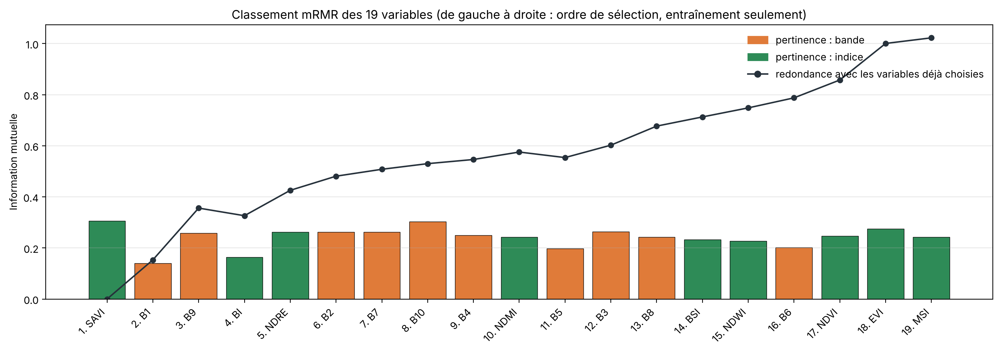

In [54]:


VARIABLES_F3 = CONFIGS_F[REFERENCE_F]
X_mrmr = data.loc[idx_train, VARIABLES_F3].to_numpy(dtype="float32")     # entraînement uniquement
pertinence = mutual_info_classif(X_mrmr, y_train, random_state=0)       # information mutuelle variable / classe

choisies, restantes, lignes_mrmr = [], list(range(len(VARIABLES_F3))), []
redondance_cumulee = np.zeros(len(VARIABLES_F3))
while restantes:
    if choisies:                                                        # MI entre la dernière choisie et les restantes
        derniere = choisies[-1]
        mi = mutual_info_regression(X_mrmr[:, restantes], X_mrmr[:, derniere], random_state=0)
        redondance_cumulee[restantes] += mi
    redondance = redondance_cumulee[restantes] / max(len(choisies), 1)
    scores = pertinence[restantes] - redondance
    meilleure = restantes[int(np.argmax(scores))]
    lignes_mrmr.append({"rang": len(choisies) + 1, "variable": VARIABLES_F3[meilleure],
                        "famille": "bande" if VARIABLES_F3[meilleure] in BANDES else "indice",
                        "pertinence": pertinence[meilleure],
                        "redondance": redondance[restantes.index(meilleure)],
                        "score_mrmr": scores.max()})
    choisies.append(meilleure)
    restantes.remove(meilleure)

classement_mrmr = pd.DataFrame(lignes_mrmr).set_index("rang")
ORDRE_MRMR = list(classement_mrmr["variable"])
display(classement_mrmr.round(3))

# Graphique : pertinence et redondance de chaque variable, dans l'ordre de sélection
fig, ax = plt.subplots(figsize=(14, 5))
pos = np.arange(len(ORDRE_MRMR))
couleurs_fam = ["#e07b39" if f == "bande" else "#2e8b57" for f in classement_mrmr["famille"]]
ax.bar(pos, classement_mrmr["pertinence"], color=couleurs_fam, edgecolor="black", lw=0.5)
ax.plot(pos, classement_mrmr["redondance"], "o-", color="#26313b", lw=1.5, ms=5)
ax.set_xticks(pos, [f"{r}. {v}" for r, v in zip(classement_mrmr.index, ORDRE_MRMR)], rotation=45, ha="right")
ax.set_ylabel("Information mutuelle")
ax.grid(axis="y", alpha=0.3)
ax.legend(handles=[Patch(color="#e07b39", label="pertinence : bande"), Patch(color="#2e8b57", label="pertinence : indice"),
                   Line2D([0], [0], color="#26313b", marker="o", label="redondance avec les variables déjà choisies")],
          frameon=False, loc="upper right")
ax.set_title("Classement mRMR des 19 variables (de gauche à droite : ordre de sélection, entraînement seulement)")
plt.tight_layout()
plt.show()

Le classement mRMR, calculé sur l’entraînement, retient d’abord SAVI : c’est la variable la plus pertinente (information mutuelle de 0,31), et aucune autre n’a encore été choisie. Viennent ensuite B1, B9, BI, NDRE et B2. Ces variables ne sont pas toujours les plus pertinentes seules, mais elles répètent peu celles déjà retenues. B1, par exemple, est peu pertinente (0,14) mais très peu redondante avec SAVI. À l’inverse, des variables pertinentes comme EVI (0,28) ou MSI arrivent en dernier, car leur redondance atteint environ 1,0 : elles répètent respectivement SAVI et NDMI. La redondance augmente tout au long du classement alors que la pertinence reste stable (0,2 à 0,3) : chaque nouvelle variable apporte de moins en moins d’information nouvelle. On retrouve ainsi, de façon automatique, les deux familles d’indices redondants observées dans la matrice de corrélation.

#### 7.2 ANN avec les k premières variables mRMR (5 graines par valeur de k)

In [55]:
VALEURS_K = [6, 8, 10, 12, 14, 16]
CONFIGS_MRMR = []
for k in VALEURS_K:
    nom = f"mRMR k = {k}"
    CONFIGS_F[nom] = ORDRE_MRMR[:k]          # entrainer_F lit les variables dans CONFIGS_F
    CONFIGS_MRMR.append(nom)

resultats_mrmr = []
for nom in CONFIGS_MRMR:
    for graine in GRAINES:
        ligne, _, _, _ = entrainer_F(nom, graine)
        resultats_mrmr.append(ligne)
    f1s = [r["val_f1_macro"] for r in resultats_mrmr if r["config"] == nom]
    print(f"{nom:12s} | Macro-F1 val = {np.mean(f1s):.3f} ± {np.std(f1s, ddof=1):.3f}")

resultats_mrmr = pd.concat([resultats_F.loc[resultats_F["config"] == REFERENCE_F], pd.DataFrame(resultats_mrmr)])
CONFIGS_COMP = CONFIGS_MRMR + [REFERENCE_F]

cols_m = ["val_f1_macro", "val_recall_macro", "val_precision_macro", "val_accuracy", "ecart_f1_train_val", "temps_s"]
recap_m = resultats_mrmr.groupby("config")[cols_m].agg(["mean", "std"]).loc[CONFIGS_COMP]
tableau_m = pd.DataFrame(index=recap_m.index)
tableau_m["nbr_var"] = [len(CONFIGS_F[c]) for c in CONFIGS_COMP]
for c in cols_m:
    dec = 1 if c == "temps_s" else 3
    tableau_m[c] = [f"{m:.{dec}f} ± {s:.{dec}f}" for m, s in zip(recap_m[(c, "mean")], recap_m[(c, "std")])]
display(tableau_m)

mRMR k = 6   | Macro-F1 val = 0.381 ± 0.036
mRMR k = 8   | Macro-F1 val = 0.377 ± 0.052
mRMR k = 10  | Macro-F1 val = 0.374 ± 0.049
mRMR k = 12  | Macro-F1 val = 0.375 ± 0.049
mRMR k = 14  | Macro-F1 val = 0.375 ± 0.049
mRMR k = 16  | Macro-F1 val = 0.374 ± 0.047


,nbr_var,val_f1_macro,val_recall_macro,val_precision_macro,val_accuracy,ecart_f1_train_val,temps_s
config,,,,,,,
mRMR k = 6,6,0.381 ± 0.036,0.369 ± 0.023,0.525 ± 0.076,0.653 ± 0.005,0.042 ± 0.027,72.5 ± 33.2
mRMR k = 8,8,0.377 ± 0.052,0.371 ± 0.032,0.454 ± 0.132,0.643 ± 0.012,0.057 ± 0.047,54.7 ± 9.5
mRMR k = 10,10,0.374 ± 0.049,0.368 ± 0.027,0.457 ± 0.143,0.647 ± 0.016,0.061 ± 0.047,54.0 ± 14.7
mRMR k = 12,12,0.375 ± 0.049,0.369 ± 0.027,0.474 ± 0.159,0.648 ± 0.017,0.067 ± 0.043,44.2 ± 9.1
mRMR k = 14,14,0.375 ± 0.049,0.369 ± 0.027,0.472 ± 0.156,0.648 ± 0.014,0.059 ± 0.053,37.8 ± 4.4
mRMR k = 16,16,0.374 ± 0.047,0.368 ± 0.027,0.459 ± 0.138,0.644 ± 0.015,0.071 ± 0.064,37.3 ± 4.5
F3 Bandes + indices,19,0.389 ± 0.041,0.377 ± 0.023,0.469 ± 0.097,0.645 ± 0.011,0.054 ± 0.034,35.2 ± 3.4


#### 7.3 Bandes de chevauchement : k premières variables mRMR contre F3

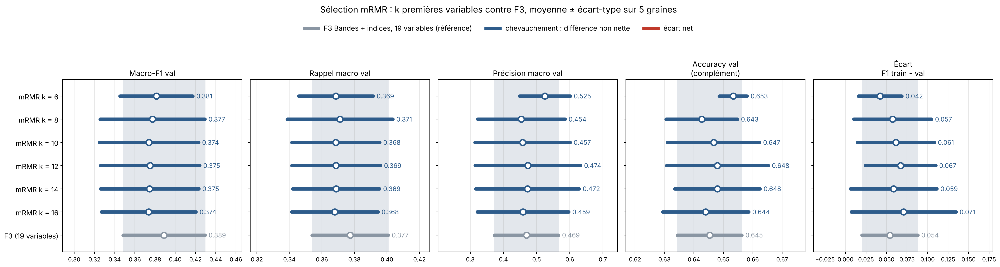

In [56]:
# Gris = F3 (19 variables) ; bleu = chevauchement (différence non nette) ; rouge = écart net.
criteres_m = [("val_f1_macro", "Macro-F1 val"),
              ("val_recall_macro", "Rappel macro val"),
              ("val_precision_macro", "Précision macro val"),
              ("val_accuracy", "Accuracy val\n(complément)"),
              ("ecart_f1_train_val", "Écart\nF1 train - val")]
stats_m = resultats_mrmr.groupby("config")[[c for c, _ in criteres_m]].agg(["mean", "std"]).loc[CONFIGS_COMP]

fig, axes = plt.subplots(1, len(criteres_m), figsize=(24, 6.5), sharey=True)
y_pos = np.arange(len(CONFIGS_COMP))[::-1]
for ax, (col, titre) in zip(axes, criteres_m):
    m, s = stats_m[(col, "mean")], stats_m[(col, "std")]
    bas_ref, haut_ref = m[REFERENCE_F] - s[REFERENCE_F], m[REFERENCE_F] + s[REFERENCE_F]
    ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")
    for yi, cfg in zip(y_pos, CONFIGS_COMP):
        bas, haut = m[cfg] - s[cfg], m[cfg] + s[cfg]
        c = "#8a96a3" if cfg == REFERENCE_F else ("#2e5c8b" if bas <= haut_ref and haut >= bas_ref else "#c0392b")
        ax.plot([bas, haut], [yi, yi], color=c, lw=6, solid_capstyle="round")
        ax.plot(m[cfg], yi, "o", color="white", mec=c, mew=2.5, ms=10)
        ax.text(haut, yi, f"  {m[cfg]:.3f}", va="center", fontsize=11, color=c)
    ax.set_title(titre, fontsize=13)
    ax.margins(x=0.35, y=0.12)
    ax.grid(axis="x", alpha=0.3)
axes[0].set_yticks(y_pos, ["F3 (19 variables)" if c == REFERENCE_F else c for c in CONFIGS_COMP])
axes[0].tick_params(axis="y", labelsize=12)
legende = [Line2D([0], [0], color="#8a96a3", lw=6, label="F3 Bandes + indices, 19 variables (référence)"),
           Line2D([0], [0], color="#2e5c8b", lw=6, label="chevauchement : différence non nette"),
           Line2D([0], [0], color="#c0392b", lw=6, label="écart net")]
fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.93), frameon=False, fontsize=12)
fig.suptitle("Sélection mRMR : k premières variables contre F3, moyenne ± écart-type sur 5 graines", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.86])
plt.show()

6 variables a savoir la végétation (SAVI, NDRE), l’humidité (B9), la brillance (BI) et le visible (B1, B2).suffisent à obtenir des résultats proches de la référence F3  avec une variabilité un peu plus faible entre graines. Le modèle à 6 variables retrouve donc les classes à peu près aussi bien que F3 (rappel macro de 0,369 contre 0,377). Il obtient aussi la meilleure précision macro (0,525), une accuracy plus stable (0,653 ± 0,005) et un écart train − val plus faible (0,042), mais tous ces intervalles se chevauchent avec ceux de F3. Au-delà de 6 variables, en ajouter n’améliore pas les résultats (Macro-F1 de 0,374 à 0,377), ce qui confirme que la suite du classement apporte surtout de l’information redondante. F3 garde la meilleure moyenne de Macro-F1, mais les chevauchements ne permettent pas de trancher : avec 6 variables, on retrouve approximativement les mêmes capacités qu’avec 19.

#### 7.4 Blocs géographiques pour la validation spatiale

On découpe la zone en 5 blocs avec les coordonnées x, y (k-means) : chaque bloc sert à tour de rôle de zone « inconnue ».

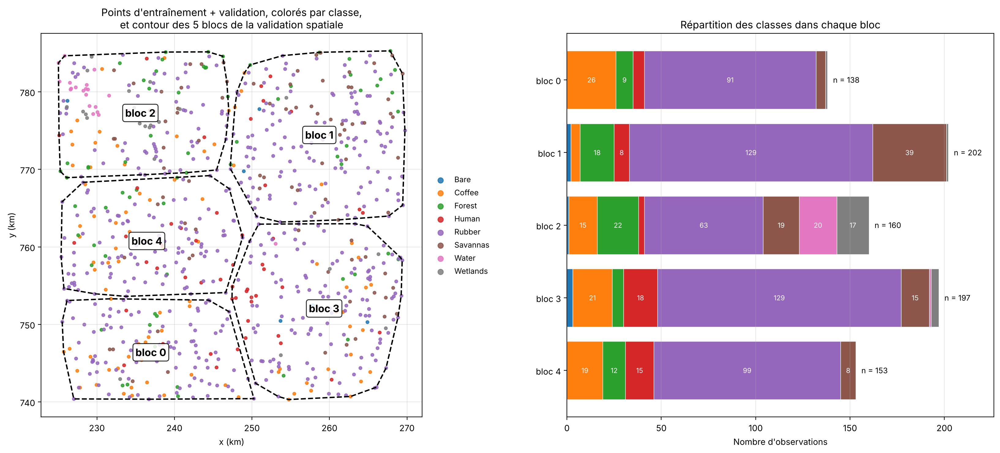

In [57]:
# Blocs et plis : entraînement + validation (le test n'est pas utilisé)
idx_dev = np.concatenate([idx_train, idx_val])
y_dev = np.concatenate([y_train, y_val])
coords_dev = data.loc[idx_dev, ["x", "y"]].to_numpy()
blocs_dev = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(coords_dev)
PLIS = {"aléatoire": list(StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(idx_dev, y_dev)),
        "spatiale": list(GroupKFold(n_splits=5).split(idx_dev, y_dev, groups=blocs_dev))}

# Carte des blocs : points colorés par classe, chaque bloc entouré, et répartition des classes par bloc

classes_dev = np.array([NOMS_CLASSES[k] for k in y_dev])
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(17, 7.5), gridspec_kw={"width_ratios": [1.15, 1]})

# Panneau 1 : projection des points, colorés par classe
for nom in NOMS_CLASSES:
    sel = classes_dev == nom
    ax.scatter(coords_dev[sel, 0] / 1000, coords_dev[sel, 1] / 1000, s=12, alpha=0.85,
               color=COULEURS_CLASSES[nom], label=nom.split(" ")[0])
# Contour de chaque bloc (enveloppe convexe de ses points) et numéro au centre
for b in range(5):
    pts = coords_dev[blocs_dev == b] / 1000
    enveloppe = pts[ConvexHull(pts).vertices]
    ax.add_patch(Polygon(enveloppe, closed=True, fill=False, ec="black", lw=1.6, ls="--"))
    cx, cy = pts.mean(axis=0)
    ax.text(cx, cy, f"bloc {b}", ha="center", va="center", fontsize=12, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="black", alpha=0.85))
ax.set_xlabel("x (km)")
ax.set_ylabel("y (km)")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1.01, 0.5), markerscale=1.8)
ax.set_title("Points d'entraînement + validation, colorés par classe,\net contour des 5 blocs de la validation spatiale")

# Panneau 2 : effectifs de chaque classe par bloc
effectifs_blocs = pd.crosstab(blocs_dev, classes_dev).reindex(columns=NOMS_CLASSES, fill_value=0)
bas = np.zeros(5)
for nom in NOMS_CLASSES:
    v = effectifs_blocs[nom].to_numpy()
    ax2.barh([f"bloc {b}" for b in range(5)], v, left=bas, color=COULEURS_CLASSES[nom], edgecolor="white", lw=0.5)
    for b in range(5):
        if v[b] >= 8:                                     # on n'écrit que les effectifs lisibles
            ax2.text(bas[b] + v[b] / 2, b, str(v[b]), ha="center", va="center", fontsize=8, color="white")
    bas += v
for b in range(5):
    ax2.text(bas[b] + 3, b, f"n = {int(bas[b])}", va="center", fontsize=9)
ax2.invert_yaxis()
ax2.set_xlim(0, bas.max() * 1.12)
ax2.set_xlabel("Nombre d'observations")
ax2.grid(axis="x", alpha=0.3)
ax2.set_title("Répartition des classes dans chaque bloc")

plt.tight_layout()
plt.show()

les points couvrent l’ensemble de la zone de façon assez uniforme, et les 5 blocs ont des tailles comparables (138 à 202 observations). Rubber domine dans tous les blocs, mais les autres classes sont inégalement réparties.

#### 7.5 Validation croisée aléatoire et spatiale des candidats

Deux candidats (F3 et mRMR k = 6), 5 plis aléatoires et 5 plis spatiaux (un bloc laissé de côté à chaque fois). Dans chaque pli, 15 % de la partie apprentissage servent à l'arrêt anticipé.

In [58]:
tf.get_logger().setLevel("ERROR")   # masque les avertissements de retraçage
CANDIDATS = [REFERENCE_F, "mRMR k = 6"]

def evaluer_pli(config, i_app, i_test, graine=0):
    """Entraîne sur une partie des plis et évalue sur le pli laissé de côté."""
    X_dev = data.loc[idx_dev, CONFIGS_F[config]].to_numpy(dtype="float32")
    norm = StandardScaler().fit(X_dev[i_app])
    X_app, X_test = norm.transform(X_dev[i_app]), norm.transform(X_dev[i_test])
    y_app = y_dev[i_app]
    # 15 % de la partie apprentissage servent à l'arrêt anticipé (stratifié si chaque classe a au moins 2 points)
    effectifs = np.bincount(y_app, minlength=N_CLASSES)
    strat = y_app if effectifs[effectifs > 0].min() >= 2 else None
    i_a, i_v = train_test_split(np.arange(len(i_app)), test_size=0.15, stratify=strat, random_state=graine)
    keras.utils.set_random_seed(graine)
    modele = construire_modele_F(X_app.shape[1])
    arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    modele.fit(X_app[i_a], y_app[i_a], validation_data=(X_app[i_v], y_app[i_v]), epochs=EPOCHS_MAX,
               batch_size=TAILLE_LOT, callbacks=[arret], verbose=0)
    pred = modele.predict(X_test, verbose=0).argmax(axis=1)
    vrai = y_dev[i_test]
    return {"f1_macro": f1_score(vrai, pred, average="macro", zero_division=0),
            "rappel_macro": recall_score(vrai, pred, average="macro", zero_division=0),
            "accuracy": accuracy_score(vrai, pred)}

resultats_vc = []
for config in CANDIDATS:
    for schema, plis in PLIS.items():
        for p, (i_app, i_test) in enumerate(plis):
            resultats_vc.append({"config": config, "validation": schema, "pli": p, **evaluer_pli(config, i_app, i_test)})
        f1s = [r["f1_macro"] for r in resultats_vc if r["config"] == config and r["validation"] == schema]
        print(f"{config:22s} | {schema:9s} | Macro-F1 = {np.mean(f1s):.3f} ± {np.std(f1s, ddof=1):.3f}")

resultats_vc = pd.DataFrame(resultats_vc)
recap_vc = resultats_vc.groupby(["config", "validation"])[["f1_macro", "rappel_macro", "accuracy"]].agg(["mean", "std"])

F3 Bandes + indices    | aléatoire | Macro-F1 = 0.361 ± 0.033
F3 Bandes + indices    | spatiale  | Macro-F1 = 0.288 ± 0.070
mRMR k = 6             | aléatoire | Macro-F1 = 0.356 ± 0.045
mRMR k = 6             | spatiale  | Macro-F1 = 0.212 ± 0.044


#### 7.6 Comparaison des deux validations

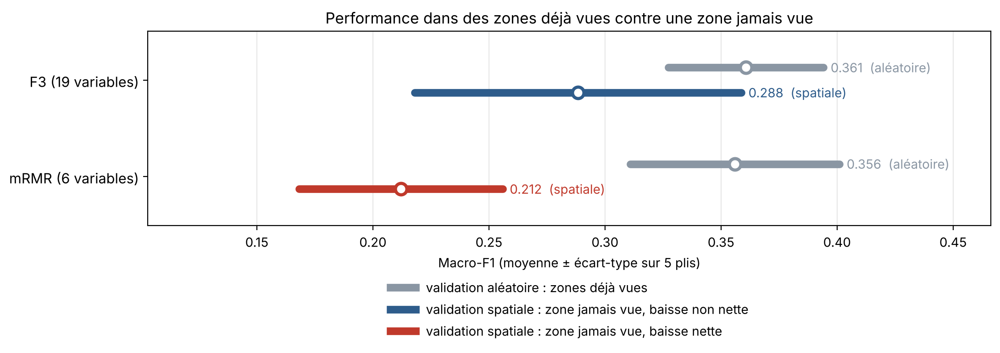

In [59]:
# Macro-F1 : validation aléatoire (zones déjà vues) contre validation spatiale (zone jamais vue)
etiquettes_cand = {REFERENCE_F: "F3 (19 variables)", "mRMR k = 6": "mRMR (6 variables)"}
fig, ax = plt.subplots(figsize=(11, 4.2))
for yi, config in enumerate(CANDIDATS[::-1]):
    m_a, s_a = recap_vc.loc[(config, "aléatoire"), ("f1_macro", "mean")], recap_vc.loc[(config, "aléatoire"), ("f1_macro", "std")]
    m_s, s_s = recap_vc.loc[(config, "spatiale"), ("f1_macro", "mean")], recap_vc.loc[(config, "spatiale"), ("f1_macro", "std")]
    c_s = "#c0392b" if (m_s + s_s < m_a - s_a) else "#2e5c8b"
    for m, s, c, dy, nom in [(m_a, s_a, "#8a96a3", 0.13, "aléatoire"), (m_s, s_s, c_s, -0.13, "spatiale")]:
        ax.plot([m - s, m + s], [yi + dy, yi + dy], color=c, lw=6, solid_capstyle="round")
        ax.plot(m, yi + dy, "o", color="white", mec=c, mew=2.5, ms=9)
        ax.text(m + s, yi + dy, f"  {m:.3f}  ({nom})", va="center", fontsize=10, color=c)
ax.set_yticks(range(len(CANDIDATS)), [etiquettes_cand.get(c, c) for c in CANDIDATS[::-1]], fontsize=11)
ax.set_xlabel("Macro-F1 (moyenne ± écart-type sur 5 plis)")
ax.margins(x=0.28, y=0.3)
ax.grid(axis="x", alpha=0.3)
ax.legend(handles=[Line2D([0], [0], color="#8a96a3", lw=6, label="validation aléatoire : zones déjà vues"),
                   Line2D([0], [0], color="#2e5c8b", lw=6, label="validation spatiale : zone jamais vue, baisse non nette"),
                   Line2D([0], [0], color="#c0392b", lw=6, label="validation spatiale : zone jamais vue, baisse nette")],
          loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=1, frameon=False, fontsize=10)
ax.set_title("Performance dans des zones déjà vues contre une zone jamais vue")
plt.tight_layout()
plt.show()

les deux modèles se valent dans une zone connue (0,361 contre 0,356), mais dans une zone nouvelle, celui à 6 variables perd beaucoup plus que celui à 19 variables. C’est pour cela qu’on garde F3.

#### 7.7 Configuration finale de l'ANN

In [60]:

import json

VARIABLES_ANN_FINAL = CONFIGS_F[REFERENCE_F]

CONFIG_ANN_FINAL = {
    "modele": "ANN",
    "architecture": ARCHI_F,
    "couches_cachees": ARCHITECTURES[ARCHI_F],
    "activation": ACTIVATION_F,
    "optimiseur": "SGD + Momentum",
    "taux_apprentissage": LR_F,
    "momentum": MOMENTUM_F,
    "taille_lot": TAILLE_LOT,
    "epochs_max": EPOCHS_MAX,
    "arret_anticipe": {"surveille": "val_loss", "patience": PATIENCE, "restore_best_weights": True},
    "regularisation": "arrêt anticipé seul",
    "desequilibre": "sans correction",
    "variables": VARIABLES_ANN_FINAL,
    "n_variables": len(VARIABLES_ANN_FINAL),
    "standardisation": "StandardScaler appris sur l'entraînement",
    "graines": GRAINES,
    "seed_partition": SEED_PARTITION,
    "validation_croisee_dev": {                     # scores sur entraînement + validation (5 plis), test non utilisé
        schema: {"f1_macro_moyenne": round(float(recap_vc.loc[(REFERENCE_F, schema), ("f1_macro", "mean")]), 3),
                 "f1_macro_ecart_type": round(float(recap_vc.loc[(REFERENCE_F, schema), ("f1_macro", "std")]), 3)}
        for schema in PLIS},
}


# Rappel des performances en validation de la configuration retenue (5 graines)
perf = resultats_F.loc[resultats_F["config"] == REFERENCE_F, ["val_f1_macro", "val_recall_macro", "val_accuracy",
                                                              "ecart_f1_train_val"]].agg(["mean", "std"])
print(json.dumps({k: v for k, v in CONFIG_ANN_FINAL.items() if k != "variables"}, ensure_ascii=False, indent=2))
print("Variables :", ", ".join(VARIABLES_ANN_FINAL))
display(perf.round(3))

{
  "modele": "ANN",
  "architecture": "ANN-3",
  "couches_cachees": [
    128,
    64,
    32
  ],
  "activation": "gelu",
  "optimiseur": "SGD + Momentum",
  "taux_apprentissage": 0.01,
  "momentum": 0.5,
  "taille_lot": 32,
  "epochs_max": 200,
  "arret_anticipe": {
    "surveille": "val_loss",
    "patience": 20,
    "restore_best_weights": true
  },
  "regularisation": "arrêt anticipé seul",
  "desequilibre": "sans correction",
  "n_variables": 19,
  "standardisation": "StandardScaler appris sur l'entraînement",
  "graines": [
    0,
    1,
    2,
    3,
    4
  ],
  "seed_partition": 42,
  "validation_croisee_dev": {
    "aléatoire": {
      "f1_macro_moyenne": 0.361,
      "f1_macro_ecart_type": 0.033
    },
    "spatiale": {
      "f1_macro_moyenne": 0.288,
      "f1_macro_ecart_type": 0.07
    }
  }
}
Variables : B1, B2, B3, B4, B5, B6, B7, B8, B9, B10, NDVI, EVI, NDRE, SAVI, NDMI, NDWI, MSI, BSI, BI


,val_f1_macro,val_recall_macro,val_accuracy,ecart_f1_train_val
mean,0.389,0.377,0.645,0.054
std,0.041,0.023,0.011,0.034
